# EXP_06. ¿Una fecha de pico NDVI mejor soportada mejora la predicción?

**CRISP-DM: preparar, modelar y evaluar.** Un máximo aislado puede depender del
muestreo. Hipótesis acotada: sustituir **solo la fecha del máximo crudo** de NDVI
Planet por la fecha del máximo suavizado, con guardas explícitas de soporte.
No añadimos variables ni cambiamos municipio, Ridge, ventana o particiones.

**Lector retrospectivo sin ajustes:** reconstruye la curva y la fecha de 197
parcelas desde capturas; verifica 100 elecciones de alpha a partir de 500 scores
guardados; puntúa 6,900 OOF guardadas. No ajusta modelos ni recalcula errores
interiores ni genera los 59 rendimientos ocultos.

Factibilidad original: **2/oct/2026**, solo X. Experimento original: **6/oct**;
adaptación de lectura: **8/oct**. No se vuelven a declarar decisiones como si
fueran nuevas. El registro previo es interno; no elimina la exploración adaptativa.

**Recorrido:** capturas → curva diaria → guardas → una columna → comparación → decisión.
Basta este `.ipynb`, sin Git, Drive, ZIP ni otro cuaderno. Dos bloques técnicos
plegados; cálculos científicos visibles. La prueba local no es prueba real en Colab.

## 1. Preparación y trazabilidad

| Entrada incorporada | Qué hacemos aquí | Qué no hacemos |
| --- | --- | --- |
| 26,255 capturas, cinco columnas Planet, abril–octubre de 2025 | Media diaria, mediana móvil y fecha soportada | Extraer píxeles ni leer otros sensores |
| Seis variables E2 y 138 etiquetas separadas | Sustituir solo una columna | Rehacer las otras cinco variables |
| Roles, 500 scores y 6,900 OOF originales | Verificar selector y recalcular métricas | Reentrenar ni reconstruir scores interiores |
| Controles de salida | Contrastar después del cálculo | Usarlos para construir la variable |

El recorte de capturas se creó el **8/oct** desde el CSV Planet original,
previamente comprobado byte a byte contra DataSet.zip. No es un archivo sellado
el 2/oct: conserva procedencia y hash propio. Los otros insumos mantienen bytes
históricos. SHA-256 detecta cambios, no certifica por sí solo una fecha.
No se filtran nubes ni duplicados; no se rellena NDVI ausente.

In [1]:
# @title Preparación de Colab: tres bibliotecas, sin descargar datos { display-mode: "form" }
"""Preparación explícita de Colab y descarga verificada, sin cambiar cálculos científicos.

Este módulo usa la biblioteca estándar hasta que se solicita preparar Colab o descargar
el ZIP. Se incrusta completo en el notebook para no depender de un clon del proyecto.
"""

from __future__ import annotations

import hashlib
import importlib
import importlib.metadata as metadata
import os
import re
import subprocess
import sys
import tempfile
from pathlib import Path


REQUERIDOS_AUDITORIA = ("numpy", "pandas", "matplotlib")
MODULOS_DISTRIBUCIONES = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "pyshp": "shapefile", "shapely": "shapely", "pyproj": "pyproj", "gdown": "gdown",
    "pillow": "PIL", "python-dateutil": "dateutil", "beautifulsoup4": "bs4",
    "scikit-learn": "sklearn", "pysocks": "socks", "typing-extensions": "typing_extensions",
}


class ReinicioColabRequerido(RuntimeError):
    """Una instalación cambió una biblioteca que ya estaba cargada en la sesión."""

    def __init__(self, cambios: list[str], modulos_cargados: list[str]):
        self.cambios = cambios
        self.modulos_cargados = modulos_cargados
        super().__init__(
            "Las versiones se prepararon, pero ya había módulos cargados que cambiaron: "
            + ", ".join(modulos_cargados)
            + ". En Colab selecciona Entorno de ejecución > Reiniciar sesión y después "
            "Ejecutar todas. No se reinicia ni se mata la sesión automáticamente."
        )


def _perfil_fijado(perfil: str) -> dict[str, str]:
    versiones = {}
    for nombre, version in re.findall(
        r"^([A-Za-z0-9_-]+)==([^\s;]+)", perfil, flags=re.MULTILINE,
    ):
        clave = nombre.lower().replace("_", "-")
        if clave in versiones:
            raise ValueError(f"Paquete repetido en el perfil: {nombre}")
        versiones[clave] = version
    if not versiones:
        raise ValueError("El perfil de uv no contiene versiones fijadas.")
    return versiones


def versiones_requeridas(
    perfil: str, nombres: tuple[str, ...] = REQUERIDOS_AUDITORIA,
) -> dict[str, str]:
    """Lee las versiones de las raíces realmente utilizadas en esta auditoría."""
    fijadas = _perfil_fijado(perfil)
    faltantes = [nombre for nombre in nombres if nombre not in fijadas]
    if faltantes:
        raise ValueError("Faltan paquetes del cuaderno en el perfil uv: " + ", ".join(faltantes))
    return {nombre: fijadas[nombre] for nombre in nombres}


def _version_o_ausente(nombre: str, consultar_version) -> str | None:
    try:
        return consultar_version(nombre)
    except metadata.PackageNotFoundError:
        return None


def _modulo_cargado(nombre: str, modulos) -> bool:
    raiz = MODULOS_DISTRIBUCIONES.get(nombre, nombre.replace("-", "_"))
    return any(clave == raiz or clave.startswith(raiz + ".") for clave in modulos)


def _comprobar_importaciones(versiones: dict[str, str]) -> None:
    """Prueba importaciones y operaciones pequeñas; no entrena ni lee datos del reto."""
    for nombre, esperada in versiones.items():
        modulo = importlib.import_module(MODULOS_DISTRIBUCIONES.get(nombre, nombre))
        version_cargada = getattr(modulo, "__version__", None)
        if version_cargada is not None and str(version_cargada) != esperada:
            raise ReinicioColabRequerido([], [nombre])
    import numpy as np
    import pandas as pd

    if not np.isclose(np.array([1.0, 3.0]).mean(), 2.0):
        raise RuntimeError("No pasó la comprobación mínima de NumPy.")
    if pd.DataFrame({"x": [1, 2]}).shape != (2, 1):
        raise RuntimeError("No pasó la comprobación mínima de pandas.")


def _avisar_incompatibilidad_numba(informar) -> None:
    """Aviso acotado: este notebook no usa ni modifica Numba."""
    try:
        requisitos = metadata.requires("numba") or []
        from packaging.requirements import Requirement

        numpy_version = metadata.version("numpy")
        for texto in requisitos:
            requisito = Requirement(texto)
            if requisito.name.lower() != "numpy":
                continue
            if requisito.marker is not None and not requisito.marker.evaluate():
                continue
            if numpy_version not in requisito.specifier:
                informar(
                    f"Aviso del entorno de Colab: Numba declara {requisito}, pero NumPy es "
                    f"{numpy_version}. Este cuaderno no usa Numba ni lo actualiza. "
                    "La verificación cubre sus bibliotecas, no todos los paquetes de Colab."
                )
    except (metadata.PackageNotFoundError, ImportError):
        return


def preparar_colab(
    perfil: str, *, en_colab: bool, habilitar: bool = True,
    consultar_version=metadata.version, modulos=None, ejecutar=subprocess.check_call,
    informar=print, verificar_importaciones=None,
) -> dict:
    """Instala solo raíces distintas/faltantes en Colab, con dependencias restringidas por uv.

    Las funciones inyectables permiten probar instalación, versiones y reinicio sin red.
    En local no se llama a pip ni se modifica el entorno: lo prepara uv.
    """
    esperadas = versiones_requeridas(perfil)
    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    cambios = [f"{nombre}=={version}" for nombre, version in esperadas.items()
               if instaladas[nombre] != version]
    if not en_colab:
        informar("Entorno local: no se instala nada desde el cuaderno; se utiliza uv.")
        return {"estado": "local_sin_instalar", "cambios": [], "instaladas": instaladas,
                "reinicio_requerido": False}

    informar("Preparación de Colab: Python y paquetes se comprobarán antes de leer datos.")
    informar("Plan: " + (", ".join(cambios) if cambios else "sin instalaciones necesarias"))
    if cambios and not habilitar:
        raise RuntimeError(
            "El perfil difiere y PREPARAR_COLAB está desactivado. Actívalo y vuelve "
            "a ejecutar esta celda, o prepara manualmente las versiones impresas."
        )

    fijadas = _perfil_fijado(perfil)
    modulos = sys.modules if modulos is None else modulos
    cargados_antes = {nombre for nombre in fijadas if _modulo_cargado(nombre, modulos)}
    versiones_antes = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in cargados_antes
    }
    if cambios:
        with tempfile.TemporaryDirectory(prefix="agrocebada-colab-perfil-") as carpeta:
            restricciones = Path(carpeta) / "perfil-uv-constraints.txt"
            restricciones.write_text(perfil, encoding="utf-8")
            comando = [sys.executable, "-m", "pip", "install", "--only-binary=:all:",
                       "--disable-pip-version-check", "--constraint", str(restricciones),
                       *cambios]
            informar("Se instala únicamente el plan; dependencias necesarias limitadas por uv.")
            try:
                ejecutar(comando)
            except (subprocess.CalledProcessError, OSError) as error:
                raise RuntimeError(
                    "No se pudo preparar el perfil binario. No se ejecutará la auditoría "
                    "con otras versiones. Revisa el error de pip y reinicia la sesión "
                    "si la instalación quedó a medias."
                ) from error

        importlib.invalidate_caches()
        cargados_cambiados = sorted(
            nombre for nombre in cargados_antes
            if versiones_antes[nombre] != _version_o_ausente(nombre, consultar_version)
            or any(cambio.startswith(nombre + "==") for cambio in cambios)
        )
        if cargados_cambiados:
            raise ReinicioColabRequerido(cambios, cargados_cambiados)

    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    divergentes = [nombre for nombre, version in esperadas.items()
                  if instaladas[nombre] != version]
    if divergentes:
        raise RuntimeError("El perfil no coincide tras prepararlo: " + ", ".join(divergentes))
    comprobar = _comprobar_importaciones if verificar_importaciones is None else (
        verificar_importaciones
    )
    comprobar(esperadas)
    # Evita inspeccionar el entorno verdadero en pruebas con proveedores de versiones inventados.
    if consultar_version is metadata.version:
        _avisar_incompatibilidad_numba(informar)
    informar("Perfil requerido e importaciones comprobados; no se garantiza todo el entorno Colab.")
    return {"estado": "colab_instalado" if cambios else "colab_existente", "cambios": cambios,
            "instaladas": instaladas, "reinicio_requerido": False}


def validar_dataset(ruta: Path, sha256_esperado: str, bytes_esperados: int) -> Path:
    """Rechaza tamaño o huella incorrectos antes de que se abra el ZIP."""
    ruta = Path(ruta)
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe el archivo de entrada: {ruta}")
    if ruta.stat().st_size != bytes_esperados:
        raise ValueError(f"Tamaño incorrecto de {ruta.name}: se esperaban {bytes_esperados} bytes.")
    huella = hashlib.sha256()
    with ruta.open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            huella.update(bloque)
    if huella.hexdigest() != sha256_esperado:
        raise ValueError(f"SHA-256 incorrecto de {ruta.name}; no se usará este archivo.")
    return ruta


def obtener_dataset(
    destino: Path, *, file_id: str | None = None, sha256_esperado: str,
    bytes_esperados: int, permitir_descarga: bool, descargar=None,
) -> Path:
    """Usa caché validada o descarga explícita a temporal; publica solo bytes verificados.

    Una copia local incorrecta nunca se sustituye silenciosamente. Una descarga rechazada
    queda en cuarentena para diagnóstico; no se cambian permisos, cuentas ni credenciales.
    """
    destino = Path(destino).expanduser()
    if destino.exists():
        return validar_dataset(destino, sha256_esperado, bytes_esperados)
    if not permitir_descarga:
        raise FileNotFoundError(
            "No está el ZIP original. En local, coloca DataSet.zip en data/raw/ o indica "
            "RUTA_DATASET. La descarga solo se habilita explícitamente."
        )
    if file_id is None or not re.fullmatch(r"[A-Za-z0-9_-]{10,}", file_id):
        raise ValueError(
            "Falta el ID de Drive del ZIP original autorizado. Configura ID_DRIVE_DATASET "
            "(no el ID del notebook), o proporciona una copia local verificada."
        )
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    destino.parent.mkdir(parents=True, exist_ok=True)
    descriptor, nombre_temporal = tempfile.mkstemp(
        prefix=destino.name + ".", suffix=".part", dir=destino.parent,
    )
    os.close(descriptor)
    temporal = Path(nombre_temporal)
    try:
        if descargar is None:
            import gdown

            descargar = gdown.download
        resultado = descargar(
            id=file_id, output=str(temporal), quiet=False, use_cookies=False,
        )
        if resultado is None:
            raise RuntimeError("Drive no entregó un archivo descargable.")
        validar_dataset(temporal, sha256_esperado, bytes_esperados)
        # Mismo directorio/sistema de archivos: la creación del enlace publica el
        # archivo completo y falla atómicamente si otra ejecución ganó la carrera.
        # No usamos exists() + replace(), que permitiría sustituir una aparición
        # concurrente entre ambas operaciones.
        try:
            os.link(temporal, destino)
        except FileExistsError:
            validar_dataset(destino, sha256_esperado, bytes_esperados)
        except OSError as error:
            raise RuntimeError(
                "Este destino no permite publicar mediante enlace atómico sin reemplazo. "
                "Usa una carpeta local de la sesión; no se sobrescribirá otro archivo."
            ) from error
        temporal.unlink()
        return destino
    except Exception as error:
        if temporal.exists():
            cuarentena = temporal.with_suffix(".rechazado")
            os.replace(temporal, cuarentena)
            detalle = f" Archivo recibido conservado para revisión en {cuarentena.name}."
        else:
            detalle = ""
        raise RuntimeError(
            "La descarga no quedó publicada como DataSet.zip: comprueba enlace, permisos, "
            "cuota y coincidencia de tamaño/SHA-256." + detalle
        ) from error


In [2]:
PREPARAR_COLAB = True
import importlib.util
import sys
try:
    EN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    EN_COLAB = False
if sys.version_info[:2] != (3, 13):
    raise RuntimeError("Este lector requiere Python 3.13 en local y Colab.")
REQUIREMENTS_COLAB = "affine==3.0.1\n    # via rasterio\nattrs==26.1.0\n    # via\n    #   affine\n    #   rasterio\nbeautifulsoup4==4.15.0\n    # via gdown\ncertifi==2026.7.22\n    # via\n    #   pyproj\n    #   rasterio\n    #   requests\ncharset-normalizer==3.5.2\n    # via requests\nclick==8.5.0\n    # via rasterio\ncloudpickle==3.1.2\n    # via joblib\ncolorama==0.4.6 ; sys_platform == 'win32'\n    # via tqdm\ncontourpy==1.4.0\n    # via matplotlib\ncycler==0.12.1\n    # via matplotlib\nfilelock==4.0.12\n    # via gdown\nfonttools==4.66.1\n    # via matplotlib\ngdown==5.2.2\nidna==3.20\n    # via requests\njoblib==1.6.0\n    # via scikit-learn\nkiwisolver==1.5.1\n    # via matplotlib\nmatplotlib==3.11.2\nnarwhals==2.26.0\n    # via scikit-learn\nnumpy==2.4.4\n    # via\n    #   agrocebada-uv\n    #   contourpy\n    #   matplotlib\n    #   pandas\n    #   rasterio\n    #   scikit-learn\n    #   scipy\n    #   shapely\npackaging==26.3\n    # via matplotlib\npandas==2.2.3\n    # via agrocebada-uv\npillow==12.3.0\n    # via matplotlib\npyparsing==3.3.3\n    # via\n    #   matplotlib\n    #   rasterio\npyproj==3.8.0\npyshp==3.1.6\npysocks==1.7.1\n    # via requests\npython-dateutil==2.9.0.post0\n    # via\n    #   matplotlib\n    #   pandas\npytz==2026.5\n    # via pandas\nrasterio==1.5.2\nrequests==2.34.2\n    # via gdown\nscikit-learn==1.9.1\n    # via agrocebada-uv\nscipy==1.18.0\n    # via\n    #   agrocebada-uv\n    #   scikit-learn\nshapely==2.1.2\nsix==1.17.0\n    # via python-dateutil\nsoupsieve==2.10\n    # via beautifulsoup4\nthreadpoolctl==3.7.0\n    # via scikit-learn\ntqdm==4.70.1\n    # via gdown\ntyping-extensions==4.16.0\n    # via beautifulsoup4\ntzdata==2026.5\n    # via pandas\nurllib3==2.8.0\n    # via requests\n"
VERSIONES = {'numpy': '2.4.4', 'pandas': '2.2.3', 'matplotlib': '3.11.2'}
assert hashlib.sha256(REQUIREMENTS_COLAB.encode()).hexdigest() == '8f18975fe344552700b5efe887bc0ede3128554a73f1457649652b35eb9cd95e'
preparacion = preparar_colab(REQUIREMENTS_COLAB, en_colab=EN_COLAB, habilitar=PREPARAR_COLAB)
print(preparacion["estado"])

Entorno local: no se instala nada desde el cuaderno; se utiliza uv.
local_sin_instalar


In [3]:
import base64
import hashlib
import importlib.metadata as metadata
import io
import json
import platform
import zlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FECHA_EJECUCION_UTC = datetime.now(timezone.utc).isoformat()
assert all(metadata.version(k) == v for k, v in VERSIONES.items())
print("Python:", platform.python_version(), "| Ejecución UTC:", FECHA_EJECUCION_UTC)
display(pd.DataFrame([{"biblioteca": k, "version": v} for k, v in VERSIONES.items()]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Python: 3.13.13 | Ejecución UTC: 2026-10-08T16:06:58.820817+00:00


,biblioteca,version
0,numpy,2.4.4
1,pandas,2.2.3
2,matplotlib,3.11.2


In [4]:
# @title Insumos con tamaño y SHA-256; sin motores predictivos ocultos { display-mode: "form" }
INSUMOS_INCRUSTADOS = {'variables_fuente': {'ruta_local': 'data/exp_06_pico_soportado/variables_fuente.csv', 'sha256': '62e39ba23fb33f8834e92943f9714fea38aa731da079e0431d707aab13151595', 'bytes': 977024, 'uso': 'variables_e2_guardadas', 'origen': 'insumos_experimento_v4.zip::variables.csv', 'bytes_zlib_base64': '...'}, 'etiquetas': {'ruta_local': 'data/exp_06_pico_soportado/etiquetas.csv', 'sha256': 'dd43b5b0468f56eaf5c58b1a055e8b7d8039a3037902564d6e65dce1a3941cc1', 'bytes': 1765, 'uso': 'etiquetas_oficiales', 'origen': 'insumos_experimento_v4.zip::etiquetas.csv', 'bytes_zlib_base64': 'eNpNVM2OmzEIvPdZosjY/JjjqrvaRmqTqtp73v8tarzjwI35ADPA8N3en38fv2+fj/vj8u/j/n77c/u4fz2eX89fbz/ePn8+W6PLuArsfuGrDgBejgZbLnIlBdAVxQ5gJX0uhxzgCxiiqC1AsHeR4xgLtOPhBSbKk1z6VRnAlscnwCz1yZNlb8mlU2QgvfdCrI+SsXtExa6RjqgRKcczgiUbAC9iyB8SvYDXKKMYc9nI5pYFmVYyYpgzniUHxFrio3E+QbMk+9qIoIJQiZKRzwpnhsQOX0G6QENHYmU8UopI7JBBS2OH0gH6KjKPJ/YmBxT2asUu72qQZ8jJWo7K6qIspn4cpRELunayZ5Ywz5dm0cIMiaPXGY8quM5NHCKZRUneyl59k0K+h/gF4nMrUvbCxP1VndqeG2zKp2hfG8NOUVLbrBRAcgX0fXkDYObUaV8bOqHva5sAUdI6QM8yxMXeOoadMibypNjpNV3qPWPWPfWXzSGrA+LRhle7hV7R+QhO0wFiDISHR8zB0dTgVBztU+OTY6XdkcqiEYQVZfbhIZ3zN0ecYqJ1ePl97xZz41wnSZE+7WPD0kmC/EQ9kRpmJX//CxGlwUoRpftyMaN1VHK0RVoUoWVVuueA1texvTrROhMt/0ha5/aKsvwZkcXPiI4jihMyLCYxMAmLt8bxeF4ozS00lJxU9LgvC39MmvHnacdT5jI9f7Lko9yGc67OY0U4RnLNfe3zW/P+D7J+efM='}, 'descriptores_control': {'ruta_local': 'data/exp_06_pico_soportado/descriptores_control.csv', 'sha256': '2dad354161615a043651c178781c48543e660febac99191f200b9ec80f9c528d', 'bytes': 32359, 'uso': 'control_posterior', 'origen': 'insumos_experimento_v4.zip::descriptores.csv', 'bytes_zlib_base64': 'eNq1XduOJDluffe3JBIiJVLSo2EDiwUMr/+gUNNdO1vYnq6dvgzWi/l4U6QUmQoxInsa7R5EZkxWVQZDF14ODxl//s+n//nLf/35T3/5779cPj69f33+/PT20+eXT789v3/7PD756+vH1y/6v399/fC8ffzu7ePTb8+f7Dfs89eP71/fvTw9f/388vHLy9Pb08e3/tfyw4/vf3t9+uvXl0/PT5+eP/7cPvr1+en9y2f5ord3r++f7YOfv2CwMwhhXPPp/dd/fHh99/xeTl/++fzui1zuH6/v3p4+v/3j7dMXkfbp/dv/Xp4/vvvbV/n+D28/ff3w9kRBJbXf3O7r6fPX599e/zX+Rn/4y8vnly/PIv/ru9f1Y7kF/eyn588vH14/vjz9CuHy/ItI9OXr+8vXX3769PxBLnZ59+mr3P3rv379+vryqX+9ffb+5dPLu7/dhHx7kr959/eXL+23Tcj5Y/kD+/hjvxlvYrYb+Xz529eXJu/zP19/ebM//CxC2+i8bPe1/1xvzK6y/eq/fr37PxHj8vJZx7cNyDjv4/xv//6n/3gKAS4Q+VKzvoVLrPISLonsDBmvdOlvyCBHuoQrcE7h7h/KZxwryFsqXFO9+3dp/0CvkNoFLvVCl7e/661M49sFQpGETCBqv19MoGxnkOUL28s4RJhKjjBA90I0oQkA6k4yWa3UhKN21s7xUppwNiN9Jb6ZnF2+KILhJYO+hYuMSfvL3M9QpNSXcYQrIt+LF9ooUQ6TKGTypfkzGzn5ahUuXvL5yCURqVwgkL7LH0QbOrQzJLzoyzhEtFDqPCQygTlO4upniWi+BRMN2jWTDFqbNJnYE+HIphX7tKY4pjWZbPGiL+MQ2VJM+2FjSNNY6rRS4PtbyCobXmoYcwpwPm4sMsGlJH1TmfTvyM4wtQ0gL+OQFUdF15iOFk4DWPrIyLchjKvz2dWzXratZr16m5e2rIqdoezKkq45VcYUOACFBPrpOEScXPN+FjlXvB+pqAusxnmkoPC1UIiZ5CdFriFfneHK83aSqU1tHcrvq4potyQ6VO7p7e/9JmTZxXSprG/bpiWwMyS+6Ms42sqL66YI0/ovuvKIpg95qBO22RXp8Hx828AGG98uk75lO2tTK8u3jWnSVRepLaoUeVloiSLv9Yf8sqzXS5aVgTo0LP+Z8vhZtMfzh+l/fj9WKzKeqoe56+EUTMxkZ3LLJZrOK7lNeZl1RRsqKtOIhqzLE2heBtvwQdXl2YbQjPGdaflJzPYXsfUfTn70+8GAt8WBsmhR3+ROki1osLM24KkZEx1y0486urnsNpJ8xpHmpdg3V9NfKj3LcTzcRxK2JR0vperbJmHb8Eltnlo82g4REUzTTAoptJ+kGmp1zF3hsf/b5jlenhB139fYt//YOdx3Dje9KC9me1X55AjLbgfAvTmRAS3DhIja7bqQTlUhJFXPZRjfVLaRUWmwqDegbyhTgNGsSFj3cp0/0+mstBu/PlZ5SJfN+h5JR6ZlYtcyybZyYjtrQ9THyY62tBD3kqUCeRkrjmHVMtiWyLAhYkTPRGMzbzy8lrp5LepGpSaarng72qDRuoNn6xb6vqD5s5vXwkO6arb3RL1kGzocQ2dWJlU7w1R1YvVNXmV7BV32wXEP8rpP5zu5Kelt2cGDXVB0K1YcO7Ir6X4mkom2QrkJRB27hItcFOdlqAYv1OC5LbXrj+bs1e/QH6Y4QF3BJm40ZZ36GUJz2q5ilSOXJINIsnOjfjwO9VqD496s9xVw5xVCIVFF2Fxc0ZniruVmU6+TqlSPTB00kdFuNe9sNgZbEnnY7Dx2k57JSMtaaM6AWELxFXKUUWcZfvsB6hmqKaq06CM2j3s/USp7Dgyi81MRr0UcKaR8jRlv/8D8SZWMfdFBjbmqqXBzJkVpmjO5KnDxfHSNlGWNJJ7XDY6tv4UE5dS/QNtSlcYw2s6XG7Odj6owaTt0V5k70e6ueRroWuhkFhov6hqcSWARCainhrflKH6ELUfxWStdY5SoLctW4yg+Du5d2ppXHT6v0K6O9tsMSrnGIjGOBH7EhLKXscRrhoSF+iuaFwwq5JhgMKW1TarZnpqG7YHNAwLfDRdJ6j7wI06w2OiC02aj2xAPHxJODQ+2ya0W7eisqoAWJdNRZOVsZW/55ejEDzhFVg+EY98q1j5ua2QF2Yv66jrXUJIX28ilbpHVmVrHtkHb5i36LsLUoWPQzGLzwtoYiALIBQJTKOaJm6HUlVlIg63oaEYNYEQVMmZZdzWmptkzdwWi193GcKdCihuPttV2FI/q5pKlPgdbav9Eak+HVBh7uJ6PUzXnvw4QJg/zZ6MmJ/oyjgbAOJjCHN3VbNqtusFxNTTGtAucyCYqBGSwCujbFh3Llu7Rcb7oC7ZJ7f687blp7ZiqhenDNFQtDBslwpzp2gguNnQLM51Jy4txkjA3rg4g5XqAWtWx1M92YUTfwcrdwULD0fTNbGc60ro57ZypNpo7F0uE4zZo6stA7nbqgRPYfBZZag3o0O2XTItRtbPFZha9dK1r0BOJxtzJ/krfH4rFpC5ULt2TIhOJ2c6aJujqIPYAHWrIi0ufIS4y4hw8Dt+vXaoMFONsU0ZyIzPRq7bYJFbUFxPNBsxDrAIvOr+U7IW1Q6/i8OePJGMfIi0nECku24CopnUgMVp8kWzxfysqGoemx67ph4XkbiFlgMQPvjbcOKbSnEnmsvdBSuHFnufZxhuokQJNsaUsihYDpwopoTg3ctNY+Squx52f3CY8dh9kKL+dDxINxyrDlnawiJOdSTDZPCkxUoGb+ybbKKhbF7ZDkS1c7gJL3sPRifMeZxNjxlVcVUolyhJp8V3B6y7ah4YDg8pIHXIyBb7dxFF4Uro/qA58gWsQ+WXCITd9GMnx7E34FNeAmTDsoxK+yhe1SMf8+4ZZ5GvOjHE7dCH1Gdhc+0n4FA5crXTias2732xhWrVELUy7SPrO1epY4pmST+AixTxsITSYExryE8YQ1j79Yb8kEnFwsa005jWdy4K+5sRDzYm6M5sXakoIN3iofUkdOvHMAKdomgeG1zQjZ3LFhuW00EnBWwy0OJosO2aB8EOeHINyB+FTB9Fm4/K74pLvXj5+/vrp+f3b2c+OTE/q8QaNewkbmqS7pM1Ie5HtJ++GvBkMmBXBTlTbnMk0px6u2YpONoLHujL5MNYd2DFHOdFByokWo0wwKcXAd1aFxurOf9xEJ4OkoWcKtx1JYah2WajlmqtodCpVNj0WznvTqHDcLjYbcNxuPYgCvIoWkWWSW3AUG9orajBJiCJur/2rltQBE8v2S/NkJx8/WWql0rDgPKB/PfMSO3XNa1JdrZK4kNkN2mkT5jwdlsq5J7vihVDLalZ6+FFLcJ1X3vRa8/zOxKkKHdTQEYTuvYoLbd6rh4hDXRVsCEtoRHM6eAQgN8w3nXphZCLpHOIdSlV7aAQNii6ytEoDwkIVFyyxXNl+gEBdEcvYldU3i3kZ0pB5xgrUsBFlrhiDvqphS80HEXtXQexU7IatiZm6Xcv3S5HAAM6hrcce6lbNcdlE9MU9ozRntbPl22GN8EAvNSmkowFGw9LSwNJ4Cwq4Q6+kI5kUgPWVOs3bIVjMMiOcdAOuSxwZbbE935l9OtavFLvCwqGwupVCO7vLqdjRNpei2GtMnWbXom90nHzIBwE0mZ2BMAzNHi1uXgXAFUVvFvkNCePVBZt3P9e0KqG65iih4t6ppGvBDLKMZclybvhKzdcdXjHQYrpL58+OGZGtkzDyqHYX3M+W/O4uV6oDvMO/+MQNah68mX4I3xNYihAgX9C2k37PWNa0LetJXPGBV3FrCU5U6aawch7iSsD/HdJmN/+xZbYoKXqgbwZucNfB3zTGERyh8Q46gHCuhEtfwgObjbDhn3BgrkquK7IR70cPLOKcHfXsMEvwwQazeEdNRLyzpWRnF81SjqONWlkVa5m3kn4GEVyr2nP9ZDb+D88197xLGO5f2mxtOgCx4opzyzQvBKeEgG5IUS0X3WzUWfaXoQeOMEZycwMizpCHHQMjEm+0OmBf8uySfvsWfZ9OLKObVG1OUj1I82jYERkWLFvUEXkb90aE6Bb7SBYLpuuIqdMWU1u0UPIa/FQnA5CdDMCa4B27s3YDfjprZrkLDANeh2LWs4XgkuKqNBLVFRHl6s1fU8zY2Wj8HauferJqOHSYh7+hZ43msuO6IM2um3m+CAt/LnGpO3i5BeNDmxh3CU3THbsPbPkUCIPMhGUoOyydisNXTcO23JflU9ZU/i53Yno4570vjLoHUC/XN2nTxT/aJ+JsrMXcR32gBbWjBTM8HUamMjpQFuWyB+QIsMGrEPV2LpnHYPMjSJqHZRmB0BhssDOkZlnkxVIfuKVyecc5MYMdXTun374BPBYjHi3PaiqnDpXDm6/GB4EQapwjsQAssU/BOjZz2VJm56Y2B58OyJ0O6MA6yKqDcTYShvHkkJwEXvt2+ha8R1muqe/W5CXwGuKlmR87VAWv5lW04rIZHDbdZeeDPpisllb24nvsk7WyDsWNXkkXaZbDItk5e7XpZLqbxjOlnKNP54NuLlaqkqU5d7TDYJ/lehTe107/OTNdOemmL3UE93HAIHrW/KPYtn2EwSctvPJJ2YEfliWHIYvSqKVkTiGl2vyEkq8ZSoiYC5dC2BiSqbO+sMfK5diQ9HsYGfg8YGHcMO2xLwDjtSInlMkLhRHjLpPs8dR2MZ8FVrMaaQsyh2upkAkpN/pdo63UdC1w/19btpZfWNXNiKKy+TJl6JddtO25EcBr6ibGsvhbJU6EMrwBLd2NiOdb3UKQMhCKkRwsdiajaAwx2LibliLAbKFoXNh+Ed0EXCnD0PEpwN1AabEBbfWqKaDOI812ptCdyhJ73tmMMavlkgsvG1j3rtHpcUTu9F1k3WwRRxnOYI+Fcz/zspbMuOYonKwlQ1lzFMp4vWUtz0atxeeimjXura5oNo1xm0Y2MpqOHdVVSolB9iQQUP13zwjvzvPxkHX3lAcNu5dNiP23sokUTK6gmqhsyV5V2xxn9gebz4F7uTApCsd8K5iID8Q6YG+Fjb1lfhENwivyUdlEz4uxy1huF8g9zDiNeUp0bVrDO2c4jjTTpOnGNcxI5BC3eMcEB9FgVGV2U+cpNmQIr2UeVdoKZIay5kfKWrHE1OPIdCtEaYFbPCDqkoO95bxkisSkZHKYNnqtQYM43R/kZn2on3lsKc7FiForlTik6BKk6I42fOYmFO5p8zzS5j2sjB0bZNTiqz5StiUc5g/wshwpuXUT3ThNnKgj4fKBcHXLI19qvkZIkDjqSywjf7wlQDOCExuVZWJ3BVtFeYUyXUX8RHupzSpedwMO0JHL7bb2GWW1aHDpb5v7I4PZyaIrw171S+WV50zFr0cog+zPpyzx0mtRBtZOvJk0tvyxaht9szxyHuA0B0ecRnjbOYbAyrPMW4I9PtLM9YAHnAf5bMWjAjsqp6wqZ5eW2tK6m0vyIPyopkDq0COjaGzj+TqEf+X5pppW/Tyrk7hQ/Ovp3HVm177EKXWUEUvj6JWwHRs2xsnBVkpyWXkbsfI8e6goVLVsUnUon80ZBrhmFtVRkgQ4JM734gxboRPzgnymWHi3y7J8W70nWirHlzoBXa2HJkSoZ57SPY1p7MSWI/cw+bJh8g1c6ofyOoqTAcsrHQh5dTTxLoWQvifvXekBQ9SpaQNcaR5rbZ7oOtgjfkqOviOMQnjkuuhKjMaXjneuC4+SEye77VTDSFy2hOZhH6735XmjpONpxFmNmK/WLdxB3HyjidTt2Egya0Vb2u1jviMd3sqZdlSQb2N/9ExsH8Sl+qGbhAY6ZZtaXK0uz+otObTXcgMO+p5ooa+K+PzLT68/f337/RHU9/j3Du+xHpDyBpcqN52Vw3Yc0NYR1hCZiYLrh2150XLq6Lb2AKpP09DtM0KysGB27r4xGKdiBEi9Hu//gQUzciLLbsOT3caGc4U1c4t7zbYJedv++Wzw0B887F6sVyuRnJDFyR/uUjm8lqPAuWhGa9K1l+7WHPQ1Z2VFdAUx0qJ5mm1KjT66kg9pBaFiWEBW2hWBgMHzxDeamToH1wy6hOyCzVVUW1UH9bzMSM3IdS5IMC/kIRz4QwWHaz7Pfq/4Kfu9Myr6yl1lxTmNbPAJShn2aS5bX8KYyiu1Kc2EHQPEOHmYcQOl+IZg//ENxL45xYFC7gucw7rfYa18bYPprlcYI9kM6Y8scLZ4yNl8I4QEwwx6nB62msW1lpJmDlUnIAUHerYNmLs3U8/2XzHbi8P2lpFASMWxvS1lvN9SGmvJW6Xg+VVlY2XSD2dlQuhMtFHLNgaXToDzPfut0WBS2X8mtzMBpE6R6rlm0zo8Jx0duwlwoINiicldqa+GAAkxnUMHp10rAKwBSYljoDb3T8+cPiQyUA66V1diOsWw9iHRS21R7uk44bkFWBncUBVioTz7z+ZQzTUVNBUw4UNfFMAGqAxq40io5VtCTewFZtEsEpXIfxFrXNBbyCuZpcS1Q0QotMPY+NoUWWttoYdxWZsdk0gmZfFgFBk1Sn+wLX5Lyw1jBKkzMwZBaBBw0iDgNDy3VlGHSULLzIUl0otxA3pxOCW5LNudcihLCMBxt1nanVDECCmJbSytPAYrXStnYLmVCi3fI5oJBxo3V3Rtd0J+Ymwoz5YxbS/j0O4mDmGhBAeMC+etLuopCRZGDf+e3M7HxBwPe93VdZuPAj41G+7SiXwmmkFwdSBxu+4gmJvBaU1I+qGFb5bKKmVNb+0zSjdYZqM0ljNpuomJw8TkjXHSPY9dxdban4l2OsaIMFD3KrEnGkoYpBPLqH1H0gbgoBFMOWgEk8oauJcKC/+2xuh2bfrGljAHY6zV+bGzUOKNJ9MqLUdXItFblUMuKcqqwOZP751+ZnJIz0thJuWItOPgw1UcBHFimirJ7RtzuSLd8Fa+z9Lj/RZHKxVtEKQl7nYop8cZWE24uOl1qROBuQ8VG3DSs3qjOVF45DmjORc1DU552Qx52VKdos+uoYq+41iSeKNlzX1WazLBEVdOF+z8D8jcmAa3f61KPlxzLFXsiNiNlJPiZtx9vRFEl2lo/exQS6ywNYtqkgNeW9Xc+K/5evoDzfCb6HkNSkVJ8Up33SNaoo2vu9i1JY3o7nq1J/hvmAdPZHjA5GMvA3H2qg2M4kIrEHHEnqNvq1EHpFOtv8QlXvqloFOxm9NBs7kb4vz9ocnJ4mY/3dHjLM8v1NwvFV6rxwmctm94l+84LVQF7JyCMdEjRB31co5F3aU0NBzJE/7UacP7dgX7tkv51KBicfO+aXTtgGwxXB6lDxbDgcdtyiu3qcyBKntZ4HAmntG/8ig0pF50H+3MLe7LS7zMOOcFeynihLMOa4XD9TylCDfL6UaXsEWXMGpFTLGTNcnKtNaQJyQvl7aZevwOdjVEcOvw25LDA2Qs8uoSpzkytygua/TRkxyw9Q6JD4qjle/aBo3GoM3UmrUjGlQr8nPqD2b+cHdy4127wTLw5R8Fd8TOfA5jE8eNsmQKxZgb+qZeezTjWNbeLLmGJQ4uJW1c7HDjqZ/5n9EMt9oPdKwgNFgbwna0Oc4rQzdyWsHEuftCL/DMU4HnI1KrEloj2nzjndorm3/McWunatsErTC37rdr2mVF+K47EXQM5kfPN7t9eLZalITDVcbNEUrrXINqzAYne7v8BrqcW5CY3TpJ7meNr7hrhomUjR4044ImE4fk9vi4dSk7FaZ0XstQLqM+AgYJsbmNjUEjXossr1Zbz2kB4sEp58Xk9FnDGX1rdbFFXPUkwTlKiN9uubbaRK+xQdw55bH6vJctY2AGT990ZjuABWuPiEpr2RlWPKqHrR0yOnPCUnBjs9F3YS0u4rXRBtelNpJaVrobON5Yf3hGNz3aFVr6n3tThXwrKmxkmHSAapWYHXQA10JJSF5pil4rbQ1X49n4oV+dkgeraWPR26E51yUCiGnOS2fFgg96Z8Wtduwcp0zRr3bHw/ZUMmlOMRbWNQdZA/ltVG5ZtFPRUq9FGdhg3Jr22H5uDi/qzmsuu7XOcjoPenaacOk8iL1GuN4Kcx84DoncpOPNS936TdDgCuXVDSSuvHZWxcmwkJWicB8+ug/bTuRj34seFARs9WKYtkM7N657IgA41CYXVbl50A+64kHqJZV5jB1vc8udvNazjdC9ewnZPY6ugwJRWJinVkBbecztSCeeDJ6haLkMnYdbA49uTEwj70nOym9mWlvJEczRWr7hZ42oS52S8wAcSdWtB+ewkXR2bQmyXTuBR0H0jELr54ADqvkOVUzBd1DycFCcXqtOC40d2Gi8LMz7BmUNiKOp6d2jZqtA4GPc9TxBWGj1R2FtEkq7nppxtzVQ6U7HG4PQ77NYRvuRXfVdpjXPIQ6OY2uZfOJFFwt+cKdp6IX++2cXbPWhXkKueyt1zQ5Wtw59agB3OqzJDzzTaAC36sJYcZlwq6doPZT2uUqw4rqJImY+3slK7JHIyKaOov20Fe23Xr/9UIm81g6TG2ogQszkJOVabwEavOfv4AgQ+8VvdahEp8zctGF2tGEkr7C8ucs8fOQziIh6zmX0rhzGrY7V5Th8Vg3ZGoUscTvfmnGX+wLoMxiIyilHyqX5VFzt1QwDdVYSpAOWwba6zmIh8uOJ4XE2mgEbF1ZDL0Sn0WFaW476mbJ7ZiwOzPQPMv6AeyeZkTDfM7iolV5R3g4l/a01bzw79daCZeZ2rHReOC3hBra+YjUMzHbX+tYDxMtaFcboBGu1uJ1Jw13m8QxrYXxUPDhzntnroUJLd4CY010joMHS/Q5ngGOPy2BsU94qePhomyaDfxy0BQ+KJuC+ou+M1sgjphiV1mhgX0Pbt0aI0ED3lvtPKVYqqn8n6mAutEKSg5yB+zoJuHJEpK0poew5uOa7xBJDT8ncV3/gXCcBvTK/jgfb9EXI4bC7/mzwBynWaSWQcnWd+S39zefbo6c0cGyPuoHOtXdlXHowOiBLZKf5d13gVOh1giWMIun80Jfn7FNecqe8OIUKAM4UY1kJxTEkv4biBlqdxUG9wn6pOM121pw8fRmHVrdlp1koOm1M1UEmxepvdaaPOixAL7K3uJvuhisOhtBa9O9gKRxmmXKXybUf9RurniCPxPt4Ogga0BOrnbUdyumaOeVApWAkbEWKPve3xN6Th0gR8qkEBZRAQ7HevqjF33HXuXqfXs8HGQ44zHBIjLby/qmubj1yIZ+m8k31OpDR5/3nzqBJde9xDoZcTMnpHJe9B4ndPVmprbsTaeJBH1TYGm95Jc0yEQ4FnoPTfuseqNvoTuery3ov19DLc3ccQu0t0juL5E4wsuYSK8XRaayHlv4ZbTMVCXRImH789Y2/d5J6zuSXSNWtEdNc9lF63pmWoS2AHvP09sCT7637gMwuUrq51A5Sas+h2kVGVrNYfLuGd37fmW7O+bwYdS7WxltD/DULTZlWjC+h94i7+gjWU0jK4eCGW2nGzO/qxHFYG5CIjvHK2W8PYNGo+g97fb0Af3leDBw6zGAeMq/N0bLf4e8+Q3XmnBRz2uvgW+xqnaFZ7PYyDr9t2678uT9aCqpT3pmnR6PQIwy5gA/3DLfOaZJi2ee5O3WvtFtZF0ljsjvMHR4UrkE5KF7hwxJst3EHlpVTAAnJf94P8A2XOJnM0TpyQEq4PQ6z97vxTQY4KDHRWpQdKye3503+xm6S0Gvraxk6lreUgMHa9iAnfVOoKfbqKVgBUHBSKsVPqZQbceUMFSh02k5hwRYDlrXqP6wZspirh+Xc0Iof/RQ76Jylo/pAN21lwc4u2VKt1bvbS21Qkx8940V9c21/w6P9TdxMa9yqqpYaKnEfaA2DvIfQ4PKUQIQeMdLdA6QewI3Fx6tSPS7eqGtflJScJ6zgnJqMt5LUTUufbux6Wn10x0m9JUiztacudVmOCeiesxIel/5DDT4HKI/2OiurgrgbdmNL5eSsoBsP5EGus4LfJHMQKQ46jDacRm94pYbSXE1Cd5Wu+Vuyr929KAMoSVtL5ES+J4ZYnGeG5m9oKd6hJv62x9FB9w4P3QvPZjqi7TpAWthV0kG52k0TnIqW3NZDA9FveqvHEHZotwbjTs+Y0njqjSEeyep7OuARH0XwtVdxlJF52bcvX1dzzumILZn2+d+b0anfglH2iiwIY3cP7UhdO2ov8AytXzqKALKMSm2449IjnNcnayLhkuoSRbcr8yl8BdHS9yWn1Pqe5dZ1wq5X7BmSYLgH3VPJRmhfs9+GHU9C+5V6lRKvrWGhuK1h26Uehfb/B4j3PPQ='}, 'externas': {'ruta_local': 'data/exp_06_pico_soportado/externas.csv', 'sha256': '02d07dfcdb8064a4daf08b5bebc575f807ccab09ca33f27ec7dfa1a069c300ec', 'bytes': 175295, 'uso': 'particiones', 'origen': 'insumos_experimento_v4.zip::outer.csv', 'bytes_zlib_base64': '...'}, 'internas': {'ruta_local': 'data/exp_06_pico_soportado/internas.csv', 'sha256': 'a35412fda33fcea7b379f6d95418eaaa7ebafc5b5330873613b83184cb16ab6a', 'bytes': 601731, 'uso': 'particiones', 'origen': 'insumos_experimento_v4.zip::inner.csv', 'bytes_zlib_base64': '...'}, 'e2_oof': {'ruta_local': 'data/exp_06_pico_soportado/e2_oof.csv', 'sha256': '88678e5de818b8cdb78405b68ef09df91c1d5fd484156c3969fc51d96632219e', 'bytes': 290192, 'uso': 'resultados_guardados', 'origen': 'insumos_experimento_v4.zip::e2_oof.csv', 'bytes_zlib_base64': '...'}, 'e2_alpha': {'ruta_local': 'data/exp_06_pico_soportado/e2_alpha.csv', 'sha256': '57d0a398be55b557fc6c5afb9f3cdeea2acbd6fe51108956e57f9b7c9cfe7651', 'bytes': 26658, 'uso': 'scores_guardados', 'origen': 'insumos_experimento_v4.zip::e2_alpha.csv', 'bytes_zlib_base64': 'eNptnWuuLUtunP/3WBqNfD8G0OMQBPvCbkBSC7I8f8XHYK2qBlqyjHPX2XtVZSaTDAaDPP/+9//9x7/9/c//9cd//vHff/tff/v7f/z5P//tb3/8n///x5//9d/+8//+65//69//3x//8rf/+O8//us//v4v8dG/lL+U+s8//6cf//MPyz//tPzpr+XP8b88pPxlrD56v2uUO3apyx+tWmef/EXf8cmtZY3adh9n1tv12Rz1nHvOWG3uta4+2l1/OKvM3krVL//przUeVf/C48a+455aTl9331biUXuWe/dYZfW2S49n7XvLurPXXfdqg8+O/nq2dUo5ZdfBO81TVyuj7TX2Gf3+6a8t11WfLx69jbuuHnrjo8EK2+m3nXPik3XXnPvsU/eesSiWUKd+a57Z+Gg3Lbnc0rV0veuf/tq/j5n6eA4tputbZnyHPtMil35rj1lGPHrq267+umu3jzabR9W6Sum7lclf8z67lMse6+22/qD9G96/4g28u/Wu7W516TjiYG7bdZ1T9PHuMz7au1V957h6+CrVnzVtmlZ6l7av31iq9rE0/V7Rs+7etov62AWv2vS1fek76ur+SHuu/23n6gxzv/TqQ/axR6s6gL/oJMvWr+ov6jyFlWIU7eoY+pyco82iplnoK/SAU3WSXb954kF6dz1Tp6/TKnHa+o9Te61Npqmn89Eql4+1ezKBEg/vpR99LluSSfRpm3jXpB9btzTt39ZGxinItGRXQyeufRmxpiXLn11foJfQZsf3aplr6DLs2K9YVNF96LoES6a2q+3is3296pxmPaMNWa4/whza0TN16NcL1Sd6k6slyA7DrLW5+pl6ik5xrrhWnF3TldFfaGdtFjVNME766O7IrNleb+lgO3UAVf8T+6cVTTZwtTuGX3FumfU+umx6xxPLlOHWNW/r97ZRbRLt5ypuH7IGnWUtTec//dmUwVbZbJ95qaduqV6TI1zyELFQLFcL0/5rN/iyLTNd2uWtr+NYbBTtMQq92aw6G9yQnE98pFX2UnbZOsfW4uGn60hG047JZ5Q4vaq/27Jn7YYuDGesky1Nu9RkJng0W0V79q/JXU0ZztSVyv1rU69e5LC0uHQMXaagbWp4pzpimXq7pis82yj9xk9tHFWVo9TKZB22iXf/sB5dv7W1WbkCfb0cxa1n6932tq+bcqpdLkQWYU87dLLakHivYZO4co+jyJzH0eNtEr/dq3Jrp+BQZTE2qyqT0OnqU+1fXJaps9Z3VPkNGXyNvdCLy1iXTpA/xcPvXbgCvWOVy5i2if7bPBnD6Tr+rlt0/QnBosqw1mN7sgVZdz2t6/h7t5WPVXUVt7zsihijndDXayerXlM/Z4Poz5JkEfpcF0i7VHz/9Z16irZNDqSkl5Bpa+1e/4yFs5WlysPKfZfu2ywPrKPW8/WkVm0PvyXpe4s2oChIbR1CfCSHpOh15CBk8C0vT9MtkG3JynpYmSxbF2DjGvsNf66f1gdbP8R1yNjxW1Lv3D5tg+JHtYOVa5r6QHal1/ZHvPwlyClWRJSQVejnZfVajp4eezeuDleR8/BROzaH/gSOeeVzZKy67Xo7B8+iqK0rKbcr57K9IsKE3I7cuf4UH8nsZIb8snav2xPq1+aVJcm/1Iwa471LstSC4S7csD/iJl+tgvOK7VT4FWAockW42HDDZ+KH2iF6jAgt2jbdP92AES497WG8UUPRpJWD0zu++dqR0+ZpWpH8eQYS1lLkRrYsIn5KXnDLnLVKzBaTBfvI8OTC5KS0ibaH35o6AV2xUgaoS+1D0fUrl8Axa/NlkgfoYCk8dY9lCgfJyxetVA/a4fNk/VchDYxUwpH375J6ZU8VubQifZNPf8lJ88L6v+37BdjR6en5upHxU+CGgjO8LLSFQWzty8Df6+L2ZYMYbyDUS+iOBJrqMyO5TPtwc1o/eXNk9Dg93d3rzVtbEUjGrfsp31N9mVr8ijyaDLNjEPXFR2Av4bBV5Y934EZdFx1qQASFqxURboAOqjaKr9r7iRjCGoe7I98bIXfLkuRAZTVyy7NiEe+j9FeDwxDw1Gl5Y/TfCna6xpet2fZwODIdii7TsZFg4Oy04r7cD2tSiNKN16trg+UmMIh/WJO2puiYJk7Pn8iNChwOIlrzswUPhGyIFtoXI+bNRum2ywZ6xP/NrYqXUTCUOWEQ9QeY5bP1Cng0UNrygrTb8hICVopoXnYVpFAIAgjaFLXSAa5V/Gex8RzFzsm+CZaOszGHz3MU/vSW+sYCpBp22Wym3AwR99iL6yIIuggH7esL1w/eTh5F0SNOSEtQUMGCGxhx2hh+SKXrehUZJgfVfRwd/C4TFSASSPRNGjIMfacsX5HRkXZyEjqUwwmFd5BdCKIpd5ABxlWq8aRnRdpX+Q6cvmzFfmjjneTOZMH2ObqnBCYgkvIY47HGceijTqKy7daLMIxw3pa5nm1b+D2IJ+mWy0cBILsjlSKPYL5MiOjkSHVYp3CBbl1EOzIMELJguUy8OFroGncd3W16obSFd0WbbebtRxoY2CNMR1dnG7k2crLKDsvhNN9YeWIhPqL6aLHBOlK9SNOm6dxlNDaG+gsWusfr6HPZkTxEPErHoU8ntkfa4IU3ooM80Ul4C+TUk0sNpNwyJOqqKAAPXqPaHH7AS6hDF0axBbc4vP+chhyLPgQ/J0TWmSiZOvgh753CiXZcnkLoZKdrIIsbOlI8Y7qGHx7qQBCAAoEokbciBYFeX9ZmQjztT8GnKu7pVxJ1bHZy4h1ugEndM7kk3WktdA6bw29JOnXdIF3mo11JlCJHpri0WOnsmXMIXcvsF8jevlYeRBdNFzlud/edlblVIIXMHsPr3yXJbet6yr7ZvPBaOAcBS6UCNdxT+kTFGpD3IhuIh8u+cEvC3dhJZLidl9WNFbiWSdgg2s8gFohbR6Dw4FfT9lw5Uh03OOU45SjC2DLpQdLSM2XTO8pMlELqevkyKbor3RFc0R9sDj/cVWW8rcg3anP2HvkRiXk4nGUoVpVEC5IOImmZ9g56eUVDUmYFp4DHi8O8WAknd2wOP+Cleya/IJQADjhOY3Ak8td6gW62QF+o/9RVOCPOxZuOD506Y92gCOkLWFp1+XVpW1Ae7fskknyh2s0WTLsHBQsuBEcix/JAVB3OIN0tTi30fcKAm0RC6wrvoLvCHzFQnUizOfw2TwASHCk8pwXHXrNKpaaKINqI3DwtD295hfO0UKM+naWWjMdWvhnBQt+Ct9F9UZ43p83hBZNAJMD8Ks/ZdzIJ5euCOXqo0w3MW7gNh3vtMYgMsnZdXv3vyVWSpSqpkpkQ/bCHH0ghEdKF1t4pYoLz/BnZPf5Z6LyFlQwi7CCqaLEKltuQSIBS4VeZqIB7WLn8t4DBBoDpYWkT4xfU5df0txVMLpOJjwia+gqtbUJb2SqGAA2RWXDmOqxXvI9yZu7Rtd8rUFiceyHs2ihe9KUFEF0PYX87PYOpCu/KzUhAJswt2LSBdzVj0YVpUb4sSHh8WNo/naReSDdcqM9m8VuVYou2QehWL2vsOrBDrbIYW8/c1UHyPlmZENNMYmQBqJWolaQhdFdOAbvqYpW0ix96FXQD5Hci0HCSIZiDQerk4VsSfuHY9VaHhCV/b5NetDjo6XxdxqzgrhuhFV/son0YS52L0E1RvnLjevoz8sagwgQtHkypbEaXWglq85ESyGRqCtCCQd2c5cQTEoeEBhXjMIv2wXqyal0avY9CsinLSypH0C49UxV4hgljIosephZljV1vGBzfneF5dd1hfyAbuRaBJN4naT26A5iaTrgZcRXcB6YnjFWMJFhjXoCTaY/MjiQYuvMm3NO2a4+Ec7R83QOM4rOms4ErOqNFLtRsANxE+RjlbnJxsU7wscxNyFkIue6dRsEP6mBm8Y+RZxzIP7DiJZke8azH1QoV4C+07j6SstwEAdaq+2iTLJEDN/iUacL5cusALPqf6WBAVq28QZFLbnl2W8UPW+qMIBy1HqEiZ6/6wqHF6nO5YOOLAgW6hwCQcupTTYMqL5bhAePudfTA6hQkCYmyIZvED4lVGFZ5C2gGcwGVrLkFQBQasqclcldItIKH9RU/8oRKuXRBSho6Dl03TMuReV1bxEvsFcVUBXJdzqNEyWBIV0fAgExrh/3KTVwSyiWnDbiOncKVK9dXVBCidwKwlU9rMxq8OGGq/+PmyZVPMAF+3QuQiyjEL21YTVpPtqHrIsuSdzUjjFkuuDauXbziDh5fcVtXEd7H9vDi5TBn3V+9mjb3wVjy8JH+jWGAJBgAUQmVs5KnVfIgUycS69Ui2ahkDxVqjPQmDaK9BAFwmxSF5N1b1binSsF0h+bJj/QycnK6ojrC2AxFgktGw//Xw2xkKQMLIr3WFU+D+D1JS9YbCXVtqF4DZrL1pf9UznFzmXJvUCACN9VGPknN9VtDd1cv4Gxat0UuDX6GVMoW8YOXi3iikx2w8z5rYYZFWlxL1Cj8kf6b7ZP/7XY9ys9kjtpmvZMZIy1FblaOQlabceOzpGA7D8BXNz2plEJlQsvCiKp9nHIc3U640uQroFowZ9mFftzUlHyNjroE8+Fso33Apcxb8aEDCeQx/SUYVAMGE6y8cIU87UmBKJ/J/uMYIAeuEkaz/wKkglIyGYg3c1Ptgy/loSk1ydYFJoyYyZ7CPBQfMiksUY6Y8cM3SQ+KBvo1WbaJcpK0W8Lh6/m72iBeUhQaclFraZAADoUUYAL+6g28ez0oVQKsjsYxV2kuKTXWs7ehhDyEYLFuOahr2iD6m7kre9IS1oJMM3fNl5QREK8lZSQLA/idWK45Dy6XfIjQBdsRjlweHeaTGD1OtUW8mFkuqHTKGRBLdnFEHADSBU74I6UROu0NY5G5DuiO9G1yx+JBJNdsMmBft80W8eJLckUZiy614PZ9Lv9UuIPVojzoWlSUF+KeDV+ndik0tQst6DxF0VtODY4F6mHaIMYn4gbpxx72dNsKGnpKxPJ2ck3KDGQOupOknWGgkHAEWRnadsSQBV14wta4dbaH8VuS3AcUDL6srofJGdAZcNLwVcbwWvIFCi69ruGmsC1lEJnDof7jVDGWLZerw7gZNF62srMAwS3ZWv0FHrhR+bcO1HdqdqJ0CrYxioW11R/lTyv7GK5cDgpugxoH5Lwt4gF8A0YNAutCQK1tbEQRCrBAkaMaHB1yDIFKUI/22nFMi2cdHFcNGCOnC3NCkoCFHVvFu4XQpiBJUHzzYVVKNBBW1DiMAvnaSjpYdxkGcKyLOk2LFMs7GIXEqE/ptCIP7W+Z+gjhsrnaexCt68+bZEpQklJnM2iR2yX11v1XMBnJ/CxwjE51tURHh7ir/6QS48jxedTFz4JchGOLc0zBUDjHcSJJGVkRkqXoIDa03LSxkHUqq2z4pNONL0E2OLNwT9hF/3CJAnfyr5wpdRRbJSUMXZ5Iag2ZJsC1AVIUKex6BUEJHOyHVhdl6s2NEkIHw/ewi/6FfOR1VGV/3oY0Ul97D+TKsmWz0MWVguLIjAe0UkiAoJnDKgqnLdSj3YecxCr6WxGHQIoUUYZoKD61U4J70Lusze5PN6FA6g1ul5cu7NxwsYJw3UQZ5kw5cQn63TltFJ/SMfR/OOf7SAVkQ4CG7RKkuR42slFeUi6chzK5KT2wbCzpEl60UHII7bRN4gfFogQCi6WDaC58Nq1eZjp0zBRg7eomxJtcpZbvZEt3moq4ri6XLwoQneAKDNW7UmFt3wdB9eiy6VlIMPwJVOiBzLjJ8ik4cJpa/ejmLwAXG+abundWPanb4fJlkryj7eFdEflcC2Kvmi8HFMllEiP1ACMmATuuKhyrrNp1LurvCtE8cj489iXsk0DKVUybww9cym3iUmScEdxc1OIiISMhQXd9D1rzQjNXSk7eO/CxnHpQfVnnktnoekYWZHVE//B8UT8kYVegqy1NETeHMT4lDEG7hTrmkMyG4eloB/RmYfNbeKN9uPtybBsaeizbw4vEDphbr6vsbNl3Aw9hYDb3wt5cllujstxcjKSKq83Qrm6ctInLHnVmubBg6G0OvxXpKigdvFH8SYEN10hoTx4e1te5ZufeKtmm3hGhZMEDUnDYQG2vSKE+CpR6stzosT20l5sHoZAgKEO15fGT2JOA3HTkw+gnyiTZ6En5yYJ2QZXD1cg8F0dNrsU2pXd4MwB9LdC88B49kyWdG4VfKJCRF/vwcYlKo3kpqA+QgyxXp+lzE3g7SJDIKp1rhNN7xTJ4SWVlM/1z5/YJCGkZyxefS+iNw8PHFoPcKTxSt6TmZHPQLwgVCLMjdbA59HdN7J8urXLJ+RDk8pic0rjzAUIz/LdcgyzNS1J8jZLOgd+KZ8tqqA5OKNd4UMsl+ZYgy1jKS1BLmaNCzALzHcXzJ6kp2IZulpzHNkdV477qOhw49kBHwBg5GbQT7YkXL1pGlyT0Sva06s2acYNJBEtZWgbSbVA0PVhy+ys5FPlVP9FKoxEOiNooKHvZIF5oyXvjC+RZS9ZtSdLgrC+lJWcWwprEQPl5Xd+EUFCbkOhUylzp4hnjhn6nnGWDeLnLINnwZmjDWsrCyNxqGJ4ZFlj/jtOAPjX3gM2DlXHkMr1rDAHOpqIHYL+2iB/Ftwj5sqHObTn+3iibyuOBJO1l9CwqYKgNdLOKYQUVYEgg6vk78zcSecxJ69yJIV428ZAT3hF1PCvo5IiI3sJWCkcPddP06wVy51HKgGPlXATeEFfF1QWEULtoQVqlj/js3xio4tAIaSnev0GRlF9EVBQfKQxoo2WlsDw+PBJf9B+QCcV1ePg0QTTwElS7jeJdFABDd3vcYEotVGQ3K5KrDLiCueTevCzL8GaAJytRE97KtbZI0qgNjCgVRsn9l24ICR9SE2KCS52kaUBQAaOeAQsm+VAVokhgPyxLAOUoxectrahrxG8FlpCObExivAisE4BI1WHo7eUIgfoGeckCXehiRqAd3QjdPYMnZBHoPIG75kyoUXACsNAKUEFIfNYUErWI5HoPp0s6DARBAEsnR6RxSFUaarP8qa1z048JQeu0loMGxQ89l9qNbhYG8d280FzAfJ9HpMXicE5guGHSVZcx6hDwvsuhHXVmHRRA4Kxj83QBdHdDSgQkxh4+m6eUCohxICGqVUVC4wh/ZEO88iNxI7LoQpI194TTXGitgspHaiF1hABRygej2yDqRw+mE4Rnoljc8xPoNgp2PSKWQgq5gO4S4gHdLPNGVMwJfjBaqUakdFSjHip7tEH8gFFRPEMbJfiVNb9JmZbkV4jFsoFxQhCKJ2xUSxOkH98nqtyud8EskxSDFW6zPdRXdXug6OTlwJXDH3WcOIpBBCpJ+F6kmgREWKusMV/CblTurZcA02+cDTLQdZtN4vcsnQVUPJkCHt2btZVCwllS2vDFlQcOsC9YnaGwISqEzofwdsVLwCjEBQqObVZbxIfwXXZewg3VYJuarKKu3liQxRmidl43HCZ3mjGjTkEJCjAkNJncoj5FllJIfZYN4ofB0DjIpAhEqBv8kY4NOh+86Uio1VEu3JS7m7k5anVAv1BXRPUDBQh10gq1udJBtI+YACdxoL5StYcdEPD0FcWUlcC8IsYibvCorKMj66DMqtBu1Zs2XL8LShMcszm8CzqkTK6i7qTcDgnJoIheXFPj4mNNobfsriiCde+EgJWdREUv9Afyk8BE1C42hs/WCSYryb6BwfwJBgWDGEswYRCJiK5jOzWrn9pBEAgClLB5YcmBSVJKRS5gW3j5yo6KpJApwE8+opECtAHb9FTPoIoSRCeXTNeql662zOnUUG9cuBPtRjUlw8VLV0JYdgpyehnnE06zKpQWTLi3k5yrmZY1RkfxIhRJPVd7YkxZdoquBNavjeEtHevioyUDOyXcKelYEZaUfBCFZ4rcEK41L9Liv7Tac7LEBUl6CJxbhtGGzeEFr9RCdtQPH3oQpw4/guTGhXd2BzcP4GlWJqJ1RaBQYU9TOCUvVVCEAxLKtjW8ewcOp1AdFYyeH1ETEa7T79XcToI/2ik5zZLFIFkh8gmqGT2VtmA9ee+F0DB9Q3/pNkSBupu6pTMruRNkjnnQSmBMB4chQ26IpR2WLlbYgbLTNYOF0WAKLD61U+Pl9Qamom0OlWKGNqADEmuSXaNZuUPEbxdp0DEJUFYgFYxZPnjaHBauslFGDilB/T4JbUvUJZBCtSzkkjC3OSLRSo67IQ/Vk4kN+T4XhEbupCdMlzP01kBbjMXKys+TFtJfJBeALxODCN2EFntY7yM+EmAt0LyzWxC/Wmxe4Yq0FTF6I/UipaecItdhgxhfOX6hb4Kf6FnQCMW8TIwSjT2RAoK5WvI8J9I42cKn1P2s0xqB/FAlUnRP/PAKUyk4F24FZGbK8fVtDco9umXy7qBuvIT/LI3DGbURGTtiyFgnumUcJTWeGYXw+QFfG4wMb4CfTv223hchhkKwHXSwNXCd9LMsIxU9sYRaICjRiIBIGREgcJbdJvF5UoHCoYEFebszBQDZ1FuFFDG5wx7SyKOMrDiRhkmWZxzx1c54QYak1h15Q8CHz3OgveGsFGUh1p4LdhBByiqtfZ8oOo4p3pJs+kXeprXjb6t9ni4KMSRMrOyogc8PHQpQK/w8PMTIuBrfQi/B8pJqqMTJDCFUkioCTSySOtmtI8Zmj6mbayuCuP48SIstzqSFDpPa4ODlYoWJq3t2iIpAbpojdsav4C2wL6zW0rMC8YJNkAttW8OXoRz0ZZC+onJMQrWSUMKpnayBTgQ3igYVbZaZ/xb6bOFb8g6rK88GSVLp0Flem8PbsaODP5TSB6lCEmKFfQYO5CoHcjDQ8IiKt5X1OnakOrL5HQ9aHBe3Avqpj217+FGH7KmuYw1jS3UluQSutMJxZCUQJlOHsSjaHZOU8PJgeaKuSzQotBcyDnBPsz28u1dDZY6uDSvOBEl/QMejeFtPGkRFIy/32AWtzEqRG4BdBrJAd4Ggg9VByYGhPrBFvGV9ABZZrM56OMGgtHjJKTYFGMcHcGMhlRZEs+VhIpVeBAFBJ2fQEoMCSol+KVtEexPOheuVXQOAVsoxZEI6oxsa/pRlyT1veQD5qJssAASvvlL5+zzePaggUmhq4i0Nov1UMtp4cMThjk7nx+ydAj4ax5NBj+YOimmAXBcdaSkbdMygf0zGXK4dHQ2q4B1JU/suCtQYWmno/JZlaBozClmygoZ/qlKmufAaNxMeIczKLut6gJJTJI/pCSkLWtRhk3gXdShFIBKtvEk24AUpOaqlibl2aqb6kRrxPY5qWUaqQ1wGG3L/oD0E2Mqa7rJNfBp2EEahekXvka680XDQSL0TR1RoZ4wcqmxmW1LZIeompRjZ7YTmEM0sgH7aKPqrnsKHw8e0R5XJR1Rcncyk9AjlIY1U+v6sjEdVgA401D4rVbc9qAh0Y/t2W8VXZgltgj+l2pxCqSNHpBxgRrHeLYx65iLR0E8m+wvvLxcbJQOHlxUpMEonYL2pqc+yon+DfJGYacIbTL0pBwL7b1IRVIbJvSik+e7x8uATsICVihvVywB2YIkz7aK/xo4NVOwN1jblo4pmKEFpA3UrFXoi/DuoaGXDna4QnBiMvpmx2MrwXhQuTppF/9UHdRMpDwIub4oSlaaFT4IMHH44kBtPTPPLE52VoQhXgFvGdeJesN1jU1+JJV6ARHFdLyoj1V87Ain+4JKQcwjtGTLjFuDKDzWWVGtcAhOStGkmQQZLZxWpn8B1HzaLt82FCjYgjOJINjkNZaMX9c845j2ADrTrRgnGlYZJJ4RcolyrvqEk2XwicJFjjlJtFC9m1itVWrL2feTD2kkQX2lBiPqj0MLuUG0s938IGciOuNmo3XxQG1UsiRcSHpvEu3vVCpsGOzkyYaJARMKi/GSsDPyHmvHom8qRdy9qVYjWaPYzGaFvgpGDdXL+OT91cHoo4dPOjpzb5WzqG5UK9XKdDEpXsQHF4r0pCtsUjOFb9OUuudPKu0M5r93XqjCJ9dFZ6twnjQDIBFxKpVWMFqDQbhyTzZvoSK1XHhwh5cP3ouYbkIAu1SzWzOsgFJ9R5VofSSL0Czc15PXn6YOEYQl94UmSJQrLG0Z0J+UHgqJSSADryboN2HqY26XkIDDFd1krEs6xAnxZgCjzgeOCM+wGmbRlaOt6dJId5/kDEVjDR+Ie3fBOmku1VuvaIyob//CoDS1eiUp0CuZHPLpB4Z18VEjCBv85UrffoVQogJBM5KMoN1PbOBSmMIvvky4JBSXqg+TPzbHIQJA8wA4kIICJLNE8XueTQ3C9ynFnlbE0bAotKELaZdsqXoavEhivyRr3u28i16TdmY2wm6JBVakMsAEpg5H8YeeU2J+bjeGFjsVLbwdZcLdR1HdegEyXRFDBNGPFDgXcQrV2Emcg9NCb0xW+t4UYNOzX0G+G6sSZPXn1QMFIoDg2ig+XSBH8gJ6LdyYcEQV3WuXOo5OGVAcorRVksOEcl27rassyXDsW7kVbFA46hIn9+yy6jKmGa/d6iiEopZPIkblyP9MmDzXbMt9Wr1Z4H/QxipeRIWI7SOovPqx2m8VvBw9NBDgYORKIVlPM0BEz+jn6dRMysQu85uY4/2aUemlKWCdv9SKUITzUuuQRbBgvMIuexqq3ydMlW7/0AFyaNVbCvarTDrAzs/PlUJi/tNKGbi1b67kmjbarVtJXtA8TIvc3Ogl0Fn3oIdpRbabpcWRPBV5/MhAg1RkIauFRofzs+4Vs5AyjooR+Ll3FD5URaSak9MEYnowEll0gcj5dcKH6RZdLrG4pwA210iDWj2zYnl4WjclnN9vEW+WHh4HF7RSrTE9EeRE2R0El++20YHpnQJDNa1ohWwX3aFdcQG5U2YTjYJ7PnTaJl8CcyF5CCI+9nxTlUuhkKAf8kSmLg2IsErZyM5mkxtNr9NInpmi0RhwwnmJbt0W8mKyFxm3c8A3GZOjjYJGogS+Xt+ArYDvJbY+pZxBNpyH8UJWLJJsJEgMNUUMQOWwTbyv1oeNE6Bkc4e/owD6YmwY1bmkkIZ1eJjjr+XTmldB/Hww3exiRjCACQGJtk/jxfWR1nW7BAvfYHk3BYFwE55BCpgEDix6VhM06IGoUCCSUvrihcke6iWqGiz7STXzaodhucqpG9v7kqHIBZ++n+xbgsShUIWDxEJHo0d1BDlJhzTZTBLYCaodJLtcm8dEUIIDVlkRrb1Is9DiR9iLN9zGhy6OpAWH7c+MD7pCNeqQELf0oXGJywqUcgEG82kS4C8YttDXKc0oxX+DAxzytMBTKJ0AeXZEjOs2YRf5RqZdb05FJIBTjHEvEwxpP+jWjCP9O8hNlaymCrYBEvQFtzVmLGCvED81CXvPRoYOnmMe0Bs8U0eXSYzsMwrQ9vBBT16wfUhd6JBwPyKYguOvTdoUKaVTazDFxf+mKriuyu+p5OtTMb7SsCrYdG8O7cyVym4EMuvvkG6Z8acSiGPF0izONgIZ3xi94SA4NrrQnM57G2Q1zdIbz/jMzZPx2jmIw4g26EbMYg5L50gg8KOHOnBXAemnL03m4St2jchpdQGblqC8qRWJYR/R8YQ37OzqnEc1ovMYpWbkAROTag4CWQR/ZB1EDeYjpKa2AagYqzdCRZn5NkxiCnSbrwR72K7SkZCUDIsO5Y6b6goLtdsFxBotFlOyRxbVI3owW0U3WFariFE6ioWIgRugHZ0SNz7o8uUQhEs3QIxa41wkYTG62wVeMWZj/RNe+nVHBldCZdOxcdgmuaeiQ4XjDR3yWFRwFUgNAZRDoI75XZ1hJqZYlpVzHRcMjzecWtCrezSBzAOTuxV5BNyCcXFQvgsjcn+lDlBZHTA0gYzBuYU4PxCWFS5d74X7lGChK7dxC+mFDgkwqmXEgunGRqCO137aMV8eHoH8EkUydJ6V9MiF6CzjwrB5QF4dxYriM3Q/NpTS4xDCOcLKXOMA8JLope7Vd/J5EjwdjPWg5va5AnBtzhmQDNLfMZD5GrQGfH635ptaA7URtKKwdFKfVUP3Shk5bxfOkBcLG+1Cby1EahaER0bOLdNDAAUZ9wS5QN7RMqzNSKVCYUJo7GVFcR2kZrfOwUXxabDDjjuCrZWkhKtCocguawNSZUnpErE9JzcukhatSFKYZNps3SA5oZem05Nskfq3iuDltNVI15tI4ejb0iYylOvQC/BpqFPDlDRAFur6LGr4gVS1WewIrScFatJE3W8Q7oyfaSSvq52xGQt94AUsy2VUTHkXZnJL2yulOdL6HSrf3bgo3mkvon6ErO+p5NR70bJ72Tk4rFKtGHvB4JMo9uhVSIRadHdwyUs/sYqKCqnODKi7ZKY4lRTNzjVEp7bskF1OAPi3bwlFfIawKkZN5nMyhSyhCLMAQ2lgUl5ijYcSy6ci6QRIxqqfaHj7F/ovuGWxC+0n6z0Za32PyQX7UD30fC6GK4ZKu1UBQaymBgQQMZAWm0VXVbQ8/bIk4hIoDFQ70Kh70g0mhY9iUI1ImFVIZZsiM/qQWJfAmdvQYEs3lcJCRHtsgXmwZvCDlnh6DS56P6GahpSOrHTUaagX30VK1HBvHsLGQM9FGYTWVMtUDtKYGm7HjxZaNRmB6symHpMASHaKC8kWyOH/9CZDNtGVaJALpCNMeMdvyX+p7IAb6sCL2tlzUU4PYLbhsaC+rGOjLp9QID5JrQgCJ46PvyXTBYeZS6LFL1vjgq2LYHRqmW9NHvDV/Cp3YFAZXku0DHdFogmTHBRDoAtiW0MQbXDJWjiE1lFG3p0kseqcKHKQijk3i3TwUfnuFED1nuxUasRQ6R3mApI66MyqHomDLLqYbvUTEm+MwIsOnI3FFO+l0t/j+KAYZSUfL+gp9Skv9Ej2ME2ULFIOFTyVq/AQPgIepMdzbQJc8ukdxUNcMFSFZ7LBF/DpfaFzp0WQX7dJmC04M5LpI6Ec2jRRuZOO+npYFRSJuTDPEc2RRb8WcDPQ9ZjD3l5Z19w4aM7RJ/gie9EZcSK5Zb3Lp7GDmYe05nIz8JVKdklRzR4hO4a4jprVFfLrtYzwj2a3cWNL1jPajKsGokFUfSRgY/hBAnsFR3fV6ZmP19ijsNup3JUrtVNvED2Iy3+uQCTAsw83mZEIEjUsUTvocLmTTmqpvWqnxGTFwJLrQ2i+rYuzcDZ4JmzjfRmf66xpw1KpduFiKEjSk5bgZYuWMmXY1BjzlCBfmH+DhSY16FnkpyFCXWiEirfGkxyJ2FDFpH6MxwZgvGsZWwIHlYK6dVa5Edh5dgKkSg3yu8Ul2d0AGMPCNCZKtR+PG+RbjAVFMqwN1pRwNYoguuyDdshWPV2aMjUCzz4nWpB0zBapbzhY0ArIT+rBWDxnNZ1XKRhbCejq+SVL9Gdr0GLN23CQS7dCAeUruo2ZvEe0cyLOpKAVqCbFOB6sJBUw7ivNp5Wn+FdROFGlTPgbyAcjkJDlBMH5dIXJ0t5wyu6DiLLC2LL8xyAlkjS7urGareGWX+ESo/MYcMGtU9VnrMQa1Ra99ctIHMT6tOjWXRQsbkNnTtSKdOvTa0fZNiB22i1d4iaKOqLAwn/GQsFjKZdjYzuEdaAcYtSkDO4llYnweNYQcmLiCimQkXYtCsK3iZTCp4VLYqIh8azbewcnrFIOhzTVRP6bsWswNUOUjQnTmqrYs/teoM8IByH3ZKD7b12E82o7Ot/KoLIkSJESMhnjuFdQ1klSUt49wlSBDj1PzZFlY+xUTvphq1o+ton4UYwBMtvjcLO1GvAdp3F0euR02zKMrur0k0NktXWp6QKrhWIlhgBs62fKJ80GYzFTjIUxryywzTIi4wGitnMbHQDN6JM+jM6To2+lsQtqdoy17qCtI8aGEbRMvqwh6hwXUJqzcF0j4RgREbTEecZ2gJ/2Z7QcGZyg/W4sm/FgTqhIhHj1J1zxt4kPJxkS0UE9kpxPelKGztBesm1Nd6dke0azXXKjS0TMVbUU3q9u4QwhK2hNyGNvEO63zoBtCYoFS2lEqyrTNRJQhUmF6KFMK+jMXK6YpbsaKKHpYaNBhL5ltQeWp2RxedE4kZ7Yw4oXSnykpcpfIAeU5RuoxKcVdj77LUZGFJroRYvGcHnDpsaERhzCdoePDXTKmd5woA6dElnJQjN+ZROTUK0WjAYNybs714jApPKN5TTobHb6ADXW2VpfN4VUQohOdiE3mM+ThJ5KlgpVzsZgPytha4I9JW/i+FXxW8zDRSMc2vedw5PXYGt4+G1RINy4vBIs/ikEqfvbDMSPJuDFcazsBukSikLULCq/MCxHu79D/FWeg5ytdpcrJiLdIJ1JrWaKvsIF9U18MdwC7rH0yjl1UALFMtGFGLch+QaSNml7aw4e5bEFIKKqVp5R8SLRBtjFmKyW7bi0A7M4c+8BYR+7b+HEHndmkzA8iD7M5fAq8vQUrQZEsJ2RQwlDKSpDNHgaK4Fxb1HIJ1ildthisjbDcCWiFcOTiQtQdm8MLjujAxHVFi3aCdWgCfRX9LgkLYR+oLTN5LvPhE9MJ+NrTn9EBwU9cmg+7reGjiCQHgq4jfc69Q8PDxKGOFCKZbBhSsBEgxj1rg7mAg5UejzIAoEEbMrQD72hz+JCx6HiCRxsnZx9MN2JxrDmOmlabG9MGwyxymkTsEY0ro7sK2qi/nejsiybG8X0S7gV3w/97eiV6NIMMhjE4AeFWM6eHMV595Uwu+rJ6sMFz2BwY/7BoX+yUBbGH+9Zb9bulBkWNPnqktoS+9xh410Z/UrVNQCbZShoaZ0W4j4l67nFGVxUERRRKwiC+jyKZLR43uW8OVtrQLVBV5MDPSFLEtwd+s/t2k4YzzJlcy1nhYsSjjLG7qzrkl/cjv6RXkeDKJNXk+OVjYISgFp5BoSH1ohc/Rr97JMGNkuSOkVE+qBMqcuZt6WeDk7jfEZrU5hgIBpGRc4FiPoJ+hYwyMQRdTOAv/WnYC4cqKfrGqItYWkVfFt3YCCprZBufReGL6GjbM2YsO+xQF4/+qZsoCObk0PZUaIcx5UijLiPbIV8cMxrtBzRjkGaOZaP4tG7L7vYC7NNbnF3NQD/mHdUcEoC/xJVro/pJ1o9xF0xh0db3blTJpEzCDE69dtvEC4tCvtVjFM55yg4U75jmEOxndiRTsosR3y3xayhVF9WUafy8Ymz4iY6/lrPKPmsit1vBgNPJ5N0LkS6dB0R3797GQ8COBc1sd4rqObAHPt3Tbynx0V5BJ/62SdR35AxXrgZPc1pKYAdFH4oylJyTPUCdg1aK0qgrFgQ7RjQOqxw351ujP56ZAc0G8Q64vFEBjF5G3J9JX6Z84DwpBFswABGCenXGJFgTV4gYGP2i47fQNEamgOZWVoewiE9XCt1TpJoBU7KhB5CkKDxzXigqR8bkkVr3p8AgCyOtYBEp0K70JJZoU9npI16KrzfPxbsM4s05NpWulsGc4hxYwCy8kKfhqLJZr+6IAjiuVH+EjpHuWyRV1ebwouToFWF4oe78zsZ9WsnofDznmWzDuB80VTDZqT7q0ecWnGMq9sHj0H0ksuvYGl5EWWMGdsFhtYx5HEb80xEoDntKNOGsrJwZ7eE2mY8NBIQViCIK49VP9DJbTzD8qF9LzwEGRrdQeb6EbgF0JNEd6xkWeFOyn9VNJYF1STtqjQzHv0kHI307EFpCzzaID6xEkUa6CNWYsIxabjAmJ8cWIwIVOGECGwKitNkgUzojWZtdRKHURAVOuWvbNol38iTANJiZqHBmv4j/iQAa6rIiLtdIlb6i+SmpkIM3pN3vNpd5GKDO0IXpsb5pEy/aOzGXOQbKZBuKQu6i/2B49LKhEZMyAZU4XZsauscZ4wybd5ThGyhVtsfGdhvFO+2IkAd7OH8lzxYzo2mxhJTNTC5moICW2zNJApk0s13PyRFvI6bw4yh6mRbt32+jOCM0KjRbaTkfhP4C2iwQ1W2fNb2JtTB8jVp7/oMOQeyeWFOisGC6Y5qksi4bxEu7bQgOhuotNyNYUFWiAa4HxrYUijHyJfoBfE/d0wEz+6iIGEICUi6giJiVUuNJD5kTA30ZFMZvmbgh6jDt/5mOPXBXIS6tAfdzfs8gx4h/jQP1lUl0/i2KExPcm0US922pJtEx0cRIVS+Aqjg45ID3kzQgid6kVMxHdsgKDSO6h1a8yTtKKDfkzC1GK/XvoxiZSUN/taYu/0Ebmi5iyGL+8yt4AP6hF2b9Jtbln8FgCMCF67CXQDHUrEQeI6PGO+0o7OHE6LWdt59/Piaa3brn1cakPiZSjbis2RALhgZzUdtdWU+Hl+adGDf9p/8BEPzTdA=='}, 'referencias': {'ruta_local': 'data/exp_06_pico_soportado/referencias.csv', 'sha256': '5d2f954ecbe9bab64768c9550414264389ab0439714def4c9358639bcf4b3d71', 'bytes': 209628, 'uso': 'resultados_guardados', 'origen': 'insumos_experimento_v4.zip::referencias.csv', 'bytes_zlib_base64': '...'}, 'receta': {'ruta_local': 'data/exp_06_pico_soportado/receta.json', 'sha256': 'b8660b128116e461a2145dee8efa967c09abcdd20b4bf1adb53b3dc640573540', 'bytes': 4399, 'uso': 'receta_historica', 'origen': 'insumos_experimento_v4.zip::receta_fenologia.json', 'bytes_zlib_base64': 'eNp9WEtv3DgSvudXEA0MsI92p9WxHWd8MuxMYGDH9joPLBAEQolit2lQZA8pNeIJ8mPmOIccFr7Ntf/YfFWU1PY4uxdbTRWL9fjqq6K+PFNqsjEx2eAnP6rJh/29JenWVtbZmuq9YjJliaXRN1TWRjuKpHvZxXxxuFfM9+aLLEROk9eGX/30QIeqjTKfW+zTdnvvpypZr6iKNqpofG0ba3wbkvJWraOprWb9JqnLy5+yLF5DkKJqQm0cJLNYazchzdS1WTlKyiQdbYuH2qR1t/2dH5QzJkI6tEEHbHyut/e1XQVWsLFB3SnjoF1TZX6lOqgrR960U0W+NbIfW7VJODl1SekubvggGJRaUqwisUOz7H00K5vaGNj909Bga2NTUC5ocqOuwdtj5QPUsCFx2MhBMhHrEojOVKR08EsbG2pDtNSfs+ygwJTQ01T5tLOTdydvX78rr1+/uyxP3lxflpyZ56fB33Y4q6yxP5VXWD9ZxXAKxTXNdNo80pduaHFwyOpeFYevXi6Plkf1PtUH5uDV8uXhIelKm4XB4/KF3p8fmGq+qPYLXdTm1aI+XND8pTl6sSiOjo6yWgS8azyl0hnddpGg+ePk/Ky8uvzX+ZvLi8vJdECVprUIYCEZn0LkJ19vbMkxRMgCL6xD1DCUbk3puyokRtbkkxzV74LpOYHZgA1Lez73y8R6C1D1mD3Ym+/vzQsxwPpxEUB+IYvWa9clu2Egt8jDV1FngdSM7b+Yxi/XwdnWavZFIM+HYp2jax2QX4cHRkPFhfWrzoeZQo6SAawisBgNfGzx+O8ThXyvrCc3VWKNrYH6Yj7/AWLAN2ARNK/N1EVgkKCAW5TThlyIjNwO74JAlbpkBM3JOiDdhkQNL2QwPTSQS9Q0IT2y73qw6eLsw7kCVCIxlj/uFdPi0zGUKlpTNNrwWZ0nhV/aOJoyvp2tIB/F4mjXbbYNommU25lBrpWyK3eBhm8WSxHRhRZUhW3WHRsDm0kqvzUeBY4AtCakY9VJqaLSx0ggwZa5BceRcpRrWNWWxnoayI0P3kj2JAJnvW7sMbdGd0Jd4q9bsZ+yR+Xa6Ws52xpNS5UzUuDsOEn4/lf0627tgBukq4RRfPDPQBUp2Nc2298ZUxyxR5AbnQIZKnBME9T5GQNj+43U+3encvQ6+FqCj/ypvsKSara/JXjgtr8NeWCN9BCHvpToTiH7zdsmPMeez/iPA4BL7IK1JGc9hBDCN7iCR/MZ9J/jeJ3JjaIgwjjwH5h8pl6D04mpnSMsRvRZUcmstn/IcmRmFzKONsTxOGiAPRyvVPahwEmLef/6pjM6lA2x0eXKhYqcyLJM0cukwLA2ZRUicjQI91LFfi/FxgKR7MbrxAHvwLjkuJiCV6uOIpxVYY04oxcRs3lYd9wcUsb/9psoUATa9dv7xmooySCT4n0PIGU1CvjnZQT4ltTFCXrBGts1nIOqDi1KaROD1HsyqiJ0DT/aM5vA4ExTAvAd/aSONpZ72wgtHNls7zfWKabTyMmEJklqxnSoBAk1CY7otktScp3v2zLqEDzBbkaDF33ewpieZBrbc+8Q0ZffyZzx5Y6hX/QCFSVAxEv1XxkhfBhazKWXM37Zg9Qjpa9uDrbuiCVhHe/OIelVUgNYtp3Q7s89lKGtybFIfTAM6/bIzmDB0KArGxpK9ERdKb5QyZUJ1fNZMeCvMQkUUJpmTUBYGxzggdixm4XZKxaPxQR69AR6a0DlLxaP7DXkFGX71io5B5WUSQzgYKpjXOIXppRiX2qVY8TpDqrFhhCHkcQ2zOh3avuHa2FH1iK8zlQxVWyHoqayq44ZwAv6Mq/7R7z+3eocygx/S5dBOLgPG23YCeCYJ0UKgxNYqxxicbHrKLAP3CfG/dIZQJf69MGpwWOJGZbGKhyAjbUwvMQ/nkTdXsCQUsUdMevY6Vz676XIRmCofyLZB/8YcDBTVxJE6MpblP31l86aWAfp1eiNN2IkszXzCZOew1xBjXTu1npENgWc3ZezCMsbNCCW7Ql4ps6HZpibUYZ67ncyIkuJsHs9FsZKTjvMJFHPvQiDJ/WFL5Yf51mbB3VpuGMoHhGqGF7eldnZJ7htOuBojXIqQbydy9MEmgtTiGxNj33VgcFtaQV6TOh2QTB9Q3e5VSE9GEOmGGhi73RtE1qbRYfNjosC1NdNJ5OJQ7rv+WDEgTsNIjbw5wMdENNs6CYTqmaAy5wy7pZ5IVR5BgC8IQ3gPODZh9gvB94Xdz9KJL5MfICLwmSC7gx1HrTqcMdjZueHaVAaNxtF2//CWfQTBqyaHchIbFfeLmVGEFbEEJm9eFDII0bGPDPApdwzcfRMK6SWWV7a/9quKN9HmNXRnPjVbPJ1+sSFPsJ9VsuDec78EzfSd0w++X/ZkfmE4djQSMtqKC4uA2afXXGNUUx5wBpzCp6G7lWel5Beqx3S9RWOfOqvI826v7qWm4LNesvw+c+PyC5OQTPrMEALJfBpgVtjYtaQwbdCifMUw33iDkHeWdgwSQmQ+5FFg9XVh2KaIQTAtzIC2yWogNuAgLo2S7mSsOU8+Nedr6VJjJyKeUKwaZt+AL+b8oWY88RzYYSjoqm/Eg93Q/B0zIPXyZvTcj4v8vyXeUYu42vQ5SpH6li5zshtmBmMh0geh3xGT2aGBCfHqlH97Ub9LfeWlids8DgHlUPzd1gspWYcpr7IgzPCxNN3eHTVB/2CfEJ8cI/v7c+968kHBGT6hvhHS8PHgF4TdW0A9jNzjJcVHdAmeOJFcOUCxHE/5inBCTfnihcvY/56EI28MCogXUq+h7DPlqsoQxl18ezrsz8BzxcANQ=='}, 'manifiesto': {'ruta_local': 'data/exp_06_pico_soportado/manifiesto.json', 'sha256': 'a8238fece4b0c5792223ee9b83af00f4f2bab228356d8508e5be66fd86a26329', 'bytes': 2723, 'uso': 'registro_historico', 'origen': 'insumos_experimento_v4.zip::manifiesto_insumos.json', 'bytes_zlib_base64': 'eNrFlk1v4zYQhu/5FUHO9YrDb/bce2+9GsPhMNHCEV1KNhIs9r93lE3SOHaAYlFsYBiwh6KG8+idd/Tt6vr6Bjvdjcc23/x+/U3+S+SIfcS84/kLzcfXsCz0w4LbeuBpYQnfDHftnoeJl9paH/5odLiXpXn4M89jGXH6Cw+7ZcDb3ogzFhxG2XjbkcY2bY9qmHE3FpyH13wS3EIKT2l/e0k636F2fs3nNZuUUZuajakxGstJJ2tqCmAro4mIwUBBFRIrK7+CCogZDDhwyf17z/y48FpwCkFp+xT9/mPxhpfx7wMv+KuKf823BRM/qrwUa7LLyvpYnWesjlzMgMo5jjmUqExCo0xISnbY4tm7QgxokgUiOK8cgncndReeqY/7pfX//7nX1pdxapt9P0hAHrjdVJ7art2OuKlIy5jHlUbZKN1oeWGz3ffxnjtuqfUugeHsjBdQabmNcRa8fByKCrwDghBDBLLRWcPeqyrHoJQgQdVK5cQUVU3kdCznqIw2Lp2waoeF+09C2vf2lWmZN1pp/wRpwAl3j/M4D50P0yqPcRppxN2wR+G2CkZag45b9wDqo7KVLiqUSiVH5S3aglVFkQxncsHVqAIRZpUIpXV0YJKLUQTkExmlmC4pxOl0qpFxmn667v/aF/yw5/WxT0sTIG0qCK+98pbHuq1P+KEOcBWBrmWtlxhDluaoviSJRkYxCsleyWVnjIrBeDA5GoiWMnjMHs+BeAXiLqdmobet1c8k0rmM9IxEjrL9sf4RlBh9iOwKR4g5ilhCtMplH7mqVGqSTimuFhstOE8m+SSIoCTvjdaQ+ByKTgqSfg8Fd/s7/EQsT/nn7cw7foKDpX0oFBeKEp+MmZ2owYVKnhzWnKqhwowaKRdf2QGomMR95ZKUAyWqLCZ6wVu19y6eIOlcufMkTT3/Cts4E8W79JcoFF2lN5gyy4jN3gYfKTmnLFjtrYlJ3MOaddIWrpaScdHLNKZqsynhEgWVvH6PgXit9sX7v3yd2/SZg+b5QALs+HKaC2xylJGRQUcAz9YDarDSQyxdg8kHUsKGStEq21wBi3iKMCEvrRXEhdQ5GwF5OlH4YRFly2B7A2f/+Jlo3obWo1zgEjQokvqhmCLOUoqLKYJKgcRUKRpfrALMSV5TwPjovPSNiEsIpZqLuzRzrPLPDnu1fr9f/QM8yD41'}, 'protocolo': {'ruta_local': 'data/exp_06_pico_soportado/protocolo.md', 'sha256': 'ead0e406298d2b8714b67f95f28bbc89affd687747a3c27bcec94ddba35bbcbc', 'bytes': 5887, 'uso': 'protocolo_historico', 'origen': 'insumos_experimento_v4.zip::protocolo.md', 'bytes_zlib_base64': 'eNp9WE2TFLkRvfevUMRGeHfHPf3FskATDgfGA7uOGcC0IfY2qKvU3RpUUiGpGnpPe/TZe/B5jxzmsOa2F0fQ/4Rf4pcp1cdghwMYeqqqpcyX+V4+1Rfi5TdLEZoQdWy0F0aKjSp2UpTKiFoXDh9s9PSfOFuMRt/SB1fEZu0VfVzMFt9OxIPHD0/Pfnh2+vKbiXjmXXSFM04YV0gs4tVeOyGFChE/rlTRFPr4wU7E2bvaOC+j89otaeedro8fogo64FuuUCVvodJjhXZWBXEQKuo3jYoSn6Voojb6R1nKMBEvrNjJsOv2bdRaCm2j2npdynIsrBONFUEZBKfeReVxwWo8Uqpa4YctNCWeQgkUV8bBu4MqopuMRl98gQTVtrGUyyDg0ejjv1cdisffrC5kBeQQvhHl8TotVB1/eacrJwrflAzpMyOtiqJ2niJjvEMj95SRQ6rB4U6kz5W6AgYowR/Fd92mS3yprRc2cwG52aDXRgFurNduJ3UwtEjdJEhD4fUaYfKiFGDlKFbHMRa6MG4izm+Wg7/pVWhMlF5spAkS8dH2ReP3krYKjLVHvaOkEACurmoDIPJGuFPqIhWfkfxrc3yPkEUlbdTKKqz4hi4BurWWo9HZQqTrFw3w1LVmTBTi2UvUBpsAglcPL5+dX9pyry8rrC9fjYeXCNJL1K+6ebl0h89vrRb/tQhfettewt64dr663OtvY742ESvqdILNIXmrU1nRQECiUKgY0svsOiiu8yvet6sshULLKFohKMLSugrsmtYuaAZLKCuYjbUyGmjUEuvSft4ZyfVjwFC0Jw4MOAjbqD2aYaMNHgnjHq0x9ToKUjqUkgKVTUhdDxrgcXAK1dOe+TQanbfNNWAjUvOqQInpl40sIjrJEL24eRYDeRhTjFuFzgMK2va8XQoGz1LXfNhrIz7+eoc5gvhA3NTJkSJ0a0YkUR95oEnpa3Lttfn008+tDkGEbo/FtpEecVMECV3qp7XzpWJ4G3RsaNoeRp1AY5AcubqsDJKBkyQNkJssUt8Bz/ntu8DQMGgHceteB1ug0szv3aGSFMg0cAnwVM9LufXOHj9URAOsQUhJ+hZKVieaSVvsGp8Ewhw/rBs0FOIh2ZWt4hD8utKZpEKCSijkj/JKjUbP2r4AXdQ7VARi+tSq71w8s4UrlR/Qh+sQII/So8N30pZGXTb2tXVv7R++1FuLHL98db/vGEBSHd97RB+onF3lDmKFUpRAfIXVlMcMqNaSyiZt2DhftXqN/pdXIIC0g0lSJBBQYytzVqwdGvw4JGnGx4l4rsstEyPdLlQdUayqSydS3x/fQzmxEM8BQPrA1DuGeDaZzaezyXyKPzP8nXF1KKDjr5L6tE70wkeSf81yDdJyiC9voWs0+nHLIudMU9H/kpqfW19bHR03QNFI86bRAPpGSmM8BknAZchbphsj4ZdcX4OCWukNky9Jnu/phcqjaY3C+kTL2zPqsagzqi1E+PjVbQGRxUjC5+M/xXyGBWrVPvk1KWYTKEbCvkUZzya6lC60qIAPFK2kCVlpw918Zmhc0uzzCNEUDeJ7frE6o7ZuamJRcMTA6Ih5FGgr8hxmvx0pT2Ea6GPo6xcIhz1NWtqqqmWkwRWdoShIleQ6AHhozVx9+vs/5osl6kHFreSB2gPRoZkBOPYQPJ8S7bGqNJHUV/XxJyo9dBXJZyr8gXImx6OvSPFAJY8odQ0RWp2dPZnfur0U8/Etwn6YVUoZdzvaA96DG/QlWZ21zLp9s8/75j5PU7OQzH02IFjacCYVOqCUkXg2LPuBtEWX6PhIesKD4Gwxhocbi8fnT//04HwsLl48wXMX3/9Aqlc0xFFE9OjF+fn81t0l1wg53f0sJ/I7xw/Mc1bLVF/E7z13CwkHzUqiv7/5VRpqGYgJN8f04sEZ5R6nO3lfPP/4L8Lj+AtFkrGjICodKhnS1EFtLtjgeBIxebyGX2mHqpchqlxdREIjIFWvJqai1JCdmLFAQ9bgF8Lgujo8IqPe86yC7ZFIBt5vCbzw6xpty/Tkhqap42E/FEFHACIHLM6dli4DVySVG2MM7aFytjwgdSRjR8KGqMt+cncT7e70M26Kr8h/gu2B1Da5xQEyrti5r/uBgmBD5OEGmdYbVIq34NkVoJDQrx/RgopGWug8LYsaNY7lZQBKDe/aZAgdltEIEKs++v75g5Yi7Cz4W4R4U9OibjR60MoY4AupHq5sCho8y1akiGw5O9I7ZmvXsFCB/9F6B1IP4GPwj0sxEKn/owZ3WZ/hRI3slZbnGx0xYmuMAAGI5KglNsrnqZ21jwKib2S/xOqsAh1huqy5u/tDC1W5NiDnkhp1Pp7NZsNwf88QdNp8n5By5MHyo3R/Iv7mIjBfjHkivbDkEbfE0+E+PclZEmjbdJ6hTD0GB3okueHOx6QOTNvx4m1CYgNCwXQiHts2E6c8hOeJi2rt3Gv2eBBMciSUewnY2FLwYMwrsrUT/vg+2Xt2HZLnqcMc5hPb8brQPMWecdwhnQOzi+iPcIA/Ht9zcyzpuNBkdk+TS8GAQWbanjprDsPJT4cYZ12hyb210xlOES5y3I+slp1joXi60BRia5P6aRAHma+dM6VrYlfA8eDwyAJEpJg+ffoozVTy9J2BIJOASsnOOd2cneF43R5VmSnDjbMtzHVvbVCSE+fRRjX0BKHbxhb5212HJcb+WcstPCYiKtj2X7Egda6js7yYcM95RIIcD3eQEblrJKn8xrP4oHSemh580rTrwNp3LwbGidRjYHD7HgLsnWIaET2xwaN8UCnYy2a5Ck2VfM4WPrI9ca9A+8EcySLThkVcyyOti59Hg173FSBgFtPBTOYj6UbuMVbS2WfTuvqcTxcAnbR4TKx9wzO3u2PpoEOBBUUDpmQdyUYI52d0brLGyVdTl7e7n5wwcYkNqC/05uQkic3emT15wtYXeLJ/eXAlP5JGqiKjao+/GI0DOESjtbrqHfkoT+9cLueLO9P5nXlnG9JWnVK5/D4gV7Gf8aC7ttvjbzQ1+tbJJjS9EAAhICasoV5zu6VeOz9eVzqNlAKW1+MAcjYc1JWmEdW+w+hPZWRkos/gQ7Vjas8rTKMsTJrOBzzYYKeQN8KhM5syfQPnaRh1JdPdlBgALFUefWAQE23YthbwbOkdTMgDI8uu43M6zmF04M2ykcDD76gH90TSLYrfFUPmTlorwCcKjMJ3FJVkJSDP1p6WucxbyXO6H5nkyfEZW+cpiBx4XgUnnqD7UAptapne8LR7drQ0+SUAeZyCoMndMMstdkNQBkaAeyQo3qa1/a3p5wF+7+ZoRlCBvlRQUXNP4OCDppZvmuM1L0GHcZ9kjyuKm9TfveikvhmM39HooXxrFPT88UQ8nIzF79DdZu3iWDyBLaZr4qvFbD6D+3kKk4LlTjc6RrQs0klxZGlFmCBJCTjXQQEjGwc31pqNEBlFPpFChzJD6PZEnPzFNZ6ScRtxIYsdnaHPlfSWNnoOnMDlHSzLHMxdzO7c+/TTz4v57M5E7GKsw3I6vaqMnzi/ndYSe4Tpfj6fFpzafCYnu1gZHOIK/VrHU0PrAsk9IKRnkSH+bSZI8aQ9wJ/0K4fBt3iHwO/Upsi9oSGUihZVOQ2v00Pt26FJu1re/8VkNRGPFTFA02vRVeP36jDc/kLFnSshlTztvd5T+jiAQCjCIKS3b99OmrANk63bT0OtyDieRlfjqalXFezDKauN3Z7Wu0S5A+WBmiPutMdpu/5pXp/fMeX3SYoWPV6zAPCLh8RnNvHJWEBSsn6j68kvg6b3xYvV4xUfJLnr+ewVOtkhWpEspbaOacRAPGBJSriT/wBULVbi'}, 'oof': {'ruta_local': 'data/exp_06_pico_soportado/oof.csv', 'sha256': '2f29e55c97cb97a5e4bf4423bd3271f9b24a68a087388cd46f5ca92feb446128', 'bytes': 498521, 'uso': 'resultados_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v4-pico-soportado-e2-06oct/resultados/predicciones_oof.csv', 'bytes_zlib_base64': '...'}, 'alphas': {'ruta_local': 'data/exp_06_pico_soportado/alphas.csv', 'sha256': '4f29c511880f7c3d70505698f6f271ecb747056f4c05b9e67688ccf4a6a58839', 'bytes': 12300, 'uso': 'scores_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v4-pico-soportado-e2-06oct/resultados/alphas.csv', 'bytes_zlib_base64': 'eNp9mluOLcZtRf89FsGo92MAmUJ+BSMREgG2ZTjO/LMWWS0pgE7bhtG3+vRhFWtzc5Osv/3ynz/99Zcf/vnTP37618//8fMvf//hH3/9+af/+t+ffvjLX//x33/54Z9/+5+ffvz57//66Z9//+XHWPqx/LnUP17/w+U/Xix/vFr+9G/th+J//8w//t9/Kmtjz3JHb+Oue089J9bG2KW20287Z98ba+uuOffZp+49rp+bo++16uRP55lt+n27jcM3lt7HKffck+b9VdibfPO6pbW6du9rjFg7q60z+KLa75jTtdXnmP2MPtnJbH5u9T7PGrfvvVrZbmuvMmrro57FQfjqNNc+nJZNdv5X+NK1V29vrS6+Zt8+N0eLk3Vsjjba4vR1rPjcWbWtUthL6RcXaJ6d97pGXZM9tFLTfP9kniOVyT/uvrucuWKt37nvOByco7UWa7u00vBtH3f34tqqY7bGtjve7vfopM1fsLL5XBveY5ofn8x3PFrrwH51u3nSfnu5+n96gBtrGB2rg43ZelmaWux7YmzdXvuu8X17DRDSzjq4pbcezq+focamxyrcM5ewHqzuGXWXewcePPhc81zp6EXPt31ubnMvtnJHwx4gCPjhfC6SHe2Nq9p85usP6ep2uCugfURVS1ezcgAmKAPIbQf25mkchCsE4H2H+wF0n3XWsbnzsle4Gq91bv22Wi9wSWMfgYaRwr3iViKj502PjTcPe52ett/83G1jjcm9Yi1MTXxSym58Ejic3uKsuGdXAdDP5Kc0399ZK9FUJ9DgFnvLL75As/D1fRGHp8caYJ2HUOZ7iLb7zgqstxDmTs4IY2P5c6l1zlXaO+v4NYYJHNF+9Dwhk5iBQtiwUC7gMg9ccQNQB86FCL0BY64a+BNudZ+kjN3x1Z4VPsDDu2mufYQROGzQB3vje9rZCRldMGvhzKvscBn/qgtY1trPOSVZhRs4u28pD3iVuNl+cMo6bIL4OOem+frxZvmBs3tpp69EbAdj4Lrv06DEm6RWr5GxToUwuJ1wdqvE0QZM2IbXwtl4cA3hSAT3ttP8R2BxqYRlERDCNdcaxET48gcyb881FlYjZJq0mRRS9dyG1hpXfOP08DeOxweb+x/rpPkHLIIKZF1ig2+C6GJt3EqIYhqKIkByjRuGSEQE9xqBhRugFbh68rU3/nY3AlYGhHGFxrvpz3yFO3BP52pw4O2JM1ik8QHoQOaKtX3KIIrZEYsR1wva4mdCpra78prw25USJHGcHjHUX3KauAXSkfLABVEUa0MaJstBBwTZTKRx2g4AwBoXG+SEk6ZePWBqjbhVclGXpiGWMqDMtPURVLtMr6B0nHPv1xogJyObmTekG2vAznQ7+NIX6V70llJNgYRRj5Diirahz9/DqzvNfwQVl7lgVZjqHNJdmqoqAjxrXqyZFnc3UV186F5rgmq1jfNIGWwgSXUjB4o4I50GS6T5z2kRmBI2eB223ydTIAEF/REaJOqbdx+ZW1dgve7MS8Q9DpjgGaacAT2+Ck7DjyaZ9qvzP8FsnCMWoQRES8EBscZRind+wBsGI1eJd/IhjKIoSJYlGEhHXADcV8K68EGmdAFaax5+fKYzGIEkxj/QNDUz25SxIaQu+OZO6sJo0eeE+JZN4z7YGx8sRMQl4kOSqBIIx4t/0Fd9pvn6Wf8dkkwbtQq+8dbM5jA/dwK19XAIIgH3DwkMkgmKI2UeqYE8TOjn1Q+QoCeXwuBm7hifkVcPyRG1s0mUwPetwVIgAj8X8mWEOIdCC8yQaUbKC4ZKjh0VJuS8KT/5EnUssUB01nf6R2cDV6MkZEmYacykbk44YAus9Xrb4xPsHHKjDHgzKfdK8ljSZ6SJOOs9JGTkxCQlo43S2Ec6Q2R1hR1ewW8JIC6diFb3Vd2adIJfEQBsa8o7K4K8QGSdA7FFuC0lCbjtEAx6fesvzc/PQOvSPMoDRi+m/FwjO5KxVVqqkDw9QQ5z7IJbSq5hlA3DZrcB+JQkIE//x6EkmzT/keLwIPAiOjAqW+UakObuGnR11nwekQpBE1Hc0GlJccglbvS6VYROBLkqlcRClB948p3+I9ACSmCV6EW7pGahukF1I6lQ8GIilT+oRZITZZytBUYAnn/CbRx0WYSjOgVnckkoDCjppPn+q0YyJIwFEANEs84pZEOoA7L1OOupFAMY15KSIZBUKVIsOetS+MA0KfU54hAZVCbs5Nn7iDWCQj0PI0MMZz34y5BmtOm15ceAIymaaFBZhrNLGWz6uoeGh3ue9ggRVIoS6oZGWgG1ZJEVMTSkRgk6WaRAzBAITsfBM6tIOAGYo15guJFCdVRLLTIaOYMUGtBCdoN2TgqsUU9p7iOHwSGwPdc7jZDQBKypRwgP65OsKSH67i2i6MH1lybehv6uKAiUXXgF9Q9TNDiQfXLkd9rUhAhivk3aO5qo/WHbOhh8cHf8aayBDGsPpCd+z7ouqiWqQC71krFClHQZCSSRgAvGWhr7mCsHV4OuOLfIO1mvEVYwvfmS750pSSnhcTa52YCdUVgo5S1pt1WIBVAW0MJJMaqeaSfNf8YVEQBjWMFBJPfVNRjqUirBeOJU8iyVHaDgBkkvNcp37r7XgVvxeNZ15lNiHCajprJg0/z+poREOpKbCdcttnbcKomem+NeYcbbsqyEzAcYqN7AfIVe0Uujm9RmS5WGDymFyfHkDbghrWcFyX4QVk3nAfzSswgmbpvlFDw6U3xjnGBC4xXoaQYzE95wNCx9lEv1KTJOjGA1kFTuaeojXeE+ijXKtZrc97oCR4VCccb5UxCieQkeyI1L6SlRF2hYZr+hGr+R0sgVcJUMACzNlmn+I8ogNPhNcty2Qp4AIdNzx/zf1Dmpmr1cKjm8zeYCDsQhMlgtyoXMvGZrWyFGlqNA6O+af6soS+r6rsTbCRfWoM1xw5dogTDHV6vQ7XWwnSRnIGegunekfagAJDtKCkDZ7gGXmjvfVJRgWfZl00POzDVEDikPzdteXa4vUMVHymY9oxw6nTuqXJJQ3An5o0V9iYy576bPN+S1LEbM74A1heaBYIZiUy7N7hPcRd419y4rj6BJ675wJ9XRaGijiGcE/LYpUu3qZJFzvkmLyxTQIikbwdkmgnOpLambulyYn7PCHZZ39iXic9iYhAG7oMhM5Y1aQjLtbq+HeDhp/SPMmrIfCyAWukjebIZWUe5KSzN3yWUf1ZbVZAYDaeRM2xjQLBIgS+muDmYTy7ZVv2n9d32LMQOTV1Lo2SXg2Gh966Zfcy24g0e4j2LNe6PDAEUXSxpravGWWpfdQ2aII0j5SZD7jQBTowNoalWIJ8tJRRQ/D+NS9CfFuyecgMBoSV73SC0oZY5GRVVTf/GJbicF8po1jX+WX6TDZYkL0gnXt6ZIQW+T22H2RzKe24QG9scO2gOEuClAUlfKtG1G59phZPTU3c/858brgQCX7SjOslMOUTdUoczd69KTa8gDJYmM+tobhN21Jc0+6ip51W3bRBhSw8ymxf2GzY6fbtEkwAE71yjk7AZCUwiFbGNw8mp7BvaA5J/uPzUatLgZRL6+5+XcMhGKjEST5j/WlzsqUzmi22JIIWTO3GCduqplJ9g0JMJRuDYlo4+AVFAZlGqlsSM8lVeiSFmHrCBp/fv4tsGPhLfAHuqRGpE7okDG7am6Rzb9KUCHor5rc2R5oO9lxWORGA5BKdkaBstToqa8DfO/NfjtiSnSQXCbr0HSI4VC2XexkZnaH3jbrOpKtR3kRTlBjt6SV43yIoss445kSoxt9pX22q/2KgF4zFW1Rfsm14QWOrvi+cfUKtdrh3tEXz0ijQJKCuGSUURn9GcP+p2Wejb6W9p7FSQnR2MQC3zYeuix8HUG4QhknVfCCS20qCpxZFMEbUzV51BDnXDOK9aHPVpx2WzOp7HPDbFqhuMSt/24LCBguqEMUCew+VxDZN1tkXnsViVbR+CpZ20Q1FdBWntZ/UD50Lvmv23gQ1VR9mzvYuWactAeuvk7+bMoUfmA11UepyoUmg0lqikbCdnUtvEE35A2pPc0/9XAF3h2Or3H3lLUqh2gAHssVnPZ1OYa9eFdX7WhBD/9KHc57F6+AmqNoF+Srd2/MPa5ge9fN8so2w71aW8yW2loIFu4qXag1G7Hwt4tZ02ZP+0k2pRFhfQ6v/oi4BrW5Mx4Jc1/9VmxNNRccBxufEzooKHH0AuRed74ajsYkR2/7pWAAT/sit+WV5wCDu6glh6JI039lgZt95hLik3blJH2amQTdI2Jrr/U1PEfkbjtG0Szr+kPqLwq7m5US1zytKp2tBQlr+bab7WhzoP7gCS1QH+Ff0EqgU4yN6yKHI815FqzWe4oaGTlvU2EcAbRRN4L0OAPows/NYOnprlv2vV2bagNYHCQlHR0LegFThPJr13vsMYWjz3OxKzDtePMpRQ4qX+l/MhMUjcZMa1/lYZg0LY3l43F186AAq0FsAaOs5m1OMI1QCDIkyM/C17+IvSuhUSoZjMsH2p2nsD08+xnNWXRYQ1+xGTC0zFmt+td7NGU8dZwiTqd3F9eHwp6QD/NaPnWbPCgytAF1hrq9znS/Edy0s7qh91z30mDREpkgxKyab8dTbMb1zr9XSbZ6mgv6kquOqdCVm9e+pVZ+Rqt/9qtL1IoR43itn7Jc0pDpxMA/74+KjmX1AABS8SZi8Cvha6+ClhEHWiGtLQgN0AlK219xBSK3eLfCsspWy7Z68FPUs9KmBFgcpOqgkTQs5NVj9I+5AUXkiU4RsGh43U+PG9a/zwBigYW+LXGyTJsOSm4ToEDspmWhuq8283zuDEqYCMzRLNts/El2WfjM477bBD0tP7VMW1O0yB8UGSTLSNq2xcyucGBGTzQHQkAtFCi3JxsUnjaMHSEsc3/cdJmq4mbtt8Da6atj8KJO7OFRFg6Zw4aZ41bwjZuBDKxI2LSuZ6Fsc28FNHTGZFVCAFUo60NkFfoKzItDqmB528b885LneHItl+wA2WN0uNYc68cEnUbpcCw2HzOzvSNtj7yAjTNncOnpo7bDnrjZUVa/1gWLoKVAtSv9WXEybM7b4gRDViJlhYXwSegF+AITyQWS0z05FCVyRtyWmbIJCQfEmta/yzXm0MdG+3qiKyUfLMxqwOwLYwelThpWk58nQwkZ2/r8eJ87J5UCfZKnWlPkwyV+jv85yYXLN+iAoUib3vDa1tcNqYJ35lFutOwaQfTcclt+VChRStJkjNx1fS9ctKpAGSEY9P8bxnROFZbwL/BeKlPuTE2HpPlmRENvUJtxILlwxnZma8Wj0fqjM5OEvdxdoBEtFs6gk++68zjEadty6sb/UmCE1rlOBi5ZT9ZV2MqZNPw5OyTMznituXkrCZbisM+P2BD1vKnLc1/pjOKfXOcvQW1bXY0lQIxLvfhyRO6fmGxWc2Ox+vMWzzb9lyOKvJNDli8dpqm1emZaf6bznw0PCxPQEx2NBUwwMUnD5GmUvwWVT1pdFt0Zq9Jha2cvSaU16vukQUdtZNV507zv+vMU/07l2bbDi3nC2yH46Zqu7E5/UX5Oe7ZMZiJC+DXx8YpK0OyzDwFRIbEMAz4muY+S3ilmkBG7aC/3mujIkxsOdmLzruG78gjIRgh9ifhwftxnF0s1+97GOJYzo6dzovk8fvOvBovGsv8dX1PuSimljMLcAO75tol3JzxXQL/fEWX8+wZw/qZI3Hohi21YFxnIT3N1d/MnWikkJOvyBhfaxsuRZP6vCubttaI4TbutCRr+lZHxNokhnajCYtucVJAyvRpx91p7+mtVOicCqyMl4owBVNB3NXmRDav0OrOd5BBaJsVUw6g5cja3rQRtp6yJGjygZDPNNLWN3LrOOa1wQ8f3bfmw4Zo1rG7r/rMCduI4fjraNgf7fGIBF+3mhwFhzQrNvILVPQu8nMjPuZLPqQrPjPKZM1hOg5pPrt5awqL49GJ4p3P6Jp9tXwExL1HwWDFAADiIR0UGyH7TRseKi0t3itVGyHZvbA5S2Vneij5uAw51rupEGjnXB0Kk2aNdZeDQ7YAuPZyrLcdo4bxry68aKRu377dunVkN8zBLJdeox31ZnT2G8EpzG9jJA4KhdlGbDLnXjk29CFXaFAj7Y409llskYGjGYqnnKl/yXcyBXnifnWTjJJmD76F8BjvwZ5KEwG2QvfkKzJzIAcuMfO6ab1/8zYgHmhu32M9YWOhUO07qoPKm5hTi1UPhLPra1z5RnJGR4UEut7DLn+KgbXN5rbT/Ef9dWNmTDCiAuwO55qZ9Sq28MF7fVXd5fIRJJIjG3m4ixocjrDHVHMIAC/Y5T/x9msHd5xvug3XlyvRlVLTjlyrdhxwQrwYjQAr8SYO3DnKSfLEt8do6j36lgGG4/M/h2fDyK8rrX/3LmL7wAuLviHJZ7EIWZ+j4nqEXM8+3o2JjO9Cv1qoyGyfgDhnVMFku/SqrtUCjpzKs/45J5rk+MLrG9uW6ReaP9Rx8q7Pbcd7pxoTPX4RLxkfuVCyXp9Q2Mjdj1yunXL72UZlmv+MO5GXoXK/Xi9W+1N26qYlTPYH4zGfzxTIpzXFB24LPYFCQSWs16qukaV1pJXYM/+7xnw5PkPDZ+T1/p4mCNFS46Fdnf0V7rYSIRCdk9NHR3/VwX51jtrue8B44jGbQQLNhgD6rjEPWLg8eNcWynsXaxq09KTIsjLNNSpkcLdCG+b7USfpLZKmefmNrzfIQ3scOz58YZr/3KKwN88xSAA2M7OrdJRgq0e05+un4fT4qtK2tJKHR61aszebxvB23LVowAGj+nJvn7T++QUObLyz6bEoym7ev7Of5gvKY6WXn3P4Sma1UH4vCqghbcg5/nQ6llKfEhCyHr4lU+Sk+c9Qo843gQtOR/ivpFrRtyGgS/nq6Pog5/oAx1I5kOYLVx8rEAwoup7j7JiSWKVVn2mn9c+teV/uAbAx1Fkrl6LhcnyAxB6yyopBNhQLUOHzl4A5uvWPT0d3CA1iw3dYc8VAcdU//R/LRqZL'}, 'metricas_control': {'ruta_local': 'data/exp_06_pico_soportado/metricas_control.csv', 'sha256': '7f777ff22513c98048921e08b5dae598a0c485261905c1375a95e022f155d079', 'bytes': 860, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v4-pico-soportado-e2-06oct/resultados/metricas.csv', 'bytes_zlib_base64': 'eNpVkltr3DAUhN/3t7jh3C+PKbilsJtCQkrfypJsoZDGJfn/0JE3OBtjW0JI39HMnNPrw+n5+PJnmf4uj6enZXr+9e/48nB6Or5iuiy/p9vD3TwdrufpVnZ383zD6tMs0xjw0URXTmFdVmLi4mmMNbXU6iDHshexYi20yZVURTO6PTfe1/33z9f7S2ZZJ3kEYVLS6/m05vRyEV7/MX2iK8JcU4AklKM236iHbz8vkVbJHc7WQngkxzXVhC3AlzZFpXFNVNUWDahRyqp34P3NB2CrkZHisCXjsgMoLKkOiRRMsGAA4UlaqZJAD4luwB/20Uc2z3QCssXizccQbYNMghflg2chxOHhXWUavvtyv9+z1jmXGt/KA4W4YImKGI4PnnfAww4NLTMfNSAUOwsmknmrbrgtlg1ZbibBpcXZBdaIxbXbIJixksX2FguZNI1NnIFKG/Ucy4aEi2UuhlEoc41AjZMJnoopHFmdRSpNiLqbjRHbO29N5UI1miSJRSsiR5eMmHHHcSrwot6qWr1i6M3WQKXYgGsqFzyD16LujfZFNmcX0yLcAu3BUrby0P9oIribVFy8+w+hiLd1'}, 'repeticiones_control': {'ruta_local': 'data/exp_06_pico_soportado/repeticiones_control.csv', 'sha256': '35561999f852f352580991ce0e6147f4350ea8d0a4bf05b6384c6fc4feeae443', 'bytes': 8298, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v4-pico-soportado-e2-06oct/resultados/metricas_repeticion.csv', 'bytes_zlib_base64': 'eNplmVuLXccRhd/1Wyamq/r+6IASApIDNg55C0KZgMCRjJz/T75VvUez68h4xMyZM+tU12WtVb2f//j4/PnD109fnv775d/Pv315+vr8+/P/Pn389OXz0+d//f7h68fn3z78wbdfvvzn6ef3v7x9ev/j26ef/c0vb9/+ZLU/vfWn8qRv9FV+6LbnHFbbKKt424PXal/Ty7I2Z999x2vD9lplVbexeqlr3gHtDlis+RhrFt5lq2wBNt99zO5r8+VF7xtteOttzVF3s94SoN8AianWWWyM0levrQmw9ojPrXrlAMLrte7SnQ/ffK61O17NeK1ZXb754OLl4E1rlcMSuG9+eQC9tdnqqF52XwmwJcDZzPqsu5ba+rYAXECRW2+rm10R2iKHe67mfY4y7oA9pZAjr9Xn9FEmxYiauDI2CK71ukcA8i3Bbf4dVnzYHXDcAVU1d1utzNJKqwIcnGw7B3d+3XoA2ixrrkq8PmuzfQec6cidirhPKkgp+jpHXqSCzPPN6rvFkZvPuVvlGBxn9TvgSm3YdED+vNhcfHwcmWSO0UoJgKa8DqeLSqVf9q5Wer0D7gRo5pVDthoNcQDLinxV82blpND1E91t/I6vb3h/fff3P//4Ls3KokubMrnWtL7jtdktstvPZLSnP5Ufis/NEFCRzRAQwyPofV5W0wl7p7+NYYjCklYajheZyCncQC0kkmGcddCU1G58F6wn3Nmc2HZZ3gr9FriT4Kl3A8l0AOEag0oOdqU+xe+jfcHWDMsQMyQ+dTSrAUsjMXOLAFfvfRxYo6gcbjHyZsvrI2xLsPQMbe1AEkhZJ7Vla+JX/LuvaAkQtuo0aWOW6n6E7TlawiGFNDrZCFQopw1BMEnFvuVgku6qt2rGpj2ijhzshjPd6BqlOVB3hLgdonI1f6ASIQdaG4qqnfl9RJ05VhcGU0DJ6cZTMBpNTEm+SfvJbNmbmkLb7oUG8/1dxVbqWkprvHMyr6MEm8/OcEGiNDQ0ReZP2ypGEkW64xT+CLvzMECgOrWoYu7Tt8zW5uPW+feE6/xkxteoNAif+w32/d/+mQasoS9eJqenSlQnhpaXPFINHYjdNbWw9ZBqOSkBsCVES4hFdZ+Gks2xI0oljBINMuvIxzyI0A/nZ2DAJGMJMckRU4IeiOioCCEE4mJioSbOOgA/iMwaM8I7TKM4EmISpEXDQcvdqCjzcukHLAjrgQzLusZsoINUEKZoo/a5c4xJkZa4nkEV45cy+smjrdorodu4FA50ddiIzNpDGnsGpDEHfIISTjtsqqZqcB4jw5jvehAbUz/1CidvGTFJEsdFMBtSPDXJcWgqicqTuALNAhk2AQ6Y9KV+aW3lNCZNmhAH3VwYmCJejxjRDrRHDsNVsYgRkqUTK5KDL7GcxpVUjpMgHUZl4dx+0licOlFtRKO9CDvxkW1If+jDe0LcWTd51waVKPYKjSQHS+yB0EPKVPh4j6VxxU+gs9DSK+KvP+WR2XAuHSLp3qLgaEc0rQw+APIllcduwaIVjhvQfi83oRNiHhmE0KwUpyf0JUTj/GWuJfGEzU87in+LFJpOZSQSouexlvfDXxKgXFYghuQucjAXjeVRGeae3zPTjFLZGTF7OAkrjc0Ak70e/YhxIBqneSgDIhExuohHnnQjxp7zmE0cjrDAeXhXOm+FRXL1JnoLyyyRc1RmLDQ4zA/qYxkxzQzlKFJyTYkkJRDhHhI7+Q87G+aYlgFdDTAV68yVyTNjKGrFA3FG/MepNbE1Gh4ah2hDOOEH5oWa0D8QXakJcWbqqeoSk1FilMP9U5gdNpBJktU41KM2BB4uxlrlGPPMIKPoE5SLknS/8oiuM01rQ+A9Zl2cA1saOk5jMoYJMTm5UhheWoh5YY7LQVyoySiyQsx9VGuI6wkZIof7+NtviP9oDysPncN88GasjB2/LrNtojFG03okYjg2nKaRMEN1u90BH1YeR4U2ydaK0i+vidihWzPow6+6MFxMn2xLhyHvgHlgEFYojIiWaPLQbYOD2cgQiTDxp71ZUTZjgH4xsvsOmOdFnp4OZy1D5dyuncdED8i9Zv70IuS75Zm9gG3jDpjHhY0Ok9C0kjHUJ0JyL0NRcIf4i7NELVP783ax1EqA/YHHrGu9QUdp5cOMdKF8fKlFNTg53AiEKqPFtXo6choWPhdvzRCgRbvY2XmolPwI5R6wdhBjJbNyafQDvJcB884j74I1hQq0URzFgoMKFdFo4t7PzkNb8TJMh1WYLVU57zwT+iL72vTolxOhBEerI86RnTwASeaWlSzaKVtPgHlSYJkqOceRsazHVkbQUD6FlhicPUhV08ZKGrQ29vbmL7++eydPcF0OrKdjEBhOuTuy3zAwIAtw0hmm9Qb9oyWjKGWqPUkufAmt9zug3QFFiVXLnJeO6LczejW2ZMhlz+u2gRnmHZwijPmcd0C/AxaZa9YkDIO0LfqQ6ccxVV1YVFogjlxl2MieV8m0+x2wZkDtcl0LvaIKraL0piwQsjyfHUAqJ2IiOeSx3gFbOjKqosPggcWmZ5mnmE0c2VwaEfQFwck9l3A7sOwdsN8BIRQIW93D5K9+dnkONuTwlcJyUigPSOqYAja7YXe8kYqM88Wt+2alxl1GTUQzMinwPf0Ru8iQeeiCosHR5wQ484kr6i0Fx+XQxXFiQyxxw7I+lGlcJ4aEqhxW0R/dAVc6MaILh1CAqO05sig8boTYmAg+ri+6NDTugeaQQb4B7gSI2Mp0LrF9OXQod43VRF5Zvna8Rgp0baGXCdZfu/B2OfCCyXA1+QXcL9682FmzxAXyi2RzyojFPoSThIJQr6IFYnwHawk2NldmBE7u1/LGj7ApTEnwqOlZYKUqfBDNQbzNH0E9gUKewY2kDDdsgSopiZsMVlsc0LVquu6d+CQpnOjnEbfmYKFVrVeMna5JTrQItKinjZi/K9xFZ5B/ixzbfoRtCbbi7LQKL13K+cmsJAvbM8hhb1cSRLnMpKCrrggeUftDEni/ppqVyvY+e7EvDTblVmz7SoJJfAkAjtftR33EHTlaGnZCW7K3Z3WbbBp8rw3OtpzWCde3FqipHRqym9/VbObcwj4EgUnmK65Bp7gA4WjXvxesbCw6IF/nWLnvSrYSLKShPUgZplFPtLFEDYk3gS0/basllfbiFQgb7XiE3QmWcV1yP7hvLPC5KtNtLxaQBYSis+ic2wGkDubuooiJ1/oG+3I78IIZ9tH03inpv+5ZtUUgAEgtDH2Yjy20EKqkplXdEd4RLSFO7ESVnx5K2zi2qJ4Vm/+BCWIhvLklCth/ueCE6AlxINxT91Ma73WWUASX18hbk+HqLzcYW3IAa2tkEuJ9pmSo90Bz8ZcmhxWCNPQtBeH4uow6TqvpnsnYk7su6xNiSzEunbVq/dbN41lrt1RqqsG1gJ1TLzk23r1UOsuIPSOK5vbUsRH2k8clMdNtytBzADuVERM2mZGwTAlxZA0JNovbCxzHpZosn01Xt9A2o380hKwQHl6ETSencT6UmkUM3mU2YbN9NQ/tA9e5JCQunSn1ELN2FaqMnRGTKjERMpG6aEF0TmEqmgkzKygwr21sy4UsPcJg+GtLiDsj0iPM2ZIpneHpZNZZGFEJXXyyPh3Erl833SHokugV8bodeE2j5lBWGHVAKedpcMLGHcWV2uUw+Qkfq2tabVYtASYDF1xIfohUd8v1XATh2xcC33R5d2n77ucGI578eA4xOzjeRbLk8Dl60LB+pHUGjESHnsshXYvWrrmBBXUZkRAfLJxkQM8w4Nr+cvsF4kaFNUp+rWOFqWT4m+4I283CvVwOvKZRj6ro7EKFRJTnEZT+kDJU9qdjwIc2FrqMpi9ysiMh9pxHZISzeVitefEEBdU9DU56XWty1YqqB29UWqyXEPPEaFpj+w2vVM9zN11d6C4xnpOdJyjEPSTyzCUZWAlxPuRxa7vTM4N6lVpLCR5HN/pA9iuNehqjBxO4yJIB08QwFBAtU8A2jeU7NEGPFglN3HadxbvKC/d4EiBytIS4Hw496Ve8OYK//Lh114VfXJtpGq8z8wdFzKHLjlfpuq4Gbk5TSwiTtkRaQf4sPHr4qKv2Jd92HpThhUWhmlQ94LgDPiw8HgtTE1Pbedg4xH8wtJlM4FlrXSVxPbCBPv2mB9fVwGtRTL+mEfW8qJwDI4m0PFRJrcZ5uqorr4rTYCdgK/R2x8vDIgbD/Yyuh2+nETVq8ajM9OjhWGHxK6WfhTVh27zjtYzX6JcxtPUr/8f8oxCa76UmbAduihV1R6ZKpYqkQTHTRcoUIpU7ByZraj7yxyFZCaJnZDhRRbYnpq+lioy8Pmk153OHOuHQtm7e5IZlQzjd6RkcO2FyXj1EyhX5fkyUcGLA6saBRYm6GecT/DwbOWMiAqsyBLXe8fK2o/Coh+6nqEQAIij0pG7FJZ9nkBlBXZRKLaDbmgLMQyKDS0pY7vZp6fgj7SoIICeO/DGVkxyyjsnC9Df/BxyYtC8='}, 'region_control': {'ruta_local': 'data/exp_06_pico_soportado/region_control.csv', 'sha256': '1c6358c3cd8f6047365bd70c80c1afd756c61d456080aeb5efdce6163e754c0c', 'bytes': 1843, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v4-pico-soportado-e2-06oct/resultados/metricas_region.csv', 'bytes_zlib_base64': 'eNq1VNtKW0EUffdbTmXfL49tSUtBLSiWvpVgUxVsItr+f9ecSowRHwNDSOacrFl7XWb1eLVaLx9uN9Pvzc/V3WZ6WF3fbtbT+sf98uFqdbd8xNfN5td0fnqxmE7fL6ZzObpYLM5YfVrI9PHm9nq9vPm7vF+up2Qsmug4SKUsW9mpPUKwp91hFE3Upqbk0zs6pqLmbNIsZ9W03gU/Xz3+2UxhWANVk8KazN0AUsXYk2oTdS9rNvIYe6nRbczYSBasLebnk68f3p+8QTorolKFWTuLxMYgaeCcCp7igK9BuhS/yr27Opg99/H3eIOZWzdFuIKo5DQwhAUahRRm15zVCGJRaTfohuPYt8CnX76/wdoxraRLaxlXWQ2hqpm01Tol0mscSCKYpc1bkkSb6wX4vtRR0hAj3Qo6mg6pU0G6NeBnig3QNFKGoxXOLFE7mJdnbxFu4i7OSoLd4DkTZgJ5ho9IjtX/bKi5snEIaENz7xfo+4wd2fDh2xBE3AfjIbsG6GGScBraJOKIIAo+k5PrWeNv9maaEdkGC1HDixTYw+CeODHNRbnMZsYpYFFcyLxT6k6aAf5KYkTK0hl1YCqvOc3ujkABQRoPYibMDm9rTJEFPY4+XZ6csNZh6rcD/kQ4sQYqGpXRcDlYAcWDnDIK4whIdkUhceP0IjJGcIqwTxlbzEPVbw9/j3cLzdgE6xMtiLl+pUizCPRperIPiD0CLaA/0rnFPUj7dsH3GON5B8LEjK4BbDBGHmZF4Sc5qfaQjFG90SHUBm/XDuOD1G8X/VU4RqPgN/oAW2K+MHAGLusWXMRIXsvsaIUh7sjNyFs+63CQ+u2A7xOGJQhyIc/ggotjTrMqEZMVLjYMPzTGUGGBNo2u4g929A/JMKSh'}, 'concentracion_control': {'ruta_local': 'data/exp_06_pico_soportado/concentracion_control.csv', 'sha256': 'afa812701b519925bd38274d0a21558375c4e83727eb5bb7c7bed45137d36eb6', 'bytes': 892, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v4-pico-soportado-e2-06oct/resultados/concentracion.csv', 'bytes_zlib_base64': 'eNqVkktr4zAUhff5Laq5D90XXQ1DOhTSbkphdka4mcGL2iEO8/srJyU0HQfajYSky3fuuUfbqdsOZd+PqRtfd2VfXsZ9Ooy7dkj9y5T+lqEMXV/aadq2w/ZQLm9qYfqzL13Xj0N7ftmNU3/o/5X5efW0Xj8iS1pTovTj188WXW7nHTSSNi6BDA5MiGqJG2eMCBetdUZuCRpUMDBRyZTNKPAjVD5DjzsKnc75/azwv5g3qpXmZkKCkNWrGCvPJRGG4KriZ7GH+9/vFgBPasicbjAa4EyMxmahtcUUlWKsKAxEdYmji6g8ilBTJPR8wZXP3As3IH66z7Koh96QEFQ3QE6ocTRi6IEGUrVyDozV3fNmg+zLUViDPk9BsnIQCNGVMCQHIcxs1TCXj9ivh7EgtxyH1BGqWDhYJkc9y12Jg+osKgfZwBHRclyNo3JzTcMj5j4uwN/IY0HwSh5gZJlzCEf9Wbx6A0kf03M='}, 'sensibilidad_control': {'ruta_local': 'data/exp_06_pico_soportado/sensibilidad_control.csv', 'sha256': 'f80bd216bed0078a6db18959de7a6d81d9dc42eb9e4055fdcd30c49887159643', 'bytes': 2782, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v4-pico-soportado-e2-06oct/resultados/sensibilidad.csv', 'bytes_zlib_base64': 'eNqNllFv00kMxN/5LDlke9de+xFOPXRS4SQQ6N6iAkWq1GsQOfH577cblFYl9PKQNvkn8uzYM+O93n+6vrv6drPb/LP7fH272+yv7/Y3H29ubz5ffd7cbb9efft0fXu15+1u92Xz9vW7i83rFxebt/bs3cXFG22+ubDN/uZu++LV71u1sdWhG21tvmQjz7tb9e4eMnr0HsazZu4yrNS8wqIHz6KGpKWMHCrWsh/rv7r86+WLy6cw0ircsjdXzV5j1huth0qWjfU3+uY3eS4aTVU4iKX1XqVHlNd//v0kjd5VhqqOSpPQMWloT8qA6eGuwyesJAwq++jSIFj3AO/fPA0A+Zbi3tObxuTQRMSrFedtUZKzPqfnM83SkU1qHOt/6E+XTx/WqiCdbiPXGEK9xLRXlo+xjm888O7lXbp5PC7/7+6rbb9cfd99u/p4e73ffujb7/stEniIVdmYukUyY4+cfWnQo01NlDeDA86R92Y5KSvDQwf+WFLngLkIM7VRVKGS9AUmIQIB5kPhNZjoAvZgKC2GwvAEM/8FmMzXYpY1GhIFUUzSF7PWago7WqWAtZi5qEmDe0XFGHWC2RlgCTFUJ5KKwA7OyamvVG29jRp9gTFBbGY0mw67nTezKfiHQ5vVRhlgQiNzoaE6zqBFMWsIb6KNPn80/VyjRH920HlwHuX0kJngQrUFp9VxPj8IIzF++MlhjyzpJpM7KUj/Fdp9K/GK9WhZRE9VjcPckAOcY56EIJrkgtlidRyOGbH8KXJnwPWBKHwoBkjkVsvLSKEXCNgr/GA2gFXKDCiM0p/98f7yUluejtSYr1UeS5llYSjiLlQXm5wtDYHclP5iAwedP8JzQkf1WP+XkXrEwMEiFkZUzLywNQsUjtTwWSy15CFSvREt3jCAk4vRjiinI/WehhvNp1f4SHDWIZLYCjPF8dGYYbXaBEslurLI1NC4BzgZqQ/61J11wPkiDEn/iGxMAoBM8faVDOQSGMY2Uhp2rH4yUB8W10OPxvBZ8zCEam3Keoa25ipO/mTkTPdOU/1x+Scy7ohFQxqnxffEZcaSE3mAbzqjhWBb4R0zYsmLMcMcfdRjPZ2HRa60edpRSigvY3oz6PMFbmQLrhwwb94H8wo8RSCdIOb/H954EO0Uy43QrsVsyptBAMWmK19gPHR8wjfSZ/SdYHYGmDUsR5DNqGRDH9YSWwJSlGUVLg1Gg/a8PZBK5ELWeSM7ZMC9PkgrpjXmdQQJjMMSZEsxQzagTLS2IocFRqNRPKjI8if7nAcXPXUuIm5B0BhtmWlgSRzDnWKeY8FVEj6EoTNd7hF53tgep/e8UKFrYouE+ZHe5Cs671ziSrHWYTP5vIf1edGb/05xOwONXcB2beyHidVW3uFgZDfDlLANscPlhVOxoJAmbQDuP1TboaY='}, 'soporte_control': {'ruta_local': 'data/exp_06_pico_soportado/soporte_control.csv', 'sha256': '85587f284267e7b851a93ed0f5d9494e2a7ade66efe95405ec0aee49f3ab22de', 'bytes': 2967, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v4-pico-soportado-e2-06oct/resultados/soporte_59_solo_X.csv', 'bytes_zlib_base64': 'eNqVVctu2zAQvPcr/AGLQEvxpaPhokmAJi7Q3gVCZh0WMqlK4iF/X7pJUdfdBUwI4EGcIWdnH3z82H/Zf3683z/v4SnHMIQpJIi9X8PP7Fe39KeLv1MY0tIvaUrz6g7pcvO89XenP6TXt18uLz6uHr5nP7t+dvGY/rDcCINbCivE4+jXFD9s73d907TwtfzJYcyDi4AaUIJoLXxy4+Iv1zc8IuxewjG6l+ymQjAISgB8m7OHf3CawgmJ3MFCwc6NUx7LUvBtA8KAKBwObyi8bFm8JQUpntCRghoOXwCEk9K8I387dAnHSj0t6SiajiWQAQi8UxxDCjIEVlLZuakYimmEErS8knLMLru8+skPm4PfPISYfqTFgQIkLtBIFoPkjtekcGG5ZGkF2/GUxvTqABuwgJY1xdBaNItXdYVsdJ12K660C6F4462qLEurKfma7Vtr6Kpk8XTfalZQRzeWZm/o2roEdPK2qu8YK7lKwMZcZwr5TCG2Vc2KzERWPMESF/wXJooGnl10gzuF4t+5WZ/cHFxMm+0clrWEUj4h1WV5npd3Nq2KfYCwzPFrkwxvUhniVSaV5FfMHWyZV46rfiw7ZBKQJbSVWZN1/YWyq4pY1epRZLcIIVmCJlPGBqDoASHZmjB0v/PvIhpZ5ZFRNw0INIZW3vJKrKi031YHa2vnBDeh2Yx1TWXXMCNdST6KrqLRfgEoVpTq'}, 'registro_previo': {'ruta_local': 'data/exp_06_pico_soportado/registro_previo.json', 'sha256': '8d50d2f95050ae482dfd2f4d0d336aed6695e74d366d93bf6dba06c0da6bb815', 'bytes': 2596, 'uso': 'registro_historico', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v4-pico-soportado-e2-06oct/registro_previo.json', 'bytes_zlib_base64': 'eNp1VsuOLLcN3d+vKMw2vgO9H7MzAsdeBUEQGNk1KIqa0UV1qVOPgR/wV+UT8mOhqru6xxc2ZtE1FMXH4SGpXz8Nw1PNTy/D07ff//Xzd//+x+cfzdM3XVoI3+B0mdvPhGvrGkoo91mKz8JdNWZ6rcs6Q26nbcXfa/xL+hflX3R8DlpIof8ixIsQ13sTrNsMI/0C/c4/r1baMDaEcYBppWXINEwbvbdlgC/bwpLn4e9tWGgc20A/rTRP7Xn4oV7+918+qwvLLmObYW1zhQEyXFZY6zs8Xx3C1g9+Aaxt6i7/1ua1Tu1lwDbxxwZz/xpGGC7zRqn/tMtGywrfDK7H0nDd0kz9s6d4mJ3xrXKMpx4Xo7Cw7V/5gI8yLTjXC7vl0HF538HJkLU10vGfBWG0sxKlDz5INMEaTc6Jwu4xRhllUUKkSBhEiWhVyLtTtk3qBOPlDQ671mcBOoZE1iZrfUGHFkqKRWMmAgWYsitkpRQhWkesEpPHiIU8x/DBbmvlsBqC84FspiBDCpiTD0bY5AIVEXOJHHq2JZtgpHWoo4sFrczROa2UjHS3utb/bLTCHYacjU42CeNC4WCgWLQhSRDWUkg+B6EjaKF9FMo6kx05m5Ekp2gk4iPcny401zNNazu9m+fLz914jKEk1pSqKG2FBAM+J+scRS8UyaINwxUdOodFOVvAJnIMlEnKyZIexpnXTPv5VGhqY3utcPPglRToPGevM2OUsw0xSBE9Wq0xaJcNu02R85HaBesY65hAQo4lZYuHhzpNNB+YQOeFKhm0LkjgE2dfXI4sDQQAnlnB8CZ2IYLXTuoUtAwGk3SQHBxGzzDVUpm47VSnZTu35fnLcuU8BKUD9zSZJND6qJTSRJHtQBGimKISJKWCti4HK7j0DIwrOThQXNJ4uGjb+ohbqCx8LsyOIJwBk9lW4OJSYhe2BOERIYmIPTHlCVmZoRAuohaC7mBwv60NGefn8z6LCLIgI5yKIasUvDTJMWltUSElDBFKyS54bzxoVD4hYTQ5c+Utn6e73ZnzXeFDDQ80UuBeS1IFKR0ZJ0FJw1wnZjdErq6IkDBnJZJJhWvHyCed0XELeK6VeDgoNNOE9cFvmxVHaggTo8vFMd4FjNYKI41yRnP0TH4dOalMxWDUNjgdExbDLvyd3zzY1tMfklwz1qaYbKPnqwFCZBtYmIKZWQg8UkoUOQPT1CLX1CUmphFRZiZBFPbw8A48LdP4mFBOEQcCSpfE9QpBG4oqGl16sIVAB6aiZjPCR+IcZPbCAySppZU22ie2+9s+GrHl+tp4e9AF5n3unpY34H7eWyhiQCBwiYvG2CrvsjQ+YFBWGcwdK8wma7TcZChB8mgswfjSR469jpan66heuo93hv8xe7HN821lraxzp9hVnb4QbiuviH7DuNtpAd4sXSKOATDPfXZ/kLRzXev1mvh6tp1m4n228BqsI++ZqxbbXA7vmVcT74nKy22tuHv6ENse0w7Sn+5R3/eoDvK2R+9Ac/ZlrK9v6yN/Rhxp3EOQ0X8dapfqcOSE23iV2XjgxOGdlnbhFckrrWvb8PEItoXZSHygjyvnOp1KnWpPcddhBW4KONedtz3pubb5oxdeNKeyjeM1GvFBuhBNu9Qe0oV797RNcOIBsZ37L5xTZZC/KjDwUu8gch3eYbyVqit8BGvZ9sXO1OTZfsf9Ad536h7vXn0pxBEHH+1Pj+PoHuCP5k/v8NFXd+7BcGvMLW94C5n/eZ3hfOOOuj4wrm8fBnfppHno7AQy6urmid82r3XqBHzkcX+bYDvztXS746U8isYdWire5OLRB+v+AuuyHuqn3z79H3Hr7qw='}, 'registro_ejecucion': {'ruta_local': 'data/exp_06_pico_soportado/registro_ejecucion.json', 'sha256': 'e36c08c61ac7a4a292a14159663772ef2f3d83aee4bbe5067af515c0b4a79158', 'bytes': 2277, 'uso': 'registro_historico', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v4-pico-soportado-e2-06oct/resultados/resumen.json', 'bytes_zlib_base64': 'eNqlVcuO3EYMvPsrjLnGO+gX+7E3I1gEOawRxEngm0B1s3flaKSJHoYNw/8etjSa0RrxKafZZbOLZFWx9fXV69eHJh3uXx/e/vLz3cOH3+7+Moc3JZopPmN1HvovFKe+ZCih7J0Ud8KuGU3XxKav5im+PP1Dunvl7sEdvdHWuJ+EuBfigtp0P7jg7408aqeCN/sL1E390JX6X/lfDpy/TM99VwD0UaqjXNvlg/HvlnBYTuQxHOUW7+bT+ctS8GiO1+wzdgnHNayO+sDRb0vB2HfT0Lc07kriEKldsmVwFwCamn9mmtao9pdoH+d2jUHYKjWxr8b+3A8TpjKIBL8/wnnkIYkP9HblxCwxU83Uj9WSwwkDdXhqCh1Vw+lD0w/7Kn2fqzy37dqN2EVHom6JwhYd+5Zl67CKfTufyi+e6gYTcto0zHSlaJiKwh2N1Sdsm5WvknAlayA2SJpjyaoe1I0yGoZ+qE74mR1EqVkS+NQfvZfOG6ZRCKlA0Z20b76/MsZ+oHXKRXk4AkgpQSrNd5zXfGuTAdvzM45Vk5gZZmphfptzYhkH7GKDFdY89DyVCSXdiU2Ai9gVcq2xSlSx+78bkfsf5/NM47Qz4W7UZRFWPRbPSCEu9ctMn3cnIJbwt0vtpdT/xJj6Cbn7j/M4LceKb147TxSbceV9U2WM7CIGY1Ua5uWMxS+H9w8P79ge22qc6GM/IMtZ/f74/uGlJ25nLD1t9uCczYfMFXNePf76Ybld4dMwn1ffZ2zHDadjT5/OVLAe/3xXPb79YSbXWZGW0gWYE8TusNxluAJWsHankTe/Je70qcUNda/rxZesfJ95EuSlr56o4/5Xqy84h3V1qYKwexFeLu51+KZ7amlaKJeXWJ4LH2zDp746zeXJXFk3uyV6aka2YTU+owJbFPEJRFI5gACBZLxKmf81SSStLVKyNgA5k7S1Keg621SjsFEktHXt5SrlgZ+t5+YTvyHFwm15fXaP2ro4xzh+KgVNViHyknkvsos6OS4MNvhss3KSYu0Mh2w2UUAdyDrrfYzZoEXwXofDbaFieaywELuBY0YvlROyBhmCgjppr7h7gUoCeO0gGuIf5aiGunbR1ZQMSO14QKrtzZjT0MRb0y4753JWilNj8ML4oCQJX0NCguBRRONBWRkEREYDZNaEUpmrJuHC97jFKbu2ZbQafNQxMQ3COG25cyeiF1FiTg5stJL7tMKzSDVQTpGstJocME/xP+C3ldlKaADuLoTMbWYNCrwIQUYSjGNcNvxmE3omytSZibfam2hzNJmIbWH09Wv2wsx93vAVy0oAMbhYB4dAjGOM0qwAy5pDrVhB5sk7zXomYzNEDCpTbYyVyl+/rdSNTd2Ub0DasLMXdVLSslZCOI/sQekDhESO//YyhRSNInaLEQDMTdKsR/DeSQj21vttv6rlw/RhK+DZGy4rb5R15GoPEoPmYhlSMMGQQoeJrKVMAbgGRZaBTMgaa6USLd/0V99e/Qty+Hwd'}, 'curvas_control': {'ruta_local': 'data/exp_06_pico_soportado/curvas_control.csv', 'sha256': '580cfe301d73c3f0d43e8774165fd1a393d2ce646428fd18ee35856dbea0d940', 'bytes': 2092450, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v4-fenologia-factibilidad-02oct/salidas_primera_corrida/curvas.csv', 'bytes_zlib_base64': '...'}, 'registro_factibilidad': {'ruta_local': 'data/exp_06_pico_soportado/registro_factibilidad.json', 'sha256': '4e1b5178770ce8e8748143335d01919ed79f01a9e8f1e83687053abdc8122679', 'bytes': 1053, 'uso': 'registro_historico', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v4-fenologia-factibilidad-02oct/salidas_primera_corrida/registro_ejecucion.json', 'bytes_zlib_base64': 'eNpdk92O2zgMhe/nKQa53W1AiaJEzXP0Yu8CiqTaFDPx1E4GKIq+e5nMz3YXBgyBtr9zTB7+vLu/3/k318tZbDlczrp7uN9lyPVTgk+QP0N7KOWh5D1mIKK/AB4Adn9fP1td/SyH7atkqtfPBtcKI2VOqXqpSXIqZO7sU3ptCl2GmmUYZcwkNggHmtYC1JDKG3Ze/HT2P7A91d4mT7YiRk59tlpFh3r2OE7UAPiAPErSZN6z1SzQnDEnZn7F6mLHL8sf2JYTaLhKhsZczYg7J+hNCVEZqxVIMroAJaxMdfbRh4TvPoeRvmKf5fvF/2O35ZZG0ZZnMZiYRy2SmKIV1JvnEX3kooihIyPOTWePWwOMP2JJr9wXX7fjcvItkD+jEKXT5en5x208+7Ivt9duBk4m22s5prSL6q8bYZPHYzz519kbRpenZ1lFg354SYdteVwO/+x1e7kycOosMTHzWaRzn4kSC2ebFYUFR42qJsc5sJSrb0nQimmiKS3juytd1tUfbyK+/U9DAIxy9EJzHaA0ZFrpULnq4DFy7Y4sJSIhGoEhQ56ZWoZmLOT9Q+Oyvsj2TiUGnY6QrKHiBCvo3FpJlaYlwY6W1WupJXMU2B0phmrDBay/hS+o5puux+fzsvoHO5tYBDTVuEigYKVIWuPGSQtTKEXwpw/R3lNPMwOM7sowu1Jm+2AfZT0uH1gbM3orQyKvQ4i1V+2errsxJcKLrdfsYi2kPDKIBWKpsLboeBpS37Hh9PLkp/23bTnd9lAnaWsD87xuYJ7OJZfaq5vV0iBCPUsSaqEc6xmtUSSHARFT0cm3DN39uvsNtKYd8w=='}, 'capturas': {'ruta_local': 'data/exp_06_pico_soportado/capturas.csv', 'sha256': '6baf65c7e92164bc0d4b5aa778eb6f73fecd5988ee46c10ccb2a3e7ad83d077a', 'bytes': 1123071, 'uso': 'capturas_derivadas', 'origen': 'recorte 8/oct de cinco columnas originales Planet y abril–octubre 2025; sin etiquetas', 'bytes_zlib_base64': '...'}}

def bytes_insumo(nombre, uso):
    reg = INSUMOS_INCRUSTADOS[nombre]
    if reg["uso"] != uso:
        raise ValueError("Uso incompatible con el contrato")
    if (type(reg["bytes"]) is not int or not 0 < reg["bytes"] <= 2*1024*1024
            or len(reg["bytes_zlib_base64"]) > 4*1024*1024):
        raise ValueError("Contrato de tamaño fuera del límite del lector")
    comprimido = base64.b64decode(reg["bytes_zlib_base64"], validate=True)
    dec = zlib.decompressobj()
    contenido = dec.decompress(comprimido, reg["bytes"]+1)
    if len(contenido) != reg["bytes"] or not dec.eof or dec.unused_data or dec.unconsumed_tail:
        raise ValueError("Contenido comprimido incompleto o fuera del límite")
    if hashlib.sha256(contenido).hexdigest() != reg["sha256"]:
        raise ValueError("La tabla no coincide con su SHA-256")
    return contenido

def leer_csv(nombre, uso):
    return pd.read_csv(io.BytesIO(bytes_insumo(nombre, uso)), encoding="utf-8-sig", float_precision="round_trip")

In [5]:
PRE = json.loads(bytes_insumo("registro_previo","registro_historico"))
REG = json.loads(bytes_insumo("registro_ejecucion","registro_historico"))
FACT = json.loads(bytes_insumo("registro_factibilidad","registro_historico"))
RECETA = json.loads(bytes_insumo("receta","receta_historica"))
MAN = json.loads(bytes_insumo("manifiesto","registro_historico"))
assert REG["registro_sha256"] == hashlib.sha256(bytes_insumo("registro_previo","registro_historico")).hexdigest()
for k in ["variables_fuente","etiquetas","externas","internas","e2_oof","e2_alpha","referencias","receta","manifiesto","protocolo","descriptores_control"]:
    origen = INSUMOS_INCRUSTADOS[k]["origen"].split("::")[-1]
    assert INSUMOS_INCRUSTADOS[k]["sha256"] == PRE["archivos_sellados"][origen]
fuente = leer_csv("variables_fuente","variables_e2_guardadas")
etiquetas = leer_csv("etiquetas","etiquetas_oficiales")
externas = leer_csv("externas","particiones")
internas = leer_csv("internas","particiones")
assert len(fuente) == 197 and fuente.ID_POLIGONO.is_unique
assert "RENDIMIENTO_T_HA" not in fuente and len(etiquetas) == 138 and etiquetas.ID_POLIGONO.is_unique
assert np.isfinite(etiquetas.RENDIMIENTO_T_HA).all()
assert set(fuente.CONJUNTO) == {"ENTRENAMIENTO","PREDICCION"}
assert set(fuente.loc[fuente.CONJUNTO.eq("ENTRENAMIENTO"),"ID_POLIGONO"]) == set(etiquetas.ID_POLIGONO)
assert fuente.CONJUNTO.eq("PREDICCION").sum() == 59
assert fuente.Municipio.notna().all() and fuente.Municipio.nunique() == 9
grupos = fuente.set_index("ID_POLIGONO").sort_index()
print("Factibilidad UTC:",FACT.get("ejecutado_utc",FACT.get("inicio_utc")))
print("Registro previo UTC:",PRE["registrado_utc"])
print("Corrida UTC:",REG["inicio_utc"],"→",REG["fin_utc"])
print("Python histórico:",REG["entorno"]["python"],"| lectura actual: Python 3.13")
display(fuente.groupby(["Municipio","CONJUNTO"]).size().rename("parcelas").to_frame())

Factibilidad UTC: 2026-10-02T07:44:42.320555+00:00
Registro previo UTC: 2026-10-06T17:27:39.830103+00:00
Corrida UTC: 2026-10-06T17:27:57.843647+00:00 → 2026-10-06T17:28:41.372984+00:00
Python histórico: 3.12.14 | lectura actual: Python 3.13


parcelas
Municipio                     CONJUNTO               
Almoloya                      ENTRENAMIENTO        10
                              PREDICCION            4
Apan                          ENTRENAMIENTO         1
Calpulalpan                   ENTRENAMIENTO        30
                              PREDICCION           14
Chignahuapan                  ENTRENAMIENTO        71
                              PREDICCION           29
Cuautepec de Hinojosa         ENTRENAMIENTO         5
                              PREDICCION            4
Emiliano Zapata               ENTRENAMIENTO         3
Nanacamilpa de Mariano Arista ENTRENAMIENTO         1
                              PREDICCION            1
Singuilucan                   ENTRENAMIENTO        16
                              PREDICCION            7
Tepeapulco                    ENTRENAMIENTO         1

## 2. De capturas a una observación diaria

Una fila satelital no es una etiqueta adicional. Si varias capturas comparten
parcela y fecha, se promedian sus NDVI **finitos**; las ausencias y QA quedan
contadas. Un valor fuera de [−1,1] no se recorta ni descarta: invalida el pico
de esa parcela. Las fechas son calendáricas, sin hora; se leen como dd/mm/aaaa.
La política no cambia por observar rendimientos o errores.

In [6]:
capturas = leer_csv("capturas","capturas_derivadas")
assert set(capturas) == set(RECETA["columnas_lectura"])
assert len(capturas) == 26255 and capturas.ID_POLIGONO.nunique() == 197
assert set(capturas.sensor) == {"Planet"}
assert capturas.ID_POLIGONO.str.fullmatch(r"AGC_\d{3}").all()
capturas["fecha"] = pd.to_datetime(capturas.fecha_captura,format="%d/%m/%Y",errors="raise")
assert capturas.fecha.between(RECETA["ventana"]["inicio"],RECETA["ventana"]["fin"]).all()
capturas["duplicada_exacta"] = capturas.duplicated(RECETA["columnas_lectura"],keep=False)
display(capturas.loc[capturas.ID_POLIGONO.eq("AGC_001"),RECETA["columnas_lectura"]].head(8))
print("26,255 capturas del ciclo: no se filtra nubosidad ni se imputan filas.")

,ID_POLIGONO,fecha_captura,sensor,ndvi_promedio,porcentaje_nubosidad
23637,AGC_001,28/06/2025,Planet,0.405,0.000
23638,AGC_001,27/06/2025,Planet,0.367,18.502
23639,AGC_001,04/07/2025,Planet,0.424,0.000
23640,AGC_001,07/07/2025,Planet,0.327,1.388
23641,AGC_001,06/07/2025,Planet,0.509,0.000
23642,AGC_001,23/07/2025,Planet,0.273,0.000
23643,AGC_001,22/07/2025,Planet,0.269,0.000
23644,AGC_001,21/07/2025,Planet,0.269,0.000


26,255 capturas del ciclo: no se filtra nubosidad ni se imputan filas.


In [7]:
def agregar_diario(raw):
    raw = raw.copy()
    req = ["ID_POLIGONO","fecha_captura","sensor","ndvi_promedio","porcentaje_nubosidad"]
    if raw.empty or not set(req) <= set(raw) or raw.ID_POLIGONO.isna().any() or not raw.ID_POLIGONO.astype(str).str.fullmatch(r"AGC_\d{3}").all():
        raise ValueError("Capturas/IDs inválidos")
    if set(raw.sensor) != {"Planet"}:
        raise ValueError("No mezclar sensores")
    raw["fecha"] = pd.to_datetime(raw.fecha_captura,format="%d/%m/%Y",errors="raise")
    raw["duplicada_exacta"] = raw.duplicated(req,keep=False)
    for col in ["ndvi_promedio","porcentaje_nubosidad"]:
        raw[col] = pd.to_numeric(raw[col],errors="raise")
    rows = []
    for (pid,fecha),g in raw.groupby(["ID_POLIGONO","fecha"],sort=True):
        vals = g.ndvi_promedio.to_numpy(float); finite = vals[np.isfinite(vals)]
        qa = g.porcentaje_nubosidad.to_numpy(float); qafin = qa[np.isfinite(qa)]
        rows.append({"ID_POLIGONO":pid,"fecha":fecha,"doy":fecha.dayofyear,
                     "ndvi_diario":float(np.mean(finite)) if len(finite) else np.nan,
                     "ndvi_min_del_dia":float(np.min(finite)) if len(finite) else np.nan,
                     "ndvi_max_del_dia":float(np.max(finite)) if len(finite) else np.nan,
                     "n_filas":len(g),"n_indice_finito":len(finite),
                     "n_fuera_rango":int(((finite < -1)|(finite > 1)).sum()),
                     "n_qa_desconocida":int((~np.isfinite(qa)).sum()),
                     "n_qa_100":int((qa == 100).sum()),"n_qa_gt20":int((qa > 20).sum()),
                     "qa_min":float(qafin.min()) if len(qafin) else np.nan,
                     "qa_max":float(qafin.max()) if len(qafin) else np.nan,
                     "n_filas_duplicadas_exactas":int(g.duplicada_exacta.sum())})
    return pd.DataFrame(rows)

diarios = agregar_diario(capturas)
assert len(diarios) == 26255 and not diarios.duplicated(["ID_POLIGONO","fecha"]).any()
assert np.isfinite(diarios.ndvi_diario).sum() == 18248
display(diarios.loc[diarios.ID_POLIGONO.eq("AGC_001")].head(8))
print("Diario conserva",int(diarios.n_filas.sum()),"filas fuente;",int(diarios.n_fuera_rango.sum()),"NDVI fuera de rango.")

,ID_POLIGONO,fecha,doy,ndvi_diario,ndvi_min_del_dia,ndvi_max_del_dia,n_filas,n_indice_finito,n_fuera_rango,n_qa_desconocida,n_qa_100,n_qa_gt20,qa_min,qa_max,n_filas_duplicadas_exactas
0,AGC_001,2025-04-01,91,0.215,0.215,0.215,1,1,0,0,0,0,0.0,0.0,0
1,AGC_001,2025-04-03,93,0.196,0.196,0.196,1,1,0,0,0,0,0.0,0.0,0
2,AGC_001,2025-04-04,94,0.196,0.196,0.196,1,1,0,0,0,0,0.0,0.0,0
3,AGC_001,2025-04-05,95,0.169,0.169,0.169,1,1,0,0,0,0,0.0,0.0,0
4,AGC_001,2025-04-07,97,0.197,0.197,0.197,1,1,0,0,0,0,0.0,0.0,0
5,AGC_001,2025-04-08,98,NaN,NaN,NaN,1,0,0,0,1,1,100.0,100.0,0
6,AGC_001,2025-04-09,99,0.163,0.163,0.163,1,1,0,0,0,0,0.0,0.0,0
7,AGC_001,2025-04-11,101,0.169,0.169,0.169,1,1,0,0,0,0,0.0,0.0,0


Diario conserva 26255 filas fuente; 0 NDVI fuera de rango.


## 3. Definición de pico y guardas, antes de mirar y

Mediana centrada en **±7 días calendáricos**, solo en fechas observadas y con
al menos tres días finitos. No son siete filas ni una interpolación a diario.
Si máximos empatados abarcan ≤14 días, fecha = centro de primera y última
fecha (permite .5); si abarcan más, se declara ambigua.

| Guarda operativa original | Requisito para liberar la fecha |
| --- | --- |
| Observaciones | ≥20 días finitos; ningún NDVI fuera de [−1,1] |
| Cobertura temporal | Huecos ≤21 días; extremos de ventana sin soporte ≤14 días |
| Curva | ≥3 medianas finitas; máximo menos q10 diario ≥0.10 |
| Pico | A ≥14 días de bordes de ventana y serie; meseta ≤14 días |
| Soporte bilateral | ≥2 días antes y después de la meseta, dentro de ±21 días del centro |

Si una falla, **NaN y motivo explícito**, nunca cero. Son guardas del equipo,
no umbrales agronómicos validados por USGS ni fechas de espigamiento/cosecha.
La anchura del lóbulo se exploró como otro descriptor, pero **no entra a V4**;
aquí no se reconstruye. Una anchura ausente no invalida automáticamente el pico.

In [8]:
def mediana_movil(t,x,radio,minimo):
    t,x = np.asarray(t,float),np.asarray(x,float)
    if t.ndim != 1 or x.shape != t.shape or not np.isfinite(t).all() or not np.isfinite(x).all() or (np.diff(t) <= 0).any() or radio < 0 or minimo < 1:
        raise ValueError("Mediana requiere días únicos ordenados y valores finitos")
    return np.array([np.median(x[np.abs(t-ti) <= radio])
                     if np.sum(np.abs(t-ti) <= radio) >= minimo else np.nan for ti in t])

def pico_soportado(g,receta):
    if g.empty or g.ID_POLIGONO.nunique() != 1 or g.fecha.duplicated().any():
        raise ValueError("Se requiere una parcela con fechas únicas")
    c,q = receta["curva"],receta["politica_calidad"]
    finite = g.loc[np.isfinite(g.ndvi_diario)].sort_values("fecha").copy()
    t,x = finite.doy.to_numpy(float),finite.ndvi_diario.to_numpy(float)
    start = pd.Timestamp(receta["ventana"]["inicio"]).dayofyear
    end = pd.Timestamp(receta["ventana"]["fin"]).dayofyear
    if len(t) and (t.min() < start or t.max() > end):
        raise ValueError("Observaciones fuera de ventana")
    flags = []
    row = {"ID_POLIGONO":g.ID_POLIGONO.iloc[0],"n_dias_observados":len(g),"n_dias_finitos":len(t),
           "n_filas":int(g.n_filas.sum()),"n_dias_con_varias_filas":int(g.n_filas.gt(1).sum()),
           "n_indice_ausente_o_no_finito":int((g.n_filas-g.n_indice_finito).sum()),
           "n_ndvi_fuera_rango":int(g.n_fuera_rango.sum()),"n_qa_desconocida":int(g.n_qa_desconocida.sum()),
           "n_qa_gt20":int(g.n_qa_gt20.sum()),"n_qa_100":int(g.n_qa_100.sum()),
           "n_filas_duplicadas_exactas":int(g.n_filas_duplicadas_exactas.sum()),
           "pico_soportado_doy":np.nan,"pico_observado_suavizado_doy":np.nan,
           "pico_meseta_inicio_doy":np.nan,"pico_meseta_fin_doy":np.nan,
           "baseline_q10":np.nan,"amplitud":np.nan,"n_dias_suavizados":0,
           "hueco_maximo_dias":float(np.diff(t).max()) if len(t)>1 else np.nan,
           "sin_soporte_inicio_dias":float(t[0]-start) if len(t) else np.nan,
           "sin_soporte_fin_dias":float(end-t[-1]) if len(t) else np.nan}
    if len(t) < q["minimo_dias_finitos"]: flags.append("pocos_dias")
    if g.n_fuera_rango.sum(): flags.append("ndvi_fuera_rango")
    if len(t)>1 and np.diff(t).max() > q["hueco_maximo_global_dias"]: flags.append("hueco_global")
    if len(t) and max(t[0]-start,end-t[-1]) > q["soporte_bordes_maximo_dias"]: flags.append("ventana_incompleta")
    smooth = mediana_movil(t,x,c["semiventana_dias"],c["minimo_dias_en_ventana"])
    curve = finite.assign(ndvi_suavizado=smooth)
    ts,xs = t[np.isfinite(smooth)],smooth[np.isfinite(smooth)]
    row["n_dias_suavizados"] = len(ts)
    if len(ts) < 3:
        flags.append("sin_curva_suavizada")
    else:
        base = float(np.quantile(x,.1,method="linear")); amp = float(xs.max()-base)
        peaks = np.flatnonzero(np.abs(xs-xs.max()) <= c["meseta_empate_tolerancia"])
        peak = float((ts[peaks[0]]+ts[peaks[-1]])/2)
        row.update(baseline_q10=base,amplitud=amp,pico_observado_suavizado_doy=peak,
                   pico_meseta_inicio_doy=float(ts[peaks[0]]),pico_meseta_fin_doy=float(ts[peaks[-1]]))
        if amp < c["amplitud_minima_ndvi"]: flags.append("amplitud_baja")
        if ts[peaks[-1]]-ts[peaks[0]] > c["meseta_maxima_dias"]: flags.append("pico_ambiguo")
        if min(peak-start,end-peak,peak-t[0],t[-1]-peak) < q["soporte_bordes_maximo_dias"]: flags.append("pico_censurado")
        radius = c["radio_soporte_pico_dias"]
        nleft = int(((t<ts[peaks[0]])&(t>=peak-radius)).sum())
        nright = int(((t>ts[peaks[-1]])&(t<=peak+radius)).sum())
        row.update(n_soporte_izq=nleft,n_soporte_der=nright)
        if min(nleft,nright) < c["minimo_dias_soporte_por_lado"]: flags.append("pico_sin_soporte_bilateral")
        if not flags: row["pico_soportado_doy"] = peak
    row["estado_pico"] = "ok" if not flags else "|".join(flags)
    return row,curve

resultados = [pico_soportado(g,RECETA) for _,g in diarios.groupby("ID_POLIGONO",sort=True)]
descriptores = pd.DataFrame([a for a,b in resultados]).set_index("ID_POLIGONO").sort_index()
curvas = pd.concat([b for a,b in resultados],ignore_index=True)
# Controles abiertos después de reconstruir: nunca alimentan la receta.
control_d = leer_csv("descriptores_control","control_posterior").set_index("ID_POLIGONO").sort_index()
assert descriptores.index.equals(control_d.index)
nums = descriptores.select_dtypes(include="number").columns
np.testing.assert_allclose(descriptores[nums],control_d[nums],atol=1e-12,rtol=0,equal_nan=True)
np.testing.assert_array_equal(descriptores.estado_pico,control_d.estado_pico)
control_c = leer_csv("curvas_control","control_posterior")
control_c["fecha"] = pd.to_datetime(control_c.fecha,format="%Y-%m-%d",errors="raise")
a,b = curvas.set_index(["ID_POLIGONO","fecha"]).sort_index(),control_c.set_index(["ID_POLIGONO","fecha"]).sort_index()
assert a.index.equals(b.index) and len(a) == 18248
np.testing.assert_allclose(a,b[a.columns],atol=1e-12,rtol=0,equal_nan=True)
assert descriptores.pico_soportado_doy.notna().sum() == 158
assert descriptores.pico_soportado_doy.isna().sum() == 39
display(descriptores.estado_pico.value_counts().rename("parcelas").to_frame())
print("197 picos/diagnósticos y 18,248 puntos de curva contrastados; anchura no reconstruida.")

,parcelas
estado_pico,
ok,158
hueco_global,23
pico_sin_soporte_bilateral,9
pico_censurado,3
hueco_global|pico_censurado,2
pico_ambiguo|pico_sin_soporte_bilateral,1
hueco_global|pico_sin_soporte_bilateral,1


197 picos/diagnósticos y 18,248 puntos de curva contrastados; anchura no reconstruida.


**AGC_001:** comparar el máximo crudo con el centro de la meseta suavizada.
El segundo ejemplo es el primer ID ordenado con guarda fallida, seleccionado
por disponibilidad de X, no por rendimiento/error. Una curva bonita no prueba
que la fecha sea una etapa biológica ni que mejore las predicciones.

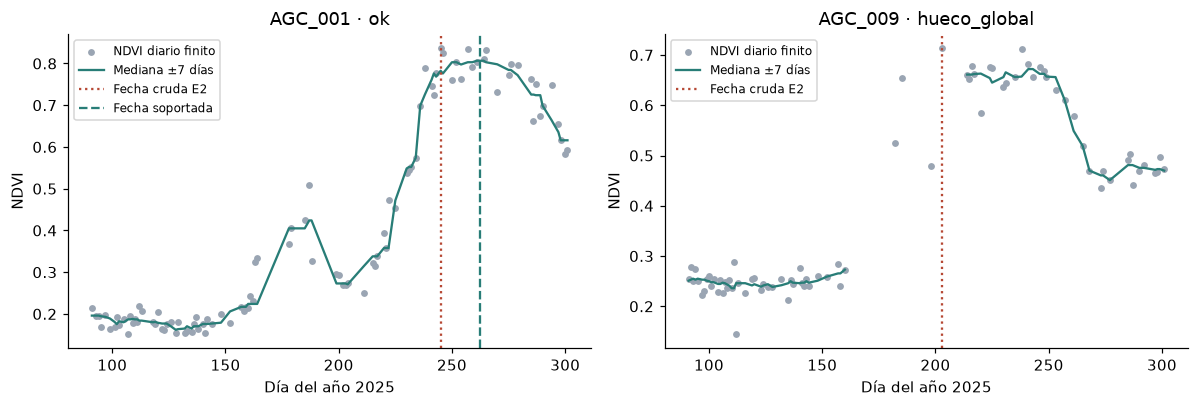

,C_PL_ndvi_doy_pico_prom,pico_soportado_doy,pico_meseta_inicio_doy,pico_meseta_fin_doy,estado_pico
ID_POLIGONO,,,,,
AGC_001,245,262.5,261.0,264.0,ok
AGC_009,203,NaN,241.0,243.0,hueco_global


In [9]:
NUM = ["C_PL_ndvi_media","C_PL_ndvi_pico_prom","C_PL_ndvi_doy_pico_prom",
       "C_S2_ndvi_media","C_S2_ndwi_media","C_LS_vi6t_media"]
PEAK = NUM[2]
fallo = descriptores.index[descriptores.estado_pico.ne("ok")][0]
fig,axes = plt.subplots(1,2,figsize=(11,3.8))
for ax,pid in zip(axes,["AGC_001",fallo]):
    d = diarios.loc[diarios.ID_POLIGONO.eq(pid)]
    c = curvas.loc[curvas.ID_POLIGONO.eq(pid)]
    ax.scatter(d.doy,d.ndvi_diario,s=12,color="#9aa5b3",label="NDVI diario finito")
    ax.plot(c.doy,c.ndvi_suavizado,color="#287d77",label="Mediana ±7 días")
    ax.axvline(grupos.loc[pid,PEAK],color="#b64834",ls=":",label="Fecha cruda E2")
    pico = descriptores.loc[pid,"pico_soportado_doy"]
    if pd.notna(pico): ax.axvline(pico,color="#287d77",ls="--",label="Fecha soportada")
    ax.set(xlabel="Día del año 2025",ylabel="NDVI",title=pid+" · "+descriptores.loc[pid,"estado_pico"])
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show()
display(pd.concat([grupos.loc[["AGC_001",fallo],[PEAK]],descriptores.loc[["AGC_001",fallo],
        ["pico_soportado_doy","pico_meseta_inicio_doy","pico_meseta_fin_doy","estado_pico"]]],axis=1))

## 4. Una sustitución, no otra familia de modelo

| Se conserva | Se cambia |
| --- | --- |
| Municipio, seis columnas numéricas y su orden | Contenido de la tercera columna: fecha de pico Planet |
| NDVI medio/máximo Planet, NDVI/NDWI medios Sentinel y vi6t medio Landsat | Fecha suavizada o NaN bajo receta fija |
| One-hot municipal + Ridge y alpha de cinco valores | No se agrega `estado_pico`, QA ni anchura |

La reconstrucción actual usa solo X. **39 NaN no eliminan parcelas**: en el
experimento original se imputaron mediante mediana dentro de cada entrenamiento.
Municipio one-hot **también fue penalizado** por Ridge: E2/V4 no usan las medias
municipales no penalizadas de las rondas de lluvia. Municipio desconocido =
one-hot en cero, no necesariamente predicción de media global.

In [10]:
base = fuente[["ID_POLIGONO","Municipio","Estado"]+NUM].copy()
alternativa = base.copy()
alternativa[PEAK] = alternativa.ID_POLIGONO.map(descriptores.pico_soportado_doy)
pd.testing.assert_frame_equal(base.drop(columns=PEAK),alternativa.drop(columns=PEAK),check_exact=True)
assert list(alternativa) == list(base) and "estado_pico" not in alternativa
assert alternativa[PEAK].isna().sum() == 39
conocido = alternativa.ID_POLIGONO.isin(etiquetas.ID_POLIGONO)
assert alternativa.loc[conocido,PEAK].notna().sum() == 108
assert alternativa.loc[~conocido,PEAK].notna().sum() == 50
finitos = alternativa[PEAK].notna()
iguales = np.isclose(alternativa.loc[finitos,PEAK],base.loc[finitos,PEAK],atol=1e-12,rtol=0)
assert int(iguales.sum()) == 8
display(pd.DataFrame({"columna":NUM,"unidad":["NDVI","NDVI","día del año","NDVI","NDWI","vi6t"],
                      "operacion":["conservar","conservar","sustituir","conservar","conservar","conservar"]}))
print("158 fechas disponibles: 150 cambian y 8 coinciden; 39 NaN se conservan, sin bandera predictora.")

,columna,unidad,operacion
0,C_PL_ndvi_media,NDVI,conservar
1,C_PL_ndvi_pico_prom,NDVI,conservar
2,C_PL_ndvi_doy_pico_prom,día del año,sustituir
3,C_S2_ndvi_media,NDVI,conservar
4,C_S2_ndwi_media,NDWI,conservar
5,C_LS_vi6t_media,vi6t,conservar


158 fechas disponibles: 150 cambian y 8 coinciden; 39 NaN se conservan, sin bandera predictora.


**Cómo se manejó cada pliegue original:** mediana numérica aprendida en
entrenamiento → imputación → StandardScaler (media y desviación de entrenamiento)
→ concatenar one-hot municipal sin escalar → Ridge con intercepto. En cada
pliegue interior se volvió a aprender todo sin sus filas de validación.
Si una columna carece de valores finitos en entrenamiento, se detiene; no se
borra la columna. El ejemplo siguiente es inventado y solo ilustra la regla.

In [11]:
x_train = np.array([100.,120.,np.nan,140.])
x_validacion = np.array([np.nan,200.])
mediana_train = np.nanmedian(x_train)
train_imputado = np.where(np.isnan(x_train),mediana_train,x_train)
validacion_imputada = np.where(np.isnan(x_validacion),mediana_train,x_validacion)
media_train,escala_train = train_imputado.mean(),train_imputado.std(ddof=0)
display(pd.DataFrame({"original_validacion":x_validacion,"imputado":validacion_imputada,
                      "estandarizado":(validacion_imputada-media_train)/escala_train}))
print("Ejemplo sintético: mediana",mediana_train,"; la validación no modifica mediana ni escala.")

,original_validacion,imputado,estandarizado
0,NaN,120.0,0.000000
1,200.0,200.0,5.656854


Ejemplo sintético: mediana 120.0 ; la validación no modifica mediana ni escala.


## 5. Particiones y selector sin cambiarlos por los resultados

Cinco pliegues × diez repeticiones; cuatro interiores por entrenamiento
exterior. Siempre parcela, nunca captura. Los CSV fijan exactamente quién
entrenó/validó, sin regenerar semillas. La disponibilidad se comprueba solo con X.

In [12]:
ids = set(etiquetas.ID_POLIGONO)
assert len(externas) == 6900 and len(internas) == 22080
assert not externas.duplicated(["repeticion", "pliegue", "ID_POLIGONO"]).any()
assert not internas.duplicated(["repeticion", "pliegue", "pliegue_interno", "ID_POLIGONO"]).any()
assert set(externas.rol) == set(internas.rol) == {"entrenamiento", "validacion"}
assert set(externas.repeticion) == set(range(10)) and set(externas.pliegue) == set(range(5))
assert set(internas.pliegue_interno) == set(range(4))
assert set(internas.groupby(["repeticion", "pliegue"]).groups) == set(externas.groupby(["repeticion", "pliegue"]).groups)
for (r, f), parte in externas.groupby(["repeticion", "pliegue"]):
    train_ids = set(parte.loc[parte.rol.eq("entrenamiento"), "ID_POLIGONO"])
    val_ids = set(parte.loc[parte.rol.eq("validacion"), "ID_POLIGONO"])
    assert train_ids.isdisjoint(val_ids) and train_ids | val_ids == ids
    dentro = internas.loc[internas.repeticion.eq(r) & internas.pliegue.eq(f)]
    assert set(dentro.ID_POLIGONO) == train_ids
    for _, iparte in dentro.groupby("pliegue_interno"):
        assert set(iparte.ID_POLIGONO) == train_ids
    frecuencia = dentro.loc[dentro.rol.eq("validacion")].groupby("ID_POLIGONO").size()
    assert set(frecuencia.index) == train_ids and frecuencia.eq(1).all()
claves = ["repeticion", "pliegue", "ID_POLIGONO"]
validaciones = externas.loc[externas.rol.eq("validacion"), claves].copy()
frecuencia = validaciones.groupby(["repeticion", "ID_POLIGONO"]).size()
assert len(validaciones) == len(frecuencia) == 1380 and frecuencia.eq(1).all()
ejemplo_roles = externas.loc[externas.repeticion.eq(0) & externas.pliegue.eq(0)]
display(ejemplo_roles.groupby("rol").size().rename("parcelas").to_frame())
display(internas.loc[internas.repeticion.eq(0) & internas.pliegue.eq(0)]
        .groupby(["pliegue_interno", "rol"]).size().rename("parcelas").to_frame())

,parcelas
rol,
entrenamiento,110
validacion,28


parcelas
pliegue_interno rol                    
0               entrenamiento        82
                validacion           28
1               entrenamiento        82
                validacion           28
2               entrenamiento        83
                validacion           27
3               entrenamiento        83
                validacion           27

In [13]:
alt = alternativa.set_index("ID_POLIGONO")
soportes = []
for _,roles in internas.groupby(["repeticion","pliegue","pliegue_interno"]):
    q = alt.loc[roles.loc[roles.rol.eq("entrenamiento"),"ID_POLIGONO"],NUM]
    if np.isinf(q.to_numpy(float)).any() or not np.isfinite(q.to_numpy(float)).any(axis=0).all():
        raise ValueError("Una columna no permite imputación en entrenamiento")
    soportes.append(int(q[PEAK].notna().sum()))
assert len(soportes) == 200 and min(soportes) == 59
print("Los 200 entrenamientos interiores tenían al menos",min(soportes),"picos finitos; no hay columna vacía.")

Los 200 entrenamientos interiores tenían al menos 59 picos finitos; no hay columna vacía.


Alpha ∈ {0.01, 0.1, 1, 10, 100}. Selector original: RMSE de los errores
interiores concatenados, **sin restringir a municipio visto**. Empate ≤1e−12:
alpha mayor. No incluye opción «baseline» ni pendiente cero como en lluvia.

Presupuesto histórico por corrida: E2 control 1,000 ajustes interiores +50
exteriores; V4 otros 1,000+50. Dos réplicas = **4,200 ajustes físicos**, no
4,200 variantes. Único candidato nuevo: V4. Aquí: **cero ajustes**.
Los scores guardados permiten verificar el selector, no recalcular sus errores:
no se guardaron residuos interiores individuales.

In [14]:
GRID = [.01,.1,1.,10.,100.]
SCORE_COLS = [f"rmse_interno_alpha_{a:g}" for a in GRID]
def seleccionar_alpha_guardado(df):
    req = ["modelo","repeticion","pliegue","alpha"]+SCORE_COLS
    if df.empty or not set(req) <= set(df) or df.duplicated(req[:3]).any():
        raise ValueError("Selección vacía, incompleta o repetida")
    scores = df[SCORE_COLS].to_numpy(float)
    if not np.isfinite(scores).all() or (scores < 0).any():
        raise ValueError("Scores no finitos o negativos")
    filas = []
    for _,r in df.iterrows():
        vals = r[SCORE_COLS].to_numpy(float)
        elegido = max(a for a,v in zip(GRID,vals) if v <= vals.min()+1e-12)
        filas.append({"modelo":r.modelo,"repeticion":int(r.repeticion),"pliegue":int(r.pliegue),"alpha_elegido":elegido})
    return pd.DataFrame(filas)

alphas = leer_csv("alphas","scores_guardados")
decisiones = seleccionar_alpha_guardado(alphas)
assert len(decisiones) == 100
assert set(map(tuple,decisiones[["modelo","repeticion","pliegue"]].to_numpy())) == {(m,r,f) for m in ["E2","V4"] for r in range(10) for f in range(5)}
np.testing.assert_array_equal(decisiones.alpha_elegido,alphas.alpha)
old_a = leer_csv("e2_alpha","scores_guardados").query("modelo == 'E2'").set_index(["repeticion","pliegue"]).sort_index()
new_a = alphas.query("modelo == 'E2'").set_index(["repeticion","pliegue"]).sort_index()
assert len(old_a) == 50 and old_a.index.equals(new_a.index)
np.testing.assert_array_equal(new_a.alpha,old_a.alpha)
np.testing.assert_allclose(new_a[SCORE_COLS],old_a[SCORE_COLS],atol=1e-8,rtol=0)
assert PRE["ajustes_fisicos_programados"] == 4200 and REG["presupuesto"]["total_ajustes"] == 2100
display(decisiones.groupby(["modelo","alpha_elegido"]).size().rename("pliegues").to_frame())
print("100 decisiones / 500 scores verificados; 50 controles E2 conciliados, sin reaprender.")

pliegues
modelo alpha_elegido          
E2     0.01                  6
       0.10                 37
       1.00                  7
V4     0.01                  9
       0.10                 33
       1.00                  8

100 decisiones / 500 scores verificados; 50 controles E2 conciliados, sin reaprender.


## 6. OOF y escenario de evaluación

**SEEN135** es el escenario principal declarado: municipio presente en el
entrenamiento exterior. Se construye con roles/metadatos, nunca errores;
igual para los cinco procedimientos. FULL138 sigue visible. No se retiran
las tres etiquetas singleton del entrenamiento: sus 30 OOF solo quedan
fuera del puntaje principal. Repetir diez veces no crea nuevas etiquetas.
Las referencias se concilian a tolerancia absoluta 1e−12: su lectura y
serialización histórica dejaron diferencias del último dígito (≤9e−16),
no cambios en los procedimientos. Los archivos originales se conservan.

In [15]:
MODELOS = ["GLOBAL","MUN","MIX","E2","V4"]
oof = leer_csv("oof","resultados_guardados")
assert len(oof) == 6900 and set(oof.modelo) == set(MODELOS)
assert not oof.duplicated(["modelo"]+claves).any()
esperado = set(map(tuple,validaciones[claves].to_numpy()))
y = etiquetas.set_index("ID_POLIGONO").RENDIMIENTO_T_HA
for m,q in oof.groupby("modelo"):
    assert len(q) == 1380 and set(map(tuple,q[claves].to_numpy())) == esperado
    assert q.ID_POLIGONO.nunique() == 138 and np.isfinite(q.predicho).all()
    np.testing.assert_array_equal(q.observado,q.ID_POLIGONO.map(y))
    np.testing.assert_array_equal(q.Municipio,q.ID_POLIGONO.map(grupos.Municipio))
viejo = leer_csv("e2_oof","resultados_guardados").query("modelo == 'E2'").set_index(claves).sort_index()
nuevo = oof.query("modelo == 'E2'").set_index(claves).sort_index()
assert nuevo.index.equals(viejo.index)
np.testing.assert_array_equal(nuevo.observado,viejo.observado)
np.testing.assert_allclose(nuevo.predicho,viejo.predicho,atol=1e-8,rtol=0)
refs = leer_csv("referencias","resultados_guardados")
refs["modelo"] = refs.modelo.map({"Media global":"GLOBAL","Media municipal":"MUN","Municipio + IDW fijo":"MIX"})
assert refs.modelo.notna().all()
for m in ["GLOBAL","MUN","MIX"]:
    a = oof.loc[oof.modelo.eq(m)].set_index(claves).sort_index()
    b = refs.loc[refs.modelo.eq(m)].set_index(claves).sort_index()
    assert a.index.equals(b.index)
    np.testing.assert_array_equal(a.observado,b.observado)
    np.testing.assert_allclose(a.predicho,b.predicho,atol=1e-12,rtol=0)
d = oof.loc[oof.modelo.isin(["E2","V4"])].merge(decisiones,on=["modelo","repeticion","pliegue"],validate="many_to_one")
np.testing.assert_array_equal(d.alpha,d.alpha_elegido)
mask_rows = []
for (r,f),q in externas.groupby(["repeticion","pliegue"]):
    mun_train = set(q.loc[q.rol.eq("entrenamiento"),"ID_POLIGONO"].map(grupos.Municipio))
    v = q.loc[q.rol.eq("validacion"),claves].copy()
    v["municipio_visto"] = v.ID_POLIGONO.map(grupos.Municipio).isin(mun_train)
    mask_rows.append(v)
mascara = pd.concat(mask_rows,ignore_index=True)
assert len(mascara) == 1380 and int(mascara.municipio_visto.sum()) == 1350
check = oof.merge(mascara,on=claves,validate="many_to_one",suffixes=("_guardado",""))
np.testing.assert_array_equal(check.municipio_visto_guardado,check.municipio_visto)
seen = oof.loc[oof.municipio_visto].copy()
assert len(seen) == 6750 and seen.ID_POLIGONO.nunique() == 135
ESCENARIOS = {"SEEN135":seen,"FULL138":oof}
display(mascara.groupby("municipio_visto").agg(oof=("ID_POLIGONO","size"),parcelas=("ID_POLIGONO","nunique")))
print("E2 y referencias preservados; máscaras comunes e idénticas. No se han recalculado predicciones.")

,oof,parcelas
municipio_visto,,
False,30,3
True,1350,135


E2 y referencias preservados; máscaras comunes e idénticas. No se han recalculado predicciones.


## 7. Comparación agrupada y estabilidad

Cada error OOF participa: no se promedian primero las diez predicciones por
parcela ni los RMSE de pliegues. RMSE/MAE en t/ha; R² adimensional, no definido
cuando la varianza del objetivo es degenerada. Los 6,900 errores son repeticiones
de 138 parcelas y cinco procedimientos, no observaciones independientes.
Guarda numérica de este lector: R² no definido si SST≤1e−12; el motor histórico
usó SST>0. Ninguna población real de estos controles cambia por esa precisión.

,n_parcelas,n_oof,RMSE,MAE,R2
modelo,,,,,
GLOBAL,135.0,1350.0,0.849706,0.749176,-0.015837
MUN,135.0,1350.0,0.493404,0.321274,0.657475
MIX,135.0,1350.0,0.487197,0.334215,0.666039
E2,135.0,1350.0,0.506498,0.347390,0.639053
V4,135.0,1350.0,0.501458,0.347624,0.646202


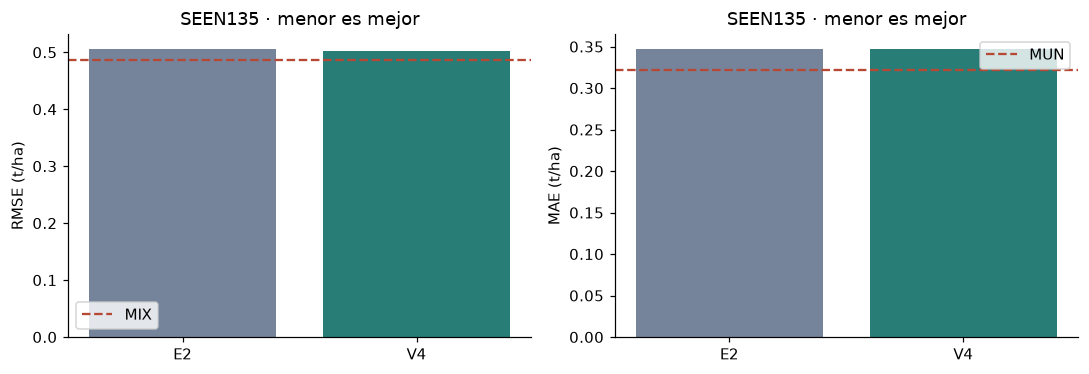

In [16]:
def metricas(df):
    y,p = df.observado.to_numpy(float),df.predicho.to_numpy(float)
    if len(y) == 0 or not np.isfinite(y).all() or not np.isfinite(p).all():
        raise ValueError("Métricas vacías o no finitas")
    e = p-y; sst = np.sum((y-y.mean())**2)
    return pd.Series({"n_oof":len(df),"n_parcelas":df.ID_POLIGONO.nunique(),
                      "RMSE":np.sqrt(np.mean(e**2)),"MAE":np.mean(np.abs(e)),
                      "R2":1-np.sum(e**2)/sst if sst > 1e-12 else np.nan})

def contrastar(tabla,control,keys):
    a,b = tabla.set_index(keys).sort_index(),control.set_index(keys).sort_index()
    assert a.index.equals(b.index)
    nums = a.select_dtypes(include="number").columns
    np.testing.assert_allclose(a[nums],b[nums],atol=1e-12,rtol=0,equal_nan=True)
    for c in a.columns.difference(nums):
        np.testing.assert_array_equal(a[c].fillna("<NA>"),b[c].fillna("<NA>"))

metricas_esc = pd.DataFrame([{"escenario":s,"modelo":m,**metricas(q).to_dict()}
                          for s,df in ESCENARIOS.items() for m,q in df.groupby("modelo")])
por_rep = pd.DataFrame([{"escenario":s,"modelo":m,"repeticion":r,**metricas(q).to_dict()}
                       for s,df in ESCENARIOS.items() for (m,r),q in df.groupby(["modelo","repeticion"])])
contrastar(metricas_esc,leer_csv("metricas_control","control_posterior"),["escenario","modelo"])
contrastar(por_rep,leer_csv("repeticiones_control","control_posterior"),["escenario","modelo","repeticion"])
principales = metricas_esc.loc[metricas_esc.escenario.eq("SEEN135")].set_index("modelo").reindex(MODELOS)
full = metricas_esc.loc[metricas_esc.escenario.eq("FULL138")].set_index("modelo").reindex(MODELOS)
display(principales[["n_parcelas","n_oof","RMSE","MAE","R2"]])
fig,axes = plt.subplots(1,2,figsize=(10,3.5))
for ax,met,ref in zip(axes,["RMSE","MAE"],["MIX","MUN"]):
    ax.bar(["E2","V4"],principales.loc[["E2","V4"],met],color=["#75849b","#287d77"])
    ax.axhline(principales.loc[ref,met],ls="--",color="#b64834",label=ref)
    ax.set(ylabel=f"{met} (t/ha)",title="SEEN135 · menor es mejor"); ax.legend()
fig.tight_layout(); plt.show()

Regla interna de avance, no puntuación oficial ni test de significación:
RMSE<MIX y MAE≤MUN agrupados, cada condición en ≥8/10 repeticiones.
Mejorar E2 explica el contraste, pero no basta para adoptar el candidato.

In [17]:
def regla_avance(df):
    g = pd.DataFrame({m:metricas(q) for m,q in df.groupby("modelo")}).T
    reps = pd.DataFrame([{"modelo":m,"repeticion":r,**metricas(q).to_dict()}
                         for (m,r),q in df.groupby(["modelo","repeticion"])])
    R = reps.pivot(index="repeticion",columns="modelo",values="RMSE")
    A = reps.pivot(index="repeticion",columns="modelo",values="MAE")
    if set(R.index) != set(range(10)) or set(R.columns) != set(MODELOS) or R.isna().any().any() or A.isna().any().any():
        raise ValueError("Repeticiones/modelos incompletos")
    nr,na = int((R.V4<R.MIX).sum()),int((A.V4<=A.MUN).sum())
    return {"mejora_E2_RMSE":bool(g.loc["V4","RMSE"]<g.loc["E2","RMSE"]),
            "mejora_E2_repeticiones":int((R.V4<R.E2).sum()),
            "supera_MIX_RMSE_agrupado":bool(g.loc["V4","RMSE"]<g.loc["MIX","RMSE"]),
            "no_empeora_MUN_MAE_agrupado":bool(g.loc["V4","MAE"]<=g.loc["MUN","MAE"]),
            "rep_RMSE_mejor_MIX":nr,"rep_MAE_no_peor_MUN":na,
            "cumple_regla":bool(g.loc["V4","RMSE"]<g.loc["MIX","RMSE"] and g.loc["V4","MAE"]<=g.loc["MUN","MAE"] and nr>=8 and na>=8)}

decision = {"escenario_principal":"SEEN135",**regla_avance(seen)}
assert decision == REG["decision"] and not decision["cumple_regla"]
display(pd.DataFrame([decision]))
print("ΔRMSE V4−E2:",float(principales.loc["V4","RMSE"]-principales.loc["E2","RMSE"]),"t/ha")
print("9/10 frente a E2; 0/10 frente a MIX; 0/10 MAE≤MUN. Cerrar sin adopción.")
display(full[["RMSE","MAE","R2"]].rename_axis("FULL138: modelo"))

,escenario_principal,mejora_E2_RMSE,mejora_E2_repeticiones,supera_MIX_RMSE_agrupado,no_empeora_MUN_MAE_agrupado,rep_RMSE_mejor_MIX,rep_MAE_no_peor_MUN,cumple_regla
0,SEEN135,True,9,False,False,0,0,False


ΔRMSE V4−E2: -0.005040732393332803 t/ha
9/10 frente a E2; 0/10 frente a MIX; 0/10 MAE≤MUN. Cerrar sin adopción.


,RMSE,MAE,R2
FULL138: modelo,,,
GLOBAL,0.854426,0.753994,-0.015043
MUN,0.511757,0.335394,0.635865
MIX,0.493845,0.341711,0.660908
E2,0.519202,0.359676,0.625193
V4,0.514165,0.359747,0.632429


## 8. Territorio y concentración de la mejora

Chignahuapan concentra 71 etiquetas: E2 0.6033 → V4 0.6009 RMSE, todavía
detrás de MIX 0.5736; el MAE aumenta. No se resolvió la variación interna.
Ganancia SSE = error² de referencia menos error² de V4. Sumar por parcela
conserva diez errores; fracción positiva bruta no es porcentaje de ganancia neta.

Retirar las parcelas más favorecidas **solo al evaluar** es sensibilidad
registrada, no nuevo entrenamiento ni permiso para borrar datos. Los controles
se leen después del cálculo; las exclusiones no seleccionan el modelo.

In [18]:
zonas = pd.DataFrame([{"escenario":s,"modelo":m,"region":z,**metricas(a).to_dict()}
                     for s,df in ESCENARIOS.items() for m,g in df.groupby("modelo")
                     for z,a in [("Chignahuapan",g.loc[g.Municipio.eq("Chignahuapan")]),("Resto",g.loc[~g.Municipio.eq("Chignahuapan")])]])
contrastar(zonas,leer_csv("region_control","control_posterior"),["escenario","modelo","region"])
conc,sens = [],[]
for s,df in ESCENARIOS.items():
    for m,g in df.groupby("modelo"):
        sens.append({"escenario":s,"modelo":m,"sensibilidad":"sin_AGC_127_171",
                     **metricas(g.loc[~g.ID_POLIGONO.isin(["AGC_127","AGC_171"])]).to_dict()})
    for comp in ["E2","MIX"]:
        p = df.loc[df.modelo.eq("V4")].merge(df.loc[df.modelo.eq(comp)],on=claves,suffixes=("_v4","_ref"),validate="one_to_one")
        np.testing.assert_array_equal(p.observado_v4,p.observado_ref)
        gain = (p.predicho_ref-p.observado_ref)**2-(p.predicho_v4-p.observado_v4)**2
        byplot = pd.DataFrame({"ID_POLIGONO":p.ID_POLIGONO,"gain":gain}).groupby("ID_POLIGONO").gain.sum().sort_values(ascending=False)
        positivo,neto = float(byplot.clip(lower=0).sum()),float(byplot.sum())
        for n in [2,5]:
            ids = byplot.head(n).index.tolist()
            conc.append({"escenario":s,"comparador":comp,"top_n":n,"ids":";".join(ids),
                         "ganancia_sse_neta":neto,"ganancia_sse_top":float(byplot.head(n).sum()),
                         "fraccion_ganancia_positiva_top":float(byplot.head(n).clip(lower=0).sum()/positivo) if positivo>0 else np.nan})
            for m in ["V4",comp]:
                a = df.loc[df.modelo.eq(m)&~df.ID_POLIGONO.isin(ids)]
                sens.append({"escenario":s,"modelo":m,"sensibilidad":f"sin_top{n}_favorables_V4_vs_{comp}",**metricas(a).to_dict()})
concentracion,sensibilidad = pd.DataFrame(conc),pd.DataFrame(sens)
contrastar(concentracion,leer_csv("concentracion_control","control_posterior"),["escenario","comparador","top_n"])
contrastar(sensibilidad,leer_csv("sensibilidad_control","control_posterior"),["escenario","modelo","sensibilidad"])
display(zonas.loc[zonas.escenario.eq("SEEN135"),["modelo","region","n_parcelas","RMSE","MAE"]])
display(concentracion.loc[concentracion.escenario.eq("SEEN135")])
display(sensibilidad.loc[sensibilidad.escenario.eq("SEEN135")&sensibilidad.sensibilidad.eq("sin_top5_favorables_V4_vs_E2")])
print("Las cinco más favorecidas aportan más SSE que la mejora neta; sin ellas se invierte V4/E2.")

,modelo,region,n_parcelas,RMSE,MAE
0,E2,Chignahuapan,71.0,0.603285,0.399641
1,E2,Resto,64.0,0.370649,0.289424
2,GLOBAL,Chignahuapan,71.0,0.786687,0.674407
3,GLOBAL,Resto,64.0,0.914550,0.832123
4,MIX,Chignahuapan,71.0,0.573628,0.389104
5,MIX,Resto,64.0,0.368299,0.273322
6,MUN,Chignahuapan,71.0,0.590198,0.381019
7,MUN,Resto,64.0,0.356496,0.254994
8,V4,Chignahuapan,71.0,0.600949,0.403576
9,V4,Resto,64.0,0.360255,0.285552


,escenario,comparador,top_n,ids,ganancia_sse_neta,ganancia_sse_top,fraccion_ganancia_positiva_top
0,SEEN135,E2,2,AGC_185;AGC_069,6.859131,3.832000,0.160708
1,SEEN135,E2,5,AGC_185;AGC_069;AGC_152;AGC_049;AGC_160,6.859131,8.662919,0.363308
2,SEEN135,MIX,2,AGC_015;AGC_133,-19.034232,9.367362,0.190863
3,SEEN135,MIX,5,AGC_015;AGC_133;AGC_069;AGC_058;AGC_145,-19.034232,18.252066,0.371892


,escenario,modelo,sensibilidad,n_oof,n_parcelas,RMSE,MAE,R2
7,SEEN135,V4,sin_top5_favorables_V4_vs_E2,1300.0,130.0,0.489731,0.333964,0.650120
8,SEEN135,E2,sin_top5_favorables_V4_vs_E2,1300.0,130.0,0.488312,0.328879,0.652145


Las cinco más favorecidas aportan más SSE que la mejora neta; sin ellas se invierte V4/E2.


## 9. Disponibilidad en las 59 ocultas, sin predecirlas

Hay 50 fechas soportadas y nueve ausentes. Cuatro fechas quedan fuera del
rango municipal etiquetado; rango univariado no equivale a soporte multivariado
ni proporciona precisión. Cuautepec tiene cinco etiquetas pero solo un pico
disponible; sus cuatro ocultas carecen de pico. Nanacamilpa tiene una etiqueta
y AGC_120 oculta: SEEN135 no evalúa ese caso. No inventamos su incertidumbre.

In [19]:
train_x = alternativa.loc[alternativa.ID_POLIGONO.isin(etiquetas.ID_POLIGONO)]
hidden_x = alternativa.loc[~alternativa.ID_POLIGONO.isin(etiquetas.ID_POLIGONO)]
rows = []
for _,h in hidden_x.iterrows():
    a = train_x.loc[train_x.Municipio.eq(h.Municipio)]; vals = a[PEAK].dropna(); v = h[PEAK]
    rows.append({"ID_POLIGONO":h.ID_POLIGONO,"Municipio":h.Municipio,
                 "n_etiquetas_municipio":len(a),"n_picos_soportados_municipio":len(vals),
                 "pico_soportado_doy":float(v) if pd.notna(v) else np.nan,"pico_ausente":bool(pd.isna(v)),
                 "fuera_rango_municipal":bool(v<vals.min() or v>vals.max()) if pd.notna(v) and len(vals) else None,
                 "caso_singleton":bool(len(a)==1)})
soporte = pd.DataFrame(rows)
contrastar(soporte,leer_csv("soporte_control","control_posterior"),["ID_POLIGONO"])
assert len(soporte) == 59 and int(soporte.pico_ausente.sum()) == 9 and int(soporte.caso_singleton.sum()) == 1
assert int(soporte.fuera_rango_municipal.eq(True).sum()) == 4
display(soporte.groupby("Municipio").agg(ocultas=("ID_POLIGONO","size"),pico_ausente=("pico_ausente","sum"),
        etiquetas=("n_etiquetas_municipio","first"),picos_etiquetados=("n_picos_soportados_municipio","first")))
print("Solo X y presencia de etiquetas, ningún rendimiento oculto calculado.")

,ocultas,pico_ausente,etiquetas,picos_etiquetados
Municipio,,,,
Almoloya,4,0,10,8
Calpulalpan,14,0,30,27
Chignahuapan,29,4,71,52
Cuautepec de Hinojosa,4,4,5,1
Nanacamilpa de Mariano Arista,1,0,1,1
Singuilucan,7,1,16,14


Solo X y presencia de etiquetas, ningún rendimiento oculto calculado.


## 10. Cierre del experimento y del recorrido histórico

- **Cerrar V4 sin adopción:** mejora pequeña frente a E2 (≈0.005 t/ha en RMSE),
  con MAE ligeramente peor y sin superar MUN/MIX bajo la regla declarada.
- El contraste cambia conjuntamente suavizado, guardas y faltantes. No aísla
  la contribución de cada componente ni demuestra precisión fenológica.
- No demuestra que Planet, fenología o Ridge sean inútiles: se evaluó esta
  única sustitución, esta ventana, estas seis variables y una sola campaña.
- Conservar las referencias simples y diagnósticos por territorio. Curvas
  más interpretables no sustituyen desempeño fuera de muestra.

Esta lectura completa las **seis rondas históricas centralizadas**. Recalcular
variables, métricas y decisiones no es una nueva prueba independiente ni
demuestra paridad de reentrenamiento Python 3.12/3.13. Una siguiente hipótesis
requiere decisión y registro propios; este cuaderno no la ejecuta automáticamente.
Las 46 pruebas sintéticas del registro original no se presentan como ejecutadas aquí.

In [20]:
resumen = {"id":"EXP_06","modo":"lector_retrospectivo_sin_ajustes","parcelas":197,"etiquetas":138,
           "capturas_incorporadas":26255,"dias_diarios_recalculados":26255,"curva_puntos":18248,
           "picos_recalculados":197,"picos_soportados":158,"picos_ausentes":39,
           "picos_soportados_etiquetados":108,"picos_soportados_ocultos":50,
           "columnas_sustituidas":1,"columnas_numericas":6,"bandera_como_predictor":False,
           "anchuras_recalculadas":False,"otras_variables_recalculadas":False,
           "procedimientos":5,"candidatos":1,"oof_total":6900,"oof_por_procedimiento":1380,
           "particiones_externas":50,"particiones_internas":200,"decisiones_verificadas":100,
           "scores_guardados_verificados":500,"controles_alpha_E2":50,
           "ajustes_actuales":0,"predicciones_finales_generadas":0,"predicciones_recalculadas":False,
           "scores_interiores_recalculados":False,"metricas_recalculadas":True,
           "poblacion":"SEEN135","oof_seen_por_procedimiento":1350,"poblacion_secundaria":"FULL138",
           "regla_seen_cumplen":[],"variantes_adoptadas":[],"decision":decision,
           "soporte_ocultas_ausentes":9,"soporte_ocultas_fuera_rango":4,"soporte_ocultas_singleton":1,
           "fecha_original":"2026-10-06","fecha_factibilidad":"2026-10-02","fecha_adaptacion":"2026-10-08",
           "metricas_seen":principales[["RMSE","MAE","R2"]].to_dict(orient="index"),
           "metricas_full":full[["RMSE","MAE","R2"]].to_dict(orient="index"),
           "fecha_ejecucion_utc":datetime.now(timezone.utc).isoformat()}
print("RESUMEN_EXP_06_JSON="+json.dumps(resumen,sort_keys=True,ensure_ascii=False,allow_nan=False))

RESUMEN_EXP_06_JSON={"ajustes_actuales": 0, "anchuras_recalculadas": false, "bandera_como_predictor": false, "candidatos": 1, "capturas_incorporadas": 26255, "columnas_numericas": 6, "columnas_sustituidas": 1, "controles_alpha_E2": 50, "curva_puntos": 18248, "decision": {"cumple_regla": false, "escenario_principal": "SEEN135", "mejora_E2_RMSE": true, "mejora_E2_repeticiones": 9, "no_empeora_MUN_MAE_agrupado": false, "rep_MAE_no_peor_MUN": 0, "rep_RMSE_mejor_MIX": 0, "supera_MIX_RMSE_agrupado": false}, "decisiones_verificadas": 100, "dias_diarios_recalculados": 26255, "etiquetas": 138, "fecha_adaptacion": "2026-10-08", "fecha_ejecucion_utc": "2026-10-08T16:07:15.081670+00:00", "fecha_factibilidad": "2026-10-02", "fecha_original": "2026-10-06", "id": "EXP_06", "metricas_full": {"E2": {"MAE": 0.3596758963638445, "R2": 0.6251928722045933, "RMSE": 0.5192018945322401}, "GLOBAL": {"MAE": 0.7539942301985781, "R2": -0.015042909859176445, "RMSE": 0.854426183817986}, "MIX": {"MAE": 0.341710715243

## Referencias y conceptos para profundizar (APA 7)

Equipo AgroCebada. (2026, 2 de octubre). *Receta de factibilidad fenológica V4*
[Registro interno]. Equipo AgroCebada. (2026, 6 de octubre). *V4: sustitución de
fecha de pico NDVI en E2* [Protocolo exploratorio]. Recetas y resultados están
incorporados, sin necesidad de consultar otro documento.

U.S. Geological Survey. (s. f.). *Methods for deriving metrics*.
https://www.usgs.gov/special-topics/remote-sensing-phenology/science/methods-deriving-metrics
Fuente de contexto sobre métricas de series de vegetación, no validación de
nuestras guardas o de su aplicación a cebada.

scikit-learn developers. (s. f.). *Pipeline*.
https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

Cawley, G. C., & Talbot, N. L. C. (2010). On over-fitting in model selection and
subsequent selection bias in performance evaluation. *Journal of Machine Learning
Research, 11*, 2079–2107. https://jmlr.org/papers/v11/cawley10a.html

**Glosario:** DOY = día del año; mediana móvil = centro robusto de valores en una
ventana; meseta = máximos empatados según tolerancia; censura = pico sin margen
temporal suficiente; guarda = regla para no liberar un descriptor sin soporte;
imputación = reemplazar NaN con una regla aprendida en entrenamiento; OOF =
predicción fuera de muestra; SSE = suma de errores cuadrados; SEEN135 = municipio
presente en entrenamiento, no muestra nueva ni cobertura completa de la entrega.